# Beyond Predictive Performance: SHAP-Based Explanations and Alignment with Literature-Based Indicators in Code Smell Detection



## 1. Entorno y datos

Los datos originales (`OnlineExperimentsData.rar`) y los resultados experimentales no están incluidos en el cuaderno. Ajustar las rutas de entrada y salida antes de ejecutarlo en Google Colab.

In [4]:
!pip -q install "shap==0.52.0"

import os
import re
import io
import json
import time
import math
import shutil
import hashlib
import warnings
import platform
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.stats import pointbiserialr, spearmanr, mannwhitneyu

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix,
)

import shap
import joblib
import sklearn

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)


Python: 3.13.16
NumPy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1
SHAP: 0.52.0


In [5]:
PROTOCOL_VERSION = "Ptidej_XAI_SHAP_v1_5"
SEED = 42

PROJECTS = ["Azureus", "ArgoUML", "Xerces"]
SMELLS = ["BLOB", "FD", "SAK", "SC"]
EXPECTED_FOLDS = list(range(1, 11))
EXPECTED_N_FEATURES = 50

SHAP_BACKGROUND_SIZE = 50
SHAP_TOP_K = 5
SHAP_PERMUTATION_CYCLES = 3
SHAP_OUTPUT = "decision_function"

SHAP_SENSITIVITY_FOLD = 1
SHAP_SENSITIVITY_SEED_OFFSETS = [0, 10000, 20000]

REPRO_METRIC_TOL = 5e-5
ADDITIVITY_TOL = 1e-5

SAVE_MODELS = False

RAR_PATH = Path("/content/drive/MyDrive/OnlineExperimentsData.rar")
BASE_DIR = Path("/content/raw_maiga/OnlineExperimentsData/10-FoldCrossValidationIntraSystem")

OUTPUT_DIR = Path("/content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5")
FOLD_RUNS_DIR = OUTPUT_DIR / "fold_runs"
FIG_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"

PROJECT_INDEX = {p: i for i, p in enumerate(PROJECTS)}
SMELL_INDEX = {s: i for i, s in enumerate(SMELLS)}

def fold_seed(project: str, smell: str, fold: int) -> int:
    return SEED + 1000 * PROJECT_INDEX[project] + 100 * SMELL_INDEX[smell] + int(fold)

print("Salida:", OUTPUT_DIR)


Salida: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5


In [6]:
from google.colab import drive
drive.mount("/content/drive")

def ensure_dataset_present() -> None:
    if BASE_DIR.exists():
        print("✓ Dataset presente:", BASE_DIR)
        return

    if not RAR_PATH.exists():
        raise FileNotFoundError(
            f"No existe {RAR_PATH}. Coloca OnlineExperimentsData.rar en MyDrive "
            "o modifica RAR_PATH antes de ejecutar."
        )

    os.makedirs("/content/raw_maiga", exist_ok=True)

    if os.system("which unrar > /dev/null 2>&1") != 0:
        os.system("apt-get -qq update >/dev/null 2>&1")
        os.system("apt-get -qq install -y unrar >/dev/null 2>&1")

    print("→ Extrayendo dataset...")
    rc = os.system(f'unrar x -y "{RAR_PATH}" /content/raw_maiga/ >/dev/null')
    if rc != 0 or not BASE_DIR.exists():
        raise RuntimeError("No se pudo extraer el dataset en la ruta esperada.")

    print("✓ Extracción correcta")

ensure_dataset_present()

for d in [OUTPUT_DIR, FOLD_RUNS_DIR, FIG_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

for project in PROJECTS:
    p = BASE_DIR / project
    if not p.exists():
        raise FileNotFoundError(f"Falta proyecto: {p}")
    print(project, "✓")


Mounted at /content/drive
→ Extrayendo dataset...
✓ Extracción correcta
Azureus ✓
ArgoUML ✓
Xerces ✓


## 2. Configuraciones y operacionalizaciones (GC, FD, SAK y SC)


In [7]:
BASELINE_MANIFEST_CSV = r"""project,smell,fold,C,degree,gamma,kernel,expected_n_train,expected_n_test,expected_accuracy,expected_precision,expected_recall,expected_f1,expected_roc_auc,expected_tn,expected_fp,expected_fn,expected_tp
ArgoUML,BLOB,1,1.0,2,scale,rbf,53,21,0.904762,0.909091,0.909091,0.909091,0.990909,9,1,1,10
ArgoUML,BLOB,2,0.1,3,0.1,poly,54,20,0.95,1.0,0.9,0.947368,1.0,10,0,1,9
ArgoUML,BLOB,3,0.1,3,0.1,poly,54,20,1.0,1.0,1.0,1.0,1.0,10,0,0,10
ArgoUML,BLOB,4,1.0,2,scale,rbf,54,20,0.9,0.9,0.9,0.9,0.99,9,1,1,9
ArgoUML,BLOB,5,0.1,3,0.1,poly,54,20,1.0,1.0,1.0,1.0,1.0,10,0,0,10
ArgoUML,BLOB,6,1.0,2,0.01,rbf,54,20,0.95,1.0,0.9,0.947368,0.99,10,0,1,9
ArgoUML,BLOB,7,0.1,3,0.1,poly,54,20,1.0,1.0,1.0,1.0,1.0,10,0,0,10
ArgoUML,BLOB,8,10.0,2,scale,rbf,54,20,0.8,0.875,0.7,0.777778,0.96,9,1,3,7
ArgoUML,BLOB,9,1.0,2,scale,rbf,54,20,1.0,1.0,1.0,1.0,1.0,10,0,0,10
ArgoUML,BLOB,10,1.0,2,scale,rbf,54,20,0.95,1.0,0.9,0.947368,0.99,10,0,1,9
ArgoUML,FD,1,10.0,2,0.1,rbf,44,16,0.625,0.625,0.625,0.625,0.578125,5,3,3,5
ArgoUML,FD,2,1.0,3,0.1,poly,44,16,0.625,0.75,0.375,0.5,0.765625,7,1,5,3
ArgoUML,FD,3,1.0,2,0.1,rbf,44,16,0.6875,0.666667,0.75,0.705882,0.734375,5,3,2,6
ArgoUML,FD,4,1.0,3,0.1,poly,44,16,0.75,0.75,0.75,0.75,0.828125,6,2,2,6
ArgoUML,FD,5,1.0,3,0.1,poly,44,16,0.625,0.6,0.75,0.666667,0.734375,4,4,2,6
ArgoUML,FD,6,1.0,2,0.1,rbf,44,16,0.625,0.625,0.625,0.625,0.671875,5,3,3,5
ArgoUML,FD,7,10.0,3,0.1,poly,44,16,0.75,0.833333,0.625,0.714286,0.71875,7,1,3,5
ArgoUML,FD,8,1.0,2,0.1,rbf,44,16,0.75,0.7,0.875,0.777778,0.734375,5,3,1,7
ArgoUML,FD,9,1.0,2,0.1,rbf,44,16,0.6875,0.666667,0.75,0.705882,0.8125,5,3,2,6
ArgoUML,FD,10,1.0,2,0.1,rbf,44,16,0.6875,0.666667,0.75,0.705882,0.75,5,3,2,6
ArgoUML,SAK,1,1.0,2,0.1,rbf,34,14,0.571429,0.538462,1.0,0.7,0.938776,1,6,0,7
ArgoUML,SAK,2,0.1,4,0.1,poly,34,14,0.642857,0.666667,0.571429,0.615385,0.663265,5,2,3,4
ArgoUML,SAK,3,0.1,2,0.1,poly,34,14,0.714286,0.714286,0.714286,0.714286,0.795918,5,2,2,5
ArgoUML,SAK,4,0.1,3,0.1,poly,34,14,0.5,0.5,0.714286,0.588235,0.612245,2,5,2,5
ArgoUML,SAK,5,1.0,2,0.1,poly,34,14,0.714286,0.714286,0.714286,0.714286,0.816327,5,2,2,5
ArgoUML,SAK,6,1.0,2,0.1,poly,34,14,0.5,0.5,0.857143,0.631579,0.387755,1,6,1,6
ArgoUML,SAK,7,1.0,2,auto,rbf,34,14,0.714286,0.714286,0.714286,0.714286,0.877551,5,2,2,5
ArgoUML,SAK,8,1.0,2,scale,rbf,34,14,0.928571,1.0,0.857143,0.923077,0.877551,7,0,1,6
ArgoUML,SAK,9,1.0,3,0.1,poly,34,14,0.928571,0.875,1.0,0.933333,0.918367,6,1,0,7
ArgoUML,SAK,10,100.0,2,0.001,rbf,34,14,0.857143,0.777778,1.0,0.875,0.938776,5,2,0,7
ArgoUML,SC,1,1.0,3,0.1,poly,76,30,0.866667,0.823529,0.933333,0.875,0.902222,12,3,1,14
ArgoUML,SC,2,1.0,3,0.1,poly,76,30,0.733333,0.705882,0.8,0.75,0.688889,10,5,3,12
ArgoUML,SC,3,1.0,3,0.1,poly,76,30,0.8,0.846154,0.733333,0.785714,0.8,13,2,4,11
ArgoUML,SC,4,1.0,2,scale,rbf,76,30,0.7,0.714286,0.666667,0.689655,0.813333,11,4,5,10
ArgoUML,SC,5,10.0,4,0.1,poly,76,30,0.7,0.75,0.6,0.666667,0.866667,12,3,6,9
ArgoUML,SC,6,1.0,2,0.1,rbf,76,30,0.9,0.875,0.933333,0.903226,0.96,13,2,1,14
ArgoUML,SC,7,10.0,2,scale,rbf,76,30,0.733333,0.888889,0.533333,0.666667,0.942222,14,1,7,8
ArgoUML,SC,8,1.0,2,0.1,rbf,76,30,0.7,0.65,0.866667,0.742857,0.795556,8,7,2,13
ArgoUML,SC,9,1.0,3,0.1,poly,76,30,0.7,0.714286,0.666667,0.689655,0.797778,11,4,5,10
ArgoUML,SC,10,100.0,3,auto,poly,76,30,0.733333,1.0,0.466667,0.636364,0.911111,15,0,8,7
Azureus,BLOB,1,100.0,2,0.001,rbf,82,30,1.0,1.0,1.0,1.0,1.0,15,0,0,15
Azureus,BLOB,2,0.1,3,0.1,poly,82,30,1.0,1.0,1.0,1.0,1.0,15,0,0,15
Azureus,BLOB,3,10.0,2,scale,rbf,82,30,0.966667,0.9375,1.0,0.967742,1.0,14,1,0,15
Azureus,BLOB,4,0.1,3,0.1,poly,82,30,1.0,1.0,1.0,1.0,1.0,15,0,0,15
Azureus,BLOB,5,1.0,2,0.1,rbf,82,30,0.833333,0.75,1.0,0.857143,0.995556,10,5,0,15
Azureus,BLOB,6,10.0,2,scale,rbf,82,30,0.966667,0.9375,1.0,0.967742,1.0,14,1,0,15
Azureus,BLOB,7,1.0,3,0.1,poly,82,30,0.933333,1.0,0.866667,0.928571,0.924444,15,0,2,13
Azureus,BLOB,8,10.0,3,0.1,poly,82,30,0.966667,1.0,0.933333,0.965517,1.0,15,0,1,14
Azureus,BLOB,9,1.0,3,0.1,poly,82,30,1.0,1.0,1.0,1.0,1.0,15,0,0,15
Azureus,BLOB,10,10.0,2,0.1,rbf,82,30,0.9,0.833333,1.0,0.909091,0.991111,12,3,0,15
Azureus,FD,1,10.0,3,0.1,poly,34,14,0.428571,0.0,0.0,0.0,0.510204,6,1,7,0
Azureus,FD,2,1.0,2,scale,rbf,34,14,0.642857,0.625,0.714286,0.666667,0.816327,4,3,2,5
Azureus,FD,3,1.0,2,0.1,rbf,34,14,0.571429,0.666667,0.285714,0.4,0.734694,6,1,5,2
Azureus,FD,4,1.0,2,0.01,rbf,34,14,0.714286,0.714286,0.714286,0.714286,0.836735,5,2,2,5
Azureus,FD,5,1.0,2,0.1,rbf,34,14,0.642857,0.583333,1.0,0.736842,0.795918,2,5,0,7
Azureus,FD,6,1.0,4,0.1,poly,34,14,0.642857,0.583333,1.0,0.736842,0.877551,2,5,0,7
Azureus,FD,7,1.0,2,0.1,poly,34,14,0.571429,0.555556,0.714286,0.625,0.632653,3,4,2,5
Azureus,FD,8,0.1,3,0.1,poly,34,14,0.785714,0.7,1.0,0.823529,0.857143,4,3,0,7
Azureus,FD,9,100.0,2,0.001,rbf,34,14,0.785714,0.75,0.857143,0.8,0.795918,5,2,1,6
Azureus,FD,10,0.1,4,0.1,poly,34,14,0.428571,0.444444,0.571429,0.5,0.326531,2,5,3,4
Azureus,SAK,1,1.0,2,0.1,poly,66,28,0.714286,0.65,0.928571,0.764706,0.852041,7,7,1,13
Azureus,SAK,2,1.0,3,0.1,poly,66,28,0.964286,0.933333,1.0,0.965517,0.994898,13,1,0,14
Azureus,SAK,3,1.0,3,0.1,poly,66,28,0.928571,0.928571,0.928571,0.928571,0.928571,13,1,1,13
Azureus,SAK,4,10.0,2,0.1,poly,66,28,0.642857,0.611111,0.785714,0.6875,0.734694,7,7,3,11
Azureus,SAK,5,10.0,3,0.1,poly,66,28,0.714286,0.65,0.928571,0.764706,0.82398,7,7,1,13
Azureus,SAK,6,10.0,2,0.1,poly,66,28,0.857143,0.916667,0.785714,0.846154,0.918367,13,1,3,11
Azureus,SAK,7,100.0,2,0.1,poly,66,28,0.714286,0.714286,0.714286,0.714286,0.693878,10,4,4,10
Azureus,SAK,8,10.0,2,scale,rbf,66,28,0.928571,1.0,0.857143,0.923077,0.959184,14,0,2,12
Azureus,SAK,9,10.0,4,0.1,poly,66,28,0.714286,0.666667,0.857143,0.75,0.132653,8,6,2,12
Azureus,SAK,10,10.0,2,0.01,rbf,66,28,0.857143,0.916667,0.785714,0.846154,0.918367,13,1,3,11
Azureus,SC,1,100.0,2,scale,rbf,304,120,0.85,0.808824,0.916667,0.859375,0.9575,47,13,5,55
Azureus,SC,2,100.0,2,scale,rbf,304,120,0.9,0.9,0.9,0.9,0.966667,54,6,6,54
Azureus,SC,3,100.0,2,0.01,rbf,304,120,0.908333,0.901639,0.916667,0.909091,0.959444,54,6,5,55
Azureus,SC,4,100.0,2,scale,rbf,304,120,0.9,0.863636,0.95,0.904762,0.946667,51,9,3,57
Azureus,SC,5,100.0,2,0.01,rbf,304,120,0.9,0.913793,0.883333,0.898305,0.950833,55,5,7,53
Azureus,SC,6,100.0,2,scale,rbf,304,120,0.85,0.828125,0.883333,0.854839,0.938611,49,11,7,53
Azureus,SC,7,10.0,3,0.1,poly,304,120,0.85,0.808824,0.916667,0.859375,0.899583,47,13,5,55
Azureus,SC,8,100.0,2,scale,rbf,304,120,0.9,0.863636,0.95,0.904762,0.977222,51,9,3,57
Azureus,SC,9,1.0,3,0.1,poly,304,120,0.841667,0.788732,0.933333,0.854962,0.910972,45,15,4,56
Azureus,SC,10,100.0,2,scale,rbf,304,120,0.933333,0.933333,0.933333,0.933333,0.971389,56,4,4,56
Xerces,BLOB,1,1.0,2,scale,rbf,88,34,0.970588,0.944444,1.0,0.971429,1.0,16,1,0,17
Xerces,BLOB,2,10.0,2,scale,rbf,88,34,0.941176,0.894737,1.0,0.944444,0.99654,15,2,0,17
Xerces,BLOB,3,0.1,3,0.1,poly,88,34,0.911765,0.888889,0.941176,0.914286,0.951557,15,2,1,16
Xerces,BLOB,4,10.0,3,0.01,poly,88,34,0.970588,0.944444,1.0,0.971429,0.99654,16,1,0,17
Xerces,BLOB,5,100.0,2,0.001,rbf,88,34,0.970588,0.944444,1.0,0.971429,0.99654,16,1,0,17
Xerces,BLOB,6,1.0,3,0.1,poly,88,34,0.970588,0.944444,1.0,0.971429,0.979239,16,1,0,17
Xerces,BLOB,7,10.0,3,scale,poly,88,34,0.823529,0.73913,1.0,0.85,0.982699,11,6,0,17
Xerces,BLOB,8,1.0,3,0.1,poly,88,34,0.941176,0.941176,0.941176,0.941176,0.99308,16,1,1,16
Xerces,BLOB,9,1.0,3,0.1,poly,88,34,1.0,1.0,1.0,1.0,1.0,17,0,0,17
Xerces,BLOB,10,100.0,2,0.001,rbf,88,34,0.970588,0.944444,1.0,0.971429,0.975779,16,1,0,17
Xerces,FD,1,1.0,3,0.1,poly,58,22,0.681818,0.75,0.545455,0.631579,0.809917,9,2,5,6
Xerces,FD,2,1.0,3,0.1,poly,58,22,0.863636,0.833333,0.909091,0.869565,0.950413,9,2,1,10
Xerces,FD,3,1.0,2,0.1,poly,58,22,0.727273,0.692308,0.818182,0.75,0.933884,7,4,2,9
Xerces,FD,4,1.0,3,0.1,poly,58,22,0.727273,0.647059,1.0,0.785714,0.809917,5,6,0,11
Xerces,FD,5,10.0,4,auto,poly,58,22,0.818182,0.769231,0.909091,0.833333,0.867769,8,3,1,10
Xerces,FD,6,1.0,2,0.1,poly,58,22,0.909091,0.846154,1.0,0.916667,0.859504,9,2,0,11
Xerces,FD,7,1.0,3,0.1,poly,58,22,0.863636,0.833333,0.909091,0.869565,0.867769,9,2,1,10
Xerces,FD,8,1.0,2,0.1,poly,58,22,0.727273,0.727273,0.727273,0.727273,0.859504,8,3,3,8
Xerces,FD,9,100.0,2,0.001,rbf,58,22,0.772727,0.8,0.727273,0.761905,0.747934,9,2,3,8
Xerces,FD,10,0.1,3,0.1,poly,58,22,0.727273,0.666667,0.909091,0.769231,0.809917,6,5,1,10
Xerces,SAK,1,10.0,3,0.1,poly,112,40,0.825,0.782609,0.9,0.837209,0.8675,15,5,2,18
Xerces,SAK,2,10.0,2,0.1,poly,112,40,0.825,0.782609,0.9,0.837209,0.8575,15,5,2,18
Xerces,SAK,3,100.0,2,0.01,rbf,112,40,0.75,0.75,0.75,0.75,0.7475,15,5,5,15
Xerces,SAK,4,100.0,3,auto,poly,112,40,0.8,0.833333,0.75,0.789474,0.475,17,3,5,15
Xerces,SAK,5,10.0,2,0.1,poly,112,40,0.825,0.809524,0.85,0.829268,0.85,16,4,3,17
Xerces,SAK,6,10.0,2,scale,rbf,112,40,0.85,0.85,0.85,0.85,0.9375,17,3,3,17
Xerces,SAK,7,10.0,2,scale,rbf,112,40,0.925,0.869565,1.0,0.930233,0.9775,17,3,0,20
Xerces,SAK,8,100.0,2,0.01,rbf,112,40,0.8,0.8,0.8,0.8,0.9025,16,4,4,16
Xerces,SAK,9,10.0,2,0.1,poly,112,40,0.725,0.714286,0.75,0.731707,0.7575,14,6,5,15
Xerces,SAK,10,1.0,2,0.1,poly,112,40,0.75,0.75,0.75,0.75,0.8525,15,5,5,15
Xerces,SC,1,10.0,2,0.1,rbf,152,60,0.883333,0.848485,0.933333,0.888889,0.956667,25,5,2,28
Xerces,SC,2,10.0,2,0.1,rbf,152,60,0.9,0.875,0.933333,0.903226,0.964444,26,4,2,28
Xerces,SC,3,100.0,2,scale,rbf,152,60,0.85,0.818182,0.9,0.857143,0.932222,24,6,3,27
Xerces,SC,4,10.0,2,0.1,rbf,152,60,0.783333,0.757576,0.833333,0.793651,0.894444,22,8,5,25
Xerces,SC,5,1.0,3,0.1,poly,152,60,0.833333,0.777778,0.933333,0.848485,0.913333,22,8,2,28
Xerces,SC,6,10.0,2,scale,rbf,152,60,0.95,0.935484,0.966667,0.95082,0.982222,28,2,1,29
Xerces,SC,7,10.0,2,0.1,rbf,152,60,0.9,0.875,0.933333,0.903226,0.962222,26,4,2,28
Xerces,SC,8,10.0,2,scale,rbf,152,60,0.85,0.818182,0.9,0.857143,0.928889,24,6,3,27
Xerces,SC,9,1.0,3,0.1,poly,152,60,0.866667,0.823529,0.933333,0.875,0.962222,24,6,2,28
Xerces,SC,10,1.0,2,0.1,rbf,152,60,0.883333,0.810811,1.0,0.895522,0.985556,23,7,0,30
"""

baseline_manifest = pd.read_csv(io.StringIO(BASELINE_MANIFEST_CSV))

def normalize_gamma(v):
    s = str(v).strip()
    if s in {"scale", "auto"}:
        return s
    return float(s)

baseline_manifest["gamma"] = baseline_manifest["gamma"].map(normalize_gamma)
baseline_manifest["fold"] = baseline_manifest["fold"].astype(int)
baseline_manifest["degree"] = baseline_manifest["degree"].astype(int)

assert len(baseline_manifest) == 120
assert baseline_manifest.groupby(["project", "smell"]).size().eq(10).all()
assert set(baseline_manifest["project"]) == set(PROJECTS)
assert set(baseline_manifest["smell"]) == set(SMELLS)

baseline_manifest.to_csv(OUTPUT_DIR / "baseline_manifest_from_github.csv", index=False)
display(baseline_manifest.head(12))


,project,smell,fold,C,degree,gamma,kernel,expected_n_train,expected_n_test,expected_accuracy,expected_precision,expected_recall,expected_f1,expected_roc_auc,expected_tn,expected_fp,expected_fn,expected_tp
0,ArgoUML,BLOB,1,1.0,2,scale,rbf,53,21,0.904762,0.909091,0.909091,0.909091,0.990909,9,1,1,10
1,ArgoUML,BLOB,2,0.1,3,0.1,poly,54,20,0.950000,1.000000,0.900000,0.947368,1.000000,10,0,1,9
2,ArgoUML,BLOB,3,0.1,3,0.1,poly,54,20,1.000000,1.000000,1.000000,1.000000,1.000000,10,0,0,10
3,ArgoUML,BLOB,4,1.0,2,scale,rbf,54,20,0.900000,0.900000,0.900000,0.900000,0.990000,9,1,1,9
4,ArgoUML,BLOB,5,0.1,3,0.1,poly,54,20,1.000000,1.000000,1.000000,1.000000,1.000000,10,0,0,10
5,ArgoUML,BLOB,6,1.0,2,0.01,rbf,54,20,0.950000,1.000000,0.900000,0.947368,0.990000,10,0,1,9
6,ArgoUML,BLOB,7,0.1,3,0.1,poly,54,20,1.000000,1.000000,1.000000,1.000000,1.000000,10,0,0,10
7,ArgoUML,BLOB,8,10.0,2,scale,rbf,54,20,0.800000,0.875000,0.700000,0.777778,0.960000,9,1,3,7
8,ArgoUML,BLOB,9,1.0,2,scale,rbf,54,20,1.000000,1.000000,1.000000,1.000000,1.000000,10,0,0,10
9,ArgoUML,BLOB,10,1.0,2,scale,rbf,54,20,0.950000,1.000000,0.900000,0.947368,0.990000,10,0,1,9


In [8]:
def parse_arff_to_df_strict(path: Path) -> Tuple[pd.DataFrame, str]:
    attr_names: List[str] = []
    attr_types: List[str] = []
    candidate_targets: List[str] = []
    data_started = False
    data_lines: List[str] = []

    with open(path, "r", encoding="utf-8", errors="strict") as f:
        for raw in f:
            line = raw.strip()
            if not line or line.startswith("%"):
                continue

            low = line.lower()

            if not data_started and low.startswith("@attribute"):
                m = re.match(
                    r"@attribute\s+('?\"?)([^'\"\s]+)\1\s+(.*)",
                    line,
                    flags=re.IGNORECASE,
                )
                if not m:
                    raise ValueError(f"{path}: atributo ARFF no interpretable: {line}")

                name = m.group(2)
                atype = m.group(3).strip()
                attr_names.append(name)
                attr_types.append(atype)

                compact = atype.replace(" ", "")
                if "{" in compact and "}" in compact:
                    values = compact[compact.find("{")+1:compact.rfind("}")].split(",")
                    values = {v.strip() for v in values}
                    if values == {"0", "1"}:
                        candidate_targets.append(name)

            elif not data_started and low.startswith("@data"):
                data_started = True

            elif data_started:
                data_lines.append(line.rstrip(","))

    if not attr_names:
        raise ValueError(f"{path}: no se encontraron atributos.")
    if not data_started:
        raise ValueError(f"{path}: no se encontró @data.")

    if len(candidate_targets) == 1:
        target_name = candidate_targets[0]
    elif attr_names[-1] in candidate_targets:
        target_name = attr_names[-1]
    else:
        raise ValueError(
            f"{path}: target binario ambiguo. Candidatos={candidate_targets}"
        )

    rows = []
    for source_row, ln in enumerate(data_lines, start=1):
        parts = [p.strip() for p in ln.split(",")]

        if len(parts) != len(attr_names):
            raise ValueError(
                f"{path}: fila de datos {source_row} tiene {len(parts)} valores; "
                f"se esperaban {len(attr_names)}."
            )

        rows.append(parts)

    df = pd.DataFrame(rows, columns=attr_names)

    for c in attr_names:
        if c == target_name:
            continue

        s = df[c].astype(str).str.strip()
        missing_mask = s.str.fullmatch(r"(?i)(?:\?|nan)", na=False)
        s = s.mask(missing_mask, np.nan)
        try:
            df[c] = pd.to_numeric(s, errors="raise")
        except Exception as e:
            raise ValueError(f"{path}: feature no numérica inesperada '{c}'.") from e

    target = df[target_name].astype(str).str.strip()
    target_missing_mask = target.str.fullmatch(r"(?i)(?:\?|nan)", na=False)
    target = target.mask(target_missing_mask, np.nan)
    try:
        target = pd.to_numeric(target, errors="raise")
    except Exception as e:
        raise ValueError(f"{path}: target no numérico '{target_name}'.") from e

    if target.isna().any():
        raise ValueError(f"{path}: el target contiene valores perdidos.")

    values = set(target.unique().tolist())
    if not values.issubset({0, 1, 0.0, 1.0}):
        raise ValueError(f"{path}: target no binario: {values}")

    df[target_name] = target.astype(int)

    df["source_file"] = path.name
    df["source_row"] = np.arange(1, len(df) + 1, dtype=int)

    return df, target_name


def list_fold_files(project_dir: Path, smell: str) -> Dict[int, Dict[str, Path]]:
    smell_dir = project_dir / smell
    files = sorted(smell_dir.glob("*.arff"))
    fold_map: Dict[int, Dict[str, Path]] = {}

    for fp in files:
        m = re.search(
            r"_(\d+?)_(Test|Training01|Training02)\.arff$",
            fp.name,
            flags=re.IGNORECASE,
        )
        if not m:
            continue

        fold = int(m.group(1))
        kind = m.group(2).lower()
        fold_map.setdefault(fold, {})

        key = "test" if kind == "test" else ("train01" if kind == "training01" else "train02")

        if key in fold_map[fold]:
            raise ValueError(f"Archivo duplicado para {smell}, fold {fold}, {key}")

        fold_map[fold][key] = fp

    return dict(sorted(fold_map.items()))


def load_one_fold(project: str, smell: str, fold: int):
    project_dir = BASE_DIR / project
    fold_map = list_fold_files(project_dir, smell)

    if fold not in fold_map:
        raise FileNotFoundError(f"{project}/{smell}: no existe fold {fold}")

    items = fold_map[fold]
    required = {"train01", "train02", "test"}

    if set(items) != required:
        raise ValueError(
            f"{project}/{smell}/fold{fold:02d}: archivos={sorted(items)}; "
            f"se requieren {sorted(required)}"
        )

    d1, t1 = parse_arff_to_df_strict(items["train01"])
    d2, t2 = parse_arff_to_df_strict(items["train02"])
    dt, tt = parse_arff_to_df_strict(items["test"])

    if not (t1 == t2 == tt):
        raise ValueError(
            f"{project}/{smell}/fold{fold:02d}: targets inconsistentes: {t1}, {t2}, {tt}"
        )

    feature_names_1 = [c for c in d1.columns if c not in {t1, "source_file", "source_row"}]
    feature_names_2 = [c for c in d2.columns if c not in {t2, "source_file", "source_row"}]
    feature_names_t = [c for c in dt.columns if c not in {tt, "source_file", "source_row"}]

    if feature_names_1 != feature_names_2 or feature_names_1 != feature_names_t:
        raise ValueError(
            f"{project}/{smell}/fold{fold:02d}: el esquema de features difiere "
            "entre Training01, Training02 y Test."
        )

    feature_names = feature_names_1

    if len(feature_names) != len(set(feature_names)):
        raise ValueError(
            f"{project}/{smell}/fold{fold:02d}: existen nombres de features duplicados."
        )

    if len(feature_names) != EXPECTED_N_FEATURES:
        raise ValueError(
            f"{project}/{smell}/fold{fold:02d}: se esperaban {EXPECTED_N_FEATURES} "
            f"features y se encontraron {len(feature_names)}."
        )

    def attach_meta(df, target, split, subset):
        out = df.copy()
        out["label"] = out[target].astype(int)
        out = out.drop(columns=[target])
        out["split"] = split
        out["subset"] = subset
        out["project"] = project
        out["smell"] = smell
        out["fold"] = int(fold)
        out["instance_id"] = (
            project + "__" + smell + "__fold" + f"{fold:02d}" + "__" +
            subset + "__row" + out["source_row"].astype(int).astype(str).str.zfill(4)
        )
        return out

    tr1 = attach_meta(d1, t1, "train", "Training01")
    tr2 = attach_meta(d2, t2, "train", "Training02")
    te = attach_meta(dt, tt, "test", "Test")

    train = pd.concat([tr1, tr2], ignore_index=True)
    test = te.reset_index(drop=True)

    Xtr = train[feature_names].replace([np.inf, -np.inf], np.nan)
    Xte = test[feature_names].replace([np.inf, -np.inf], np.nan)

    all_nan_train = [c for c in feature_names if Xtr[c].isna().all()]
    if all_nan_train:
        raise ValueError(
            f"{project}/{smell}/fold{fold:02d}: features totalmente NaN en Training: "
            f"{all_nan_train}"
        )

    return train, test, feature_names


In [9]:
protocol_rows = []
schema_rows = []

for project in PROJECTS:
    for smell in SMELLS:
        fmap = list_fold_files(BASE_DIR / project, smell)

        assert sorted(fmap) == EXPECTED_FOLDS, (
            f"{project}/{smell}: folds encontrados={sorted(fmap)}"
        )

        for fold in EXPECTED_FOLDS:
            assert set(fmap[fold]) == {"train01", "train02", "test"}

            train, test, features = load_one_fold(project, smell, fold)
            man = baseline_manifest[
                (baseline_manifest["project"] == project)
                & (baseline_manifest["smell"] == smell)
                & (baseline_manifest["fold"] == fold)
            ].iloc[0]

            if len(train) != int(man["expected_n_train"]) or len(test) != int(man["expected_n_test"]):
                raise AssertionError(
                    f"{project}/{smell}/fold{fold:02d}: tamaños distintos al GitHub. "
                    f"Actual train/test={len(train)}/{len(test)}; "
                    f"esperado={int(man['expected_n_train'])}/{int(man['expected_n_test'])}"
                )

            protocol_rows.append({
                "project": project,
                "smell": smell,
                "fold": fold,
                "n_train": len(train),
                "n_test": len(test),
                "positive_rate_train": train["label"].mean(),
                "positive_rate_test": test["label"].mean(),
                "n_features": len(features),
            })

            schema_rows.append({
                "project": project,
                "smell": smell,
                "fold": fold,
                "feature_schema": "|".join(features),
            })

protocol_check = pd.DataFrame(protocol_rows)
schema_check = pd.DataFrame(schema_rows)

protocol_check.to_csv(OUTPUT_DIR / "protocol_integrity_check.csv", index=False)
schema_check.to_csv(OUTPUT_DIR / "feature_schema_by_fold.csv", index=False)

assert len(protocol_check) == 120
assert protocol_check["n_features"].eq(EXPECTED_N_FEATURES).all()

if schema_check["feature_schema"].nunique() != 1:
    raise AssertionError(
        "El esquema de features no es idéntico en las 120 combinaciones."
    )

EXPECTED_FEATURE_NAMES = schema_check.iloc[0]["feature_schema"].split("|")
assert len(EXPECTED_FEATURE_NAMES) == EXPECTED_N_FEATURES
assert len(set(EXPECTED_FEATURE_NAMES)) == EXPECTED_N_FEATURES

if not (
    protocol_check["positive_rate_train"].between(0, 1, inclusive="neither").all()
    and protocol_check["positive_rate_test"].between(0, 1, inclusive="neither").all()
):
    raise AssertionError(
        "Existe al menos un fold sin ambas clases en Training o Test."
    )

display(
    protocol_check.groupby(["project", "smell"], as_index=False).agg(
        folds=("fold", "nunique"),
        train_min=("n_train", "min"),
        train_max=("n_train", "max"),
        test_min=("n_test", "min"),
        test_max=("n_test", "max"),
        positive_rate_train_mean=("positive_rate_train", "mean"),
        positive_rate_test_mean=("positive_rate_test", "mean"),
    )
)


,project,smell,folds,train_min,train_max,test_min,test_max,positive_rate_train_mean,positive_rate_test_mean
0,ArgoUML,BLOB,10,53,54,20,21,0.499057,0.502381
1,ArgoUML,FD,10,44,44,16,16,0.500000,0.500000
2,ArgoUML,SAK,10,34,34,14,14,0.500000,0.500000
3,ArgoUML,SC,10,76,76,30,30,0.500000,0.500000
4,Azureus,BLOB,10,82,82,30,30,0.500000,0.500000
5,Azureus,FD,10,34,34,14,14,0.500000,0.500000
6,Azureus,SAK,10,66,66,28,28,0.500000,0.500000
7,Azureus,SC,10,304,304,120,120,0.500000,0.500000
8,Xerces,BLOB,10,88,88,34,34,0.500000,0.500000
9,Xerces,FD,10,58,58,22,22,0.500000,0.500000


In [10]:
def _op(dataset_smell, smell_label, op_id, expression, source):
    return dict(
        dataset_smell=dataset_smell,
        smell_label=smell_label,
        op_id=op_id,
        expression=expression,
        source=source,
    )


def _ind(dataset_smell, smell_label, op_id, source, indicator, condition,
         logical_operator, expected_direction=None):
    return dict(
        dataset_smell=dataset_smell,
        smell_label=smell_label,
        op_id=op_id,
        source=source,
        indicator=indicator,
        condition=condition,
        logical_operator=logical_operator,
        expected_direction=expected_direction,
    )


OPERATIONALIZATIONS = [
    _op("BLOB", "GC", "GC-OP01",
        "LCOM VERY_HIGH, NMD+NAD VERY_HIGH, NACC VERY_HIGH, LexicClassName, LexicMethodName",
        "Moha2010DECOR:Smells"),
    _op("BLOB", "GC", "GC-OP02",
        "ATFD>2 & WMC>=47 & TCC<0.33",
        "Trifu2005DiagnosingSystems"),
    _op("BLOB", "GC", "GC-OP03",
        "ATFD>5 & WMC>=47 & TCC<0.33",
        "Schumacher2010BuildingDetection"),
    _op("BLOB", "GC", "GC-OP04",
        "WMC>=47 & TCC<0.3 & ATFD>5",
        "Macia2012AreSystems"),
    _op("BLOB", "GC", "GC-OP05",
        "NOM>15 | NOF>15",
        "Kiefer2007MiningOntology"),
    _op("BLOB", "GC", "GC-OP06",
        "CLOC>750 | NOM+NOF>20",
        "Fard2013JSNOSE:Smells"),
    _op("BLOB", "GC", "GC-OP07",
        "WMC>=47 & TCC<1/3 & ATFD>5",
        "OlbrichTheSystems"),
    _op("BLOB", "GC", "GC-OP08",
        "CLOC>=CLOCV | NOM>=NOMV",
        "Rasool2016ASmells"),
    _op("BLOB", "GC", "GC-OP09",
        "(CLOC>300 & NLM>5) | DIT>5 | DCC>10",
        "kaur2016analysis"),
    _op("BLOB", "GC", "GC-OP10",
        "LCOM3>0.8 | LCOM4>1.0 | NOF>20 | NOM>20",
        "Lerthathairat2011AnMaintainability"),
    _op("BLOB", "GC", "GC-OP11",
        "LCOM>=Bad & WMC>=Bad & NOF>=Bad & NOM>=Bad",
        "Souza2017ApplyingSmells"),
    _op("BLOB", "GC", "GC-OP12",
        "(ATFD in top 20%) & (ATFD>4) & (WMC>20) & (TCC<33%)",
        "Li2007AnEvolution"),
    _op("BLOB", "GC", "GC-OP13",
        "(CLOC>150) | (NOM>15) | (NCC>3)",
        "Arcoverde2012AutomaticallyAnomalies"),
    _op("BLOB", "GC", "GC-OP14",
        "NOM>20 | NOF>9 | CLOC>750",
        "danphitsanuphan2012"),
    _op("BLOB", "GC", "GC-OP15",
        "CLOC>100 | VG>20",
        "Liu2012ScheduleEffort"),
    _op("BLOB", "GC", "GC-OP16",
        "ATFD>3 | WMC>Threshold | TCC<0.33",
        "Marinescu2004DetectionFlaws"),



    _op("FD", "FD", "FD-OP01",
        "NPRIVFIELD HIGH, NMD VERY_LOW, LexicClassName, DIT=1, NO_POLYMORPHISM",
        "Moha2010DECOR:Smells"),

    _op("SC", "SC", "SC-OP01",
        "LOC_METHOD VERY_HIGH, NMNOPARAM VERY_HIGH, USE_GLOBAL_VARIABLE, "
        "NO_POLYMORPHISM, DIT=1, LexicClassName",
        "Moha2010DECOR:Smells"),
    _op("SC", "SC", "SC-OP02",
        "CYCLO>high, LOC>high",
        "malhotra2023"),

    _op("SAK", "SAK", "SAK-OP01",
        "NINTERF VERY_HIGH",
        "Moha2010DECOR:Smells"),
    _op("SAK", "SAK", "SAK-OP02",
        "NII high",
        "Fourati2011ADesigns"),
]


LITERATURE_INDICATORS = [
    _ind("BLOB","GC","GC-OP01","Moha2010DECOR:Smells","LCOM","VERY_HIGH","source_rule","higher"),
    _ind("BLOB","GC","GC-OP01","Moha2010DECOR:Smells","NMD","VERY_HIGH","source_rule","higher"),
    _ind("BLOB","GC","GC-OP01","Moha2010DECOR:Smells","NAD","VERY_HIGH","source_rule","higher"),
    _ind("BLOB","GC","GC-OP01","Moha2010DECOR:Smells","NACC","VERY_HIGH","source_rule","higher"),
    _ind("BLOB","GC","GC-OP01","Moha2010DECOR:Smells","LexicClassName","lexical property","source_rule",None),
    _ind("BLOB","GC","GC-OP01","Moha2010DECOR:Smells","LexicMethodName","lexical property","source_rule",None),

    _ind("BLOB","GC","GC-OP02","Trifu2005DiagnosingSystems","ATFD",">2","AND","higher"),
    _ind("BLOB","GC","GC-OP02","Trifu2005DiagnosingSystems","WMC",">=47","AND","higher"),
    _ind("BLOB","GC","GC-OP02","Trifu2005DiagnosingSystems","TCC","<0.33","AND","lower"),
    _ind("BLOB","GC","GC-OP03","Schumacher2010BuildingDetection","ATFD",">5","AND","higher"),
    _ind("BLOB","GC","GC-OP03","Schumacher2010BuildingDetection","WMC",">=47","AND","higher"),
    _ind("BLOB","GC","GC-OP03","Schumacher2010BuildingDetection","TCC","<0.33","AND","lower"),
    _ind("BLOB","GC","GC-OP04","Macia2012AreSystems","WMC",">=47","AND","higher"),
    _ind("BLOB","GC","GC-OP04","Macia2012AreSystems","TCC","<0.3","AND","lower"),
    _ind("BLOB","GC","GC-OP04","Macia2012AreSystems","ATFD",">5","AND","higher"),

    _ind("BLOB","GC","GC-OP05","Kiefer2007MiningOntology","NOM",">15","OR","higher"),
    _ind("BLOB","GC","GC-OP05","Kiefer2007MiningOntology","NOF",">15","OR","higher"),

    _ind("BLOB","GC","GC-OP06","Fard2013JSNOSE:Smells","CLOC",">750","OR","higher"),
    _ind("BLOB","GC","GC-OP06","Fard2013JSNOSE:Smells","NOM","component of NOM+NOF>20","SUM","higher"),
    _ind("BLOB","GC","GC-OP06","Fard2013JSNOSE:Smells","NOF","component of NOM+NOF>20","SUM","higher"),

    _ind("BLOB","GC","GC-OP07","OlbrichTheSystems","WMC",">=47","AND","higher"),
    _ind("BLOB","GC","GC-OP07","OlbrichTheSystems","TCC","<1/3","AND","lower"),
    _ind("BLOB","GC","GC-OP07","OlbrichTheSystems","ATFD",">5","AND","higher"),

    _ind("BLOB","GC","GC-OP08","Rasool2016ASmells","CLOC",">=CLOCV","OR","higher"),
    _ind("BLOB","GC","GC-OP08","Rasool2016ASmells","CLOCV","reference value","OR",None),
    _ind("BLOB","GC","GC-OP08","Rasool2016ASmells","NOM",">=NOMV","OR","higher"),
    _ind("BLOB","GC","GC-OP08","Rasool2016ASmells","NOMV","reference value","OR",None),

    _ind("BLOB","GC","GC-OP09","kaur2016analysis","CLOC",">300","AND/OR","higher"),
    _ind("BLOB","GC","GC-OP09","kaur2016analysis","NLM",">5","AND/OR","higher"),
    _ind("BLOB","GC","GC-OP09","kaur2016analysis","DIT",">5","OR","higher"),
    _ind("BLOB","GC","GC-OP09","kaur2016analysis","DCC",">10","OR","higher"),

    _ind("BLOB","GC","GC-OP10","Lerthathairat2011AnMaintainability","LCOM3",">0.8","OR","higher"),
    _ind("BLOB","GC","GC-OP10","Lerthathairat2011AnMaintainability","LCOM4",">1.0","OR","higher"),
    _ind("BLOB","GC","GC-OP10","Lerthathairat2011AnMaintainability","NOF",">20","OR","higher"),
    _ind("BLOB","GC","GC-OP10","Lerthathairat2011AnMaintainability","NOM",">20","OR","higher"),

    _ind("BLOB","GC","GC-OP11","Souza2017ApplyingSmells","LCOM",">=Bad","AND","higher"),
    _ind("BLOB","GC","GC-OP11","Souza2017ApplyingSmells","WMC",">=Bad","AND","higher"),
    _ind("BLOB","GC","GC-OP11","Souza2017ApplyingSmells","NOF",">=Bad","AND","higher"),
    _ind("BLOB","GC","GC-OP11","Souza2017ApplyingSmells","NOM",">=Bad","AND","higher"),

    _ind("BLOB","GC","GC-OP12","Li2007AnEvolution","ATFD","top20% and >4","AND","higher"),
    _ind("BLOB","GC","GC-OP12","Li2007AnEvolution","WMC",">20","AND","higher"),
    _ind("BLOB","GC","GC-OP12","Li2007AnEvolution","TCC","<33%","AND","lower"),

    _ind("BLOB","GC","GC-OP13","Arcoverde2012AutomaticallyAnomalies","CLOC",">150","OR","higher"),
    _ind("BLOB","GC","GC-OP13","Arcoverde2012AutomaticallyAnomalies","NOM",">15","OR","higher"),
    _ind("BLOB","GC","GC-OP13","Arcoverde2012AutomaticallyAnomalies","NCC",">3","OR","higher"),

    _ind("BLOB","GC","GC-OP14","danphitsanuphan2012","NOM",">20","OR","higher"),
    _ind("BLOB","GC","GC-OP14","danphitsanuphan2012","NOF",">9","OR","higher"),
    _ind("BLOB","GC","GC-OP14","danphitsanuphan2012","CLOC",">750","OR","higher"),

    _ind("BLOB","GC","GC-OP15","Liu2012ScheduleEffort","CLOC",">100","OR","higher"),
    _ind("BLOB","GC","GC-OP15","Liu2012ScheduleEffort","VG",">20","OR","higher"),

    _ind("BLOB","GC","GC-OP16","Marinescu2004DetectionFlaws","ATFD",">3","OR","higher"),
    _ind("BLOB","GC","GC-OP16","Marinescu2004DetectionFlaws","WMC",">Threshold","OR","higher"),
    _ind("BLOB","GC","GC-OP16","Marinescu2004DetectionFlaws","TCC","<0.33","OR","lower"),



    _ind("FD","FD","FD-OP01","Moha2010DECOR:Smells","NPRIVFIELD","HIGH","source_rule","higher"),
    _ind("FD","FD","FD-OP01","Moha2010DECOR:Smells","NMD","VERY_LOW","source_rule","lower"),
    _ind("FD","FD","FD-OP01","Moha2010DECOR:Smells","LexicClassName","lexical property","source_rule",None),
    _ind("FD","FD","FD-OP01","Moha2010DECOR:Smells","DIT","=1","source_rule","equals_1"),
    _ind("FD","FD","FD-OP01","Moha2010DECOR:Smells","NO_POLYMORPHISM","present","source_rule",None),

    _ind("SC","SC","SC-OP01","Moha2010DECOR:Smells","LOC_METHOD","VERY_HIGH","source_rule","higher"),
    _ind("SC","SC","SC-OP01","Moha2010DECOR:Smells","NMNOPARAM","VERY_HIGH","source_rule","higher"),
    _ind("SC","SC","SC-OP01","Moha2010DECOR:Smells","USE_GLOBAL_VARIABLE","present","source_rule",None),
    _ind("SC","SC","SC-OP01","Moha2010DECOR:Smells","NO_POLYMORPHISM","present","source_rule",None),
    _ind("SC","SC","SC-OP01","Moha2010DECOR:Smells","DIT","=1","source_rule","equals_1"),
    _ind("SC","SC","SC-OP01","Moha2010DECOR:Smells","LexicClassName","lexical property","source_rule",None),
    _ind("SC","SC","SC-OP02","malhotra2023","CYCLO",">high","AND","higher"),
    _ind("SC","SC","SC-OP02","malhotra2023","LOC",">high","AND","higher"),

    _ind("SAK","SAK","SAK-OP01","Moha2010DECOR:Smells","NINTERF","VERY_HIGH","single","higher"),
    _ind("SAK","SAK","SAK-OP02","Fourati2011ADesigns","NII","high","single","higher"),
]



MAPPING_AUDIT = {
    "LCOM": {
        "features": ["LCOM1", "LCOM2", "LCOM5"],
        "status": "approximate",
        "note": "Ptidej dispone de variantes de LCOM."
    },
    "NMD": {
        "features": ["NMD"],
        "status": "direct",
        "note": "Misma métrica."
    },
    "NAD": {
        "features": ["NAD"],
        "status": "direct",
        "note": "Misma métrica."
    },
    "NACC": {
        "features": ["CIS"],
        "status": "approximate",
        "note": "NACC contabiliza métodos de acceso; CIS contabiliza métodos públicos."
    },
    "LexicClassName": {
        "features": [],
        "status": "unavailable",
        "note": "Propiedad léxica no representada entre las métricas Ptidej utilizadas."
    },
    "LexicMethodName": {
        "features": [],
        "status": "unavailable",
        "note": "Propiedad léxica no representada entre las métricas Ptidej utilizadas."
    },
    "ATFD": {
        "features": [],
        "status": "unavailable",
        "note": "ATFD no está disponible entre las 50 features."
    },
    "WMC": {
        "features": ["WMC"],
        "status": "direct",
        "note": "Misma métrica."
    },
    "TCC": {
        "features": ["cohesionAttributes"],
        "status": "approximate",
        "note": "TCC usa pares de métodos conectados por atributos comunes; cohesionAttributes mide la proporción de campos utilizados por los métodos declarados."
    },
    "NOM": {
        "features": ["NOM"],
        "status": "direct",
        "note": "Misma métrica."
    },
    "NOF": {
        "features": ["NAD"],
        "status": "direct",
        "note": "NOF y NAD contabilizan los campos o atributos declarados de la clase en la correspondencia adoptada."
    },
    "CLOC": {
        "features": ["LOC"],
        "status": "approximate",
        "note": "CLOC representa líneas de código de clase; Ptidej LOC corresponde a la suma de las líneas de código de los métodos de la entidad."
    },
    "CLOCV": {
        "features": [],
        "status": "not_applicable",
        "note": "Valor de referencia de la regla."
    },
    "NOMV": {
        "features": [],
        "status": "not_applicable",
        "note": "Valor de referencia de la regla."
    },
    "NLM": {
        "features": [],
        "status": "unavailable",
        "note": "Número de métodos largos no disponible."
    },
    "DIT": {
        "features": ["DIT"],
        "status": "direct",
        "note": "Misma métrica."
    },
    "DCC": {
        "features": ["DCC"],
        "status": "direct",
        "note": "Misma métrica."
    },
    "LCOM3": {
        "features": ["LCOM1", "LCOM2", "LCOM5"],
        "status": "approximate",
        "note": "Ptidej dispone de otras variantes de LCOM."
    },
    "LCOM4": {
        "features": ["LCOM1", "LCOM2", "LCOM5"],
        "status": "approximate",
        "note": "Ptidej dispone de otras variantes de LCOM."
    },
    "NCC": {
        "features": [],
        "status": "unavailable",
        "note": "Número de responsabilidades no disponible."
    },
    "VG": {
        "features": ["McCabe"],
        "status": "direct",
        "note": "VG corresponde a complejidad de McCabe."
    },
    "NPRIVFIELD": {
        "features": ["DAM"],
        "status": "approximate",
        "note": "NPRIVFIELD contabiliza campos privados; DAM expresa la proporción de campos privados y protegidos respecto del total."
    },
    "NO_POLYMORPHISM": {
        "features": [],
        "status": "unavailable",
        "note": "Propiedad estructural no representada entre las 50 features."
    },
    "LOC_METHOD": {
        "features": ["LOC"],
        "status": "approximate",
        "note": "LOC_METHOD es de nivel método; Ptidej LOC se calcula para la entidad de clase a partir de sus métodos."
    },
    "NMNOPARAM": {
        "features": [],
        "status": "unavailable",
        "note": "Número de métodos sin parámetros no disponible."
    },
    "USE_GLOBAL_VARIABLE": {
        "features": [],
        "status": "unavailable",
        "note": "Uso de variables globales no disponible."
    },
    "CYCLO": {
        "features": ["McCabe"],
        "status": "approximate",
        "note": "CYCLO representa complejidad ciclomática; Ptidej McCabe corresponde a la suma de las complejidades de las operaciones de la entidad."
    },
    "LOC": {
        "features": ["LOC"],
        "status": "direct",
        "note": "Misma métrica."
    },
    "NINTERF": {
        "features": [],
        "status": "unavailable",
        "note": "Número de interfaces no disponible."
    },
    "NII": {
        "features": [],
        "status": "unavailable",
        "note": "Número de interfaces importadas no disponible."
    },
}


operationalizations = pd.DataFrame(OPERATIONALIZATIONS)
indicator_master = pd.DataFrame(LITERATURE_INDICATORS)

indicator_master["indicator_order"] = (
    indicator_master.groupby("op_id").cumcount() + 1
)
indicator_master["literature_indicator_id"] = (
    indicator_master["op_id"]
    + "-I"
    + indicator_master["indicator_order"].astype(str).str.zfill(2)
)

if operationalizations["op_id"].duplicated().any():
    raise AssertionError("Los identificadores OP deben ser únicos.")

if indicator_master["literature_indicator_id"].duplicated().any():
    raise AssertionError("Los identificadores de indicadores deben ser únicos.")

mapping_rows = []
experimental_indicators = indicator_master[
    indicator_master["dataset_smell"].isin(SMELLS)
].copy()

for row in experimental_indicators.itertuples(index=False):
    if row.indicator not in MAPPING_AUDIT:
        raise KeyError(
            f"Indicador experimental sin auditoría de correspondencia: "
            f"{row.op_id} / {row.indicator}"
        )

    audit = MAPPING_AUDIT[row.indicator]
    features = list(audit["features"])
    cardinality = (
        "one_to_many" if len(features) > 1
        else "one_to_one" if len(features) == 1
        else "none"
    )

    if features:
        for feature in features:
            mapping_rows.append({
                "literature_indicator_id": row.literature_indicator_id,
                "dataset_smell": row.dataset_smell,
                "smell_label": row.smell_label,
                "op_id": row.op_id,
                "source": row.source,
                "indicator": row.indicator,
                "condition": row.condition,
                "logical_operator": row.logical_operator,
                "expected_direction": row.expected_direction,
                "ptidej_feature": feature,
                "mapping_status": audit["status"],
                "mapping_cardinality": cardinality,
                "mapping_note": audit["note"],
            })
    else:
        mapping_rows.append({
            "literature_indicator_id": row.literature_indicator_id,
            "dataset_smell": row.dataset_smell,
            "smell_label": row.smell_label,
            "op_id": row.op_id,
            "source": row.source,
            "indicator": row.indicator,
            "condition": row.condition,
            "logical_operator": row.logical_operator,
            "expected_direction": row.expected_direction,
            "ptidej_feature": None,
            "mapping_status": audit["status"],
            "mapping_cardinality": cardinality,
            "mapping_note": audit["note"],
        })

literature_mapping = pd.DataFrame(mapping_rows)

EVALUABLE_MAPPING_STATUSES = {"direct", "approximate"}

mapped_features = set(
    literature_mapping.loc[
        literature_mapping["mapping_status"].isin(EVALUABLE_MAPPING_STATUSES),
        "ptidej_feature"
    ].dropna()
)
missing_mapped_features = sorted(mapped_features - set(EXPECTED_FEATURE_NAMES))
if missing_mapped_features:
    raise AssertionError(
        "Features declaradas en la auditoría que no existen en Ptidej: "
        f"{missing_mapped_features}"
    )

if literature_mapping.loc[
    literature_mapping["mapping_status"].isin({"unavailable", "not_applicable"}),
    "ptidej_feature"
].notna().any():
    raise AssertionError(
        "Los estados unavailable/not_applicable deben carecer de ptidej_feature."
    )

literature_master = (
    indicator_master
    .merge(
        literature_mapping[
            [
                "literature_indicator_id",
                "ptidej_feature",
                "mapping_status",
                "mapping_cardinality",
                "mapping_note",
            ]
        ],
        on="literature_indicator_id",
        how="left",
        validate="one_to_many",
    )
    .merge(
        operationalizations[["op_id", "expression"]],
        on="op_id",
        how="left",
        validate="many_to_one",
    )
)

literature_rules = literature_mapping.copy()

operationalizations.to_csv(
    OUTPUT_DIR / "literature_operationalizations.csv",
    index=False
)
indicator_master.to_csv(
    OUTPUT_DIR / "literature_indicator_master.csv",
    index=False
)
literature_mapping.to_csv(
    OUTPUT_DIR / "literature_ptidej_mapping_audit.csv",
    index=False
)
literature_master.to_csv(
    OUTPUT_DIR / "literature_master_all_selected_smells.csv",
    index=False
)
literature_rules.to_csv(
    OUTPUT_DIR / "literature_rules_prespecified.csv",
    index=False
)

print("Operacionalizaciones:", len(operationalizations))
print("Indicadores:", len(indicator_master))
print("Relaciones auditadas Literatura → Ptidej:", len(literature_mapping))
print("\nEstados de correspondencia — smells experimentales:")
display(
    literature_mapping["mapping_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="n")
)
display(operationalizations)
display(literature_mapping)
print("Auditoría Literatura → Ptidej: OK")


Operacionalizaciones: 21
Indicadores: 68
Relaciones auditadas Literatura → Ptidej: 76

Estados de correspondencia — smells experimentales:


,status,n
0,approximate,28
1,direct,28
2,unavailable,18
3,not_applicable,2


,dataset_smell,smell_label,op_id,expression,source
0,BLOB,GC,GC-OP01,"LCOM VERY_HIGH, NMD+NAD VERY_HIGH, NACC VERY_H...",Moha2010DECOR:Smells
1,BLOB,GC,GC-OP02,ATFD>2 & WMC>=47 & TCC<0.33,Trifu2005DiagnosingSystems
2,BLOB,GC,GC-OP03,ATFD>5 & WMC>=47 & TCC<0.33,Schumacher2010BuildingDetection
3,BLOB,GC,GC-OP04,WMC>=47 & TCC<0.3 & ATFD>5,Macia2012AreSystems
4,BLOB,GC,GC-OP05,NOM>15 | NOF>15,Kiefer2007MiningOntology
5,BLOB,GC,GC-OP06,CLOC>750 | NOM+NOF>20,Fard2013JSNOSE:Smells
6,BLOB,GC,GC-OP07,WMC>=47 & TCC<1/3 & ATFD>5,OlbrichTheSystems
7,BLOB,GC,GC-OP08,CLOC>=CLOCV | NOM>=NOMV,Rasool2016ASmells
8,BLOB,GC,GC-OP09,(CLOC>300 & NLM>5) | DIT>5 | DCC>10,kaur2016analysis
9,BLOB,GC,GC-OP10,LCOM3>0.8 | LCOM4>1.0 | NOF>20 | NOM>20,Lerthathairat2011AnMaintainability


,literature_indicator_id,dataset_smell,smell_label,op_id,source,indicator,condition,logical_operator,expected_direction,ptidej_feature,mapping_status,mapping_cardinality,mapping_note
0,GC-OP01-I01,BLOB,GC,GC-OP01,Moha2010DECOR:Smells,LCOM,VERY_HIGH,source_rule,higher,LCOM1,approximate,one_to_many,Ptidej dispone de variantes de LCOM.
1,GC-OP01-I01,BLOB,GC,GC-OP01,Moha2010DECOR:Smells,LCOM,VERY_HIGH,source_rule,higher,LCOM2,approximate,one_to_many,Ptidej dispone de variantes de LCOM.
2,GC-OP01-I01,BLOB,GC,GC-OP01,Moha2010DECOR:Smells,LCOM,VERY_HIGH,source_rule,higher,LCOM5,approximate,one_to_many,Ptidej dispone de variantes de LCOM.
3,GC-OP01-I02,BLOB,GC,GC-OP01,Moha2010DECOR:Smells,NMD,VERY_HIGH,source_rule,higher,NMD,direct,one_to_one,Misma métrica.
4,GC-OP01-I03,BLOB,GC,GC-OP01,Moha2010DECOR:Smells,NAD,VERY_HIGH,source_rule,higher,NAD,direct,one_to_one,Misma métrica.
...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,SC-OP01-I06,SC,SC,SC-OP01,Moha2010DECOR:Smells,LexicClassName,lexical property,source_rule,None,None,unavailable,none,Propiedad léxica no representada entre las mét...
72,SC-OP02-I01,SC,SC,SC-OP02,malhotra2023,CYCLO,>high,AND,higher,McCabe,approximate,one_to_one,CYCLO representa complejidad ciclomática; Ptid...
73,SC-OP02-I02,SC,SC,SC-OP02,malhotra2023,LOC,>high,AND,higher,LOC,direct,one_to_one,Misma métrica.
74,SAK-OP01-I01,SAK,SAK,SAK-OP01,Moha2010DECOR:Smells,NINTERF,VERY_HIGH,single,higher,None,unavailable,none,Número de interfaces no disponible.


Auditoría Literatura → Ptidej: OK


## 3. Reconstrucción y análisis por fold

Entrenamiento con Training01 + Training02; Test independiente. Los resultados completos pueden reutilizarse si coinciden con la huella del protocolo.

In [11]:
def atomic_write_csv(df: pd.DataFrame, path: Path, compression=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = Path(str(path) + ".tmp")
    df.to_csv(tmp, index=False, compression=compression)
    os.replace(tmp, path)


def atomic_write_json(obj: dict, path: Path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = Path(str(path) + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)
    os.replace(tmp, path)


def deterministic_rank(df: pd.DataFrame, score_col: str, ascending: bool, group_cols: List[str],
                       rank_col: str) -> pd.DataFrame:
    out = df.copy()
    out = out.sort_values(
        group_cols + [score_col, "feature"],
        ascending=[True] * len(group_cols) + [ascending, True],
        kind="mergesort",
    )
    out[rank_col] = out.groupby(group_cols).cumcount() + 1
    return out


def benjamini_hochberg(pvalues: pd.Series) -> pd.Series:
    p = pd.to_numeric(pvalues, errors="coerce").to_numpy(dtype=float)
    out = np.full(len(p), np.nan)
    valid = np.isfinite(p)

    if valid.sum() == 0:
        return pd.Series(out, index=pvalues.index)

    pv = p[valid]
    order = np.argsort(pv)
    ranked = pv[order]
    m = len(ranked)

    q = ranked * m / np.arange(1, m + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)

    restored = np.empty(m)
    restored[order] = q
    out[np.where(valid)[0]] = restored

    return pd.Series(out, index=pvalues.index)


def stratified_positions(y, n, seed):
    y = np.asarray(y).astype(int)

    if len(y) <= n:
        return np.arange(len(y), dtype=int)

    rng = np.random.default_rng(seed)
    classes, counts = np.unique(y, return_counts=True)
    positions = []

    raw_alloc = n * counts / counts.sum()
    alloc = np.floor(raw_alloc).astype(int)

    alloc = np.maximum(alloc, 1)

    while alloc.sum() > n:
        idx = np.argmax(alloc - 1)
        if alloc[idx] <= 1:
            break
        alloc[idx] -= 1

    while alloc.sum() < n:
        residual = raw_alloc - np.floor(raw_alloc)
        candidates = np.argsort(-residual)
        added = False
        for idx in candidates:
            if alloc[idx] < counts[idx]:
                alloc[idx] += 1
                added = True
                if alloc.sum() == n:
                    break
        if not added:
            break

    for cls, take in zip(classes, alloc):
        cls_idx = np.where(y == cls)[0]
        take = min(int(take), len(cls_idx))
        positions.extend(rng.choice(cls_idx, size=take, replace=False).tolist())

    positions = np.array(sorted(set(positions)), dtype=int)

    if len(positions) < n:
        remaining = np.setdiff1d(np.arange(len(y)), positions)
        extra = rng.choice(remaining, size=n-len(positions), replace=False)
        positions = np.sort(np.concatenate([positions, extra]))

    return positions[:n]


def point_biserial_table(X_train: pd.DataFrame, y_train, project, smell, fold):
    rows = []
    y = np.asarray(y_train).astype(int)

    for feature in X_train.columns:
        x = pd.to_numeric(X_train[feature], errors="coerce")
        mask = x.notna() & np.isfinite(x)

        if mask.sum() < 3 or x[mask].nunique() <= 1 or len(np.unique(y[mask])) <= 1:
            r, p = np.nan, np.nan
        else:
            r, p = pointbiserialr(y[mask], x[mask])

        rows.append({
            "project": project,
            "smell": smell,
            "fold": int(fold),
            "feature": feature,
            "correlation": r,
            "abs_correlation": abs(r) if pd.notna(r) else np.nan,
            "correlation_p": p,
        })

    out = pd.DataFrame(rows)
    out["correlation_q_bh"] = benjamini_hochberg(out["correlation_p"])

    valid = out.dropna(subset=["abs_correlation"]).copy()
    valid = deterministic_rank(
        valid, "abs_correlation", ascending=False,
        group_cols=["project", "smell", "fold"],
        rank_col="rank_abs_correlation"
    )
    out = out.merge(
        valid[["project", "smell", "fold", "feature", "rank_abs_correlation"]],
        on=["project", "smell", "fold", "feature"],
        how="left",
    )

    pos = out[out["correlation"] > 0].copy()
    if not pos.empty:
        pos = deterministic_rank(
            pos, "correlation", ascending=False,
            group_cols=["project", "smell", "fold"],
            rank_col="rank_positive_correlation"
        )
        out = out.merge(
            pos[["project", "smell", "fold", "feature", "rank_positive_correlation"]],
            on=["project", "smell", "fold", "feature"],
            how="left",
        )
    else:
        out["rank_positive_correlation"] = np.nan

    neg = out[out["correlation"] < 0].copy()
    if not neg.empty:
        neg = deterministic_rank(
            neg, "correlation", ascending=True,
            group_cols=["project", "smell", "fold"],
            rank_col="rank_negative_correlation"
        )
        out = out.merge(
            neg[["project", "smell", "fold", "feature", "rank_negative_correlation"]],
            on=["project", "smell", "fold", "feature"],
            how="left",
        )
    else:
        out["rank_negative_correlation"] = np.nan

    return out


In [12]:
def get_manifest_row(project: str, smell: str, fold: int) -> pd.Series:
    sub = baseline_manifest[
        (baseline_manifest["project"] == project)
        & (baseline_manifest["smell"] == smell)
        & (baseline_manifest["fold"] == int(fold))
    ]

    if len(sub) != 1:
        raise ValueError(f"Manifiesto ambiguo para {project}/{smell}/fold{fold:02d}")

    return sub.iloc[0]


def build_reconstructed_model(manifest_row: pd.Series) -> Pipeline:
    gamma = manifest_row["gamma"]

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler(with_mean=True, with_std=True)),
        ("svc", SVC(
            C=float(manifest_row["C"]),
            degree=int(manifest_row["degree"]),
            gamma=gamma,
            kernel=str(manifest_row["kernel"]),
            probability=True,
            class_weight="balanced",
            random_state=SEED,
        )),
    ])

    return model


def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1_binary": f1_score(y_test, y_pred, zero_division=0),
        "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_prob) if len(np.unique(y_test)) == 2 else np.nan,
        "pr_auc": average_precision_score(y_test, y_prob),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

    return y_pred, y_prob, metrics


def validate_reproduction(project, smell, fold, train, test, metrics, manifest_row):
    expected_cm = (
        int(manifest_row["expected_tn"]),
        int(manifest_row["expected_fp"]),
        int(manifest_row["expected_fn"]),
        int(manifest_row["expected_tp"]),
    )
    actual_cm = (metrics["tn"], metrics["fp"], metrics["fn"], metrics["tp"])

    checks = {
        "n_train_match": len(train) == int(manifest_row["expected_n_train"]),
        "n_test_match": len(test) == int(manifest_row["expected_n_test"]),
        "confusion_matrix_match": actual_cm == expected_cm,
        "f1_binary_match": abs(metrics["f1_binary"] - float(manifest_row["expected_f1"])) <= REPRO_METRIC_TOL,
        "accuracy_match": abs(metrics["accuracy"] - float(manifest_row["expected_accuracy"])) <= REPRO_METRIC_TOL,
        "precision_match": abs(metrics["precision"] - float(manifest_row["expected_precision"])) <= REPRO_METRIC_TOL,
        "recall_match": abs(metrics["recall"] - float(manifest_row["expected_recall"])) <= REPRO_METRIC_TOL,
    }

    ok = all(checks.values())

    row = {
        "project": project,
        "smell": smell,
        "fold": int(fold),
        **checks,
        "reproduction_ok": ok,
        "expected_f1_binary": float(manifest_row["expected_f1"]),
        "actual_f1_binary": metrics["f1_binary"],
        "expected_roc_auc": float(manifest_row["expected_roc_auc"]),
        "actual_roc_auc": metrics["roc_auc"],
        "expected_cm": str(expected_cm),
        "actual_cm": str(actual_cm),
    }

    if not ok:
        raise RuntimeError(
            f"REPRODUCCIÓN FALLIDA {project}/{smell}/fold{fold:02d}: {row}"
        )

    return row


In [13]:
def transform_with_fitted_preprocessor(model: Pipeline, X: pd.DataFrame) -> np.ndarray:
    imputer = model.named_steps["imputer"]
    scaler = model.named_steps["scaler"]
    return scaler.transform(imputer.transform(X))


def compute_shap_for_fold(
    model: Pipeline,
    X_train: pd.DataFrame,
    y_train,
    test_meta: pd.DataFrame,
    X_test: pd.DataFrame,
    y_test,
    y_pred,
    y_prob,
    feature_names: List[str],
    project: str,
    smell: str,
    fold: int,
):
    svc = model.named_steps["svc"]

    if not np.array_equal(np.asarray(svc.classes_), np.array([0, 1])):
        raise RuntimeError(
            f"{project}/{smell}/fold{fold:02d}: clases SVC inesperadas: {svc.classes_}"
        )

    Xtr_scaled = transform_with_fitted_preprocessor(model, X_train)
    Xte_scaled = transform_with_fitted_preprocessor(model, X_test)

    seed = fold_seed(project, smell, fold)

    bg_pos = stratified_positions(
        y_train,
        min(SHAP_BACKGROUND_SIZE, len(Xtr_scaled)),
        seed=seed,
    )
    background = Xtr_scaled[bg_pos]

    def model_output(z):
        return svc.decision_function(z)

    masker = shap.maskers.Independent(background)

    explainer = shap.Explainer(
        model_output,
        masker,
        algorithm="permutation",
        feature_names=feature_names,
        seed=seed,
    )

    min_evals = 2 * len(feature_names) + 1
    max_evals = SHAP_PERMUTATION_CYCLES * min_evals

    t0 = time.time()
    explanation = explainer(
        Xte_scaled,
        max_evals=max_evals,
    )
    elapsed = time.time() - t0

    shap_values = np.asarray(explanation.values, dtype=float)

    expected_shape = (len(X_test), len(feature_names))
    if shap_values.shape != expected_shape:
        raise RuntimeError(
            f"{project}/{smell}/fold{fold:02d}: forma SHAP inesperada "
            f"{shap_values.shape}; esperada={expected_shape}"
        )

    if not np.isfinite(shap_values).all():
        raise RuntimeError(
            f"{project}/{smell}/fold{fold:02d}: SHAP contiene valores no finitos."
        )

    base_values = np.asarray(explanation.base_values, dtype=float)
    if base_values.ndim == 0:
        base_values = np.repeat(float(base_values), len(X_test))
    elif base_values.size == 1:
        base_values = np.repeat(float(base_values.ravel()[0]), len(X_test))
    else:
        base_values = base_values.reshape(-1)

    if len(base_values) != len(X_test) or not np.isfinite(base_values).all():
        raise RuntimeError(
            f"{project}/{smell}/fold{fold:02d}: base_values SHAP inválidos."
        )

    decision_values = np.asarray(
        svc.decision_function(Xte_scaled),
        dtype=float
    ).reshape(-1)

    if len(decision_values) != len(X_test) or not np.isfinite(decision_values).all():
        raise RuntimeError(
            f"{project}/{smell}/fold{fold:02d}: decision_function inválida."
        )

    reconstructed = base_values + shap_values.sum(axis=1)
    additivity_error = np.abs(decision_values - reconstructed)

    max_additivity_error = float(additivity_error.max())
    if max_additivity_error > ADDITIVITY_TOL:
        raise RuntimeError(
            f"{project}/{smell}/fold{fold:02d}: error de aditividad SHAP "
            f"{max_additivity_error:.3e} > {ADDITIVITY_TOL:.3e}"
        )

    local_rows = []

    for i in range(len(X_test)):
        if y_test[i] == 1 and y_pred[i] == 1:
            case_type = "TP"
        elif y_test[i] == 0 and y_pred[i] == 0:
            case_type = "TN"
        elif y_test[i] == 0 and y_pred[i] == 1:
            case_type = "FP"
        else:
            case_type = "FN"

        for j, feature in enumerate(feature_names):
            local_rows.append({
                "project": project,
                "smell": smell,
                "fold": int(fold),
                "instance_id": test_meta.iloc[i]["instance_id"],
                "source_file": test_meta.iloc[i]["source_file"],
                "source_row": int(test_meta.iloc[i]["source_row"]),
                "case_type": case_type,
                "y_true": int(y_test[i]),
                "y_pred": int(y_pred[i]),
                "y_prob": float(y_prob[i]),
                "decision_value": float(decision_values[i]),
                "base_value": float(base_values[i]),
                "sum_shap": float(shap_values[i].sum()),
                "reconstructed_decision": float(reconstructed[i]),
                "additivity_error": float(additivity_error[i]),
                "feature": feature,
                "feature_value_raw": float(X_test.iloc[i][feature]) if pd.notna(X_test.iloc[i][feature]) else np.nan,
                "feature_value_scaled": float(Xte_scaled[i, j]),
                "shap_value": float(shap_values[i, j]),
                "abs_shap": float(abs(shap_values[i, j])),
            })

    local_df = pd.DataFrame(local_rows)

    global_df = (
        local_df
        .groupby(["project", "smell", "fold", "feature"], as_index=False)
        .agg(
            mean_abs_shap=("abs_shap", "mean"),
            median_abs_shap=("abs_shap", "median"),
            mean_shap=("shap_value", "mean"),
            n_explained=("instance_id", "nunique"),
        )
    )

    global_df = deterministic_rank(
        global_df,
        "mean_abs_shap",
        ascending=False,
        group_cols=["project", "smell", "fold"],
        rank_col="rank_shap",
    )
    global_df["is_top_k"] = global_df["rank_shap"] <= SHAP_TOP_K

    runtime_df = pd.DataFrame([{
        "project": project,
        "smell": smell,
        "fold": int(fold),
        "n_background": len(background),
        "n_explained": len(X_test),
        "n_features": len(feature_names),
        "shap_permutation_cycles": SHAP_PERMUTATION_CYCLES,
        "shap_max_evals": max_evals,
        "shap_seconds": elapsed,
        "max_additivity_error": max_additivity_error,
        "mean_additivity_error": float(additivity_error.mean()),
        "additivity_ok": bool(max_additivity_error <= ADDITIVITY_TOL),
        "shap_output": SHAP_OUTPUT,
    }])

    if len(local_df) != len(X_test) * len(feature_names):
        raise RuntimeError(
            f"{project}/{smell}/fold{fold:02d}: número inesperado de filas SHAP locales."
        )
    if len(global_df) != len(feature_names):
        raise RuntimeError(
            f"{project}/{smell}/fold{fold:02d}: número inesperado de filas SHAP por feature."
        )

    return global_df, local_df, runtime_df


In [14]:
fingerprint_payload = {
    "protocol_version": PROTOCOL_VERSION,
    "seed": SEED,
    "projects": PROJECTS,
    "smells": SMELLS,
    "folds": EXPECTED_FOLDS,
    "expected_n_features": EXPECTED_N_FEATURES,
    "shap_background_size": SHAP_BACKGROUND_SIZE,
    "shap_top_k": SHAP_TOP_K,
    "shap_permutation_cycles": SHAP_PERMUTATION_CYCLES,
    "shap_output": SHAP_OUTPUT,
    "shap_sensitivity_fold": SHAP_SENSITIVITY_FOLD,
    "shap_sensitivity_seed_offsets": SHAP_SENSITIVITY_SEED_OFFSETS,
    "imputer_strategy": "median",
    "scaler": "StandardScaler(with_mean=True,with_std=True)",
    "svc_class_weight": "balanced",
    "svc_probability": True,
    "arff_missing_tokens": ["?", "NaN(case-insensitive)"],
    "repro_metric_tol": REPRO_METRIC_TOL,
    "additivity_tol": ADDITIVITY_TOL,
    "save_models": SAVE_MODELS,
    "manifest_sha256": hashlib.sha256(BASELINE_MANIFEST_CSV.encode("utf-8")).hexdigest(),
        "literature_operationalizations_sha256": hashlib.sha256(
        operationalizations.to_csv(index=False).encode("utf-8")
    ).hexdigest(),
    "literature_mapping_sha256": hashlib.sha256(
        literature_mapping.to_csv(index=False).encode("utf-8")
    ).hexdigest(),
}

CONFIG_FINGERPRINT = hashlib.sha256(
    json.dumps(fingerprint_payload, sort_keys=True).encode("utf-8")
).hexdigest()

atomic_write_json(
    {**fingerprint_payload, "config_fingerprint": CONFIG_FINGERPRINT},
    OUTPUT_DIR / "protocol_config.json"
)

runtime_versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "shap": shap.__version__,
}
atomic_write_json(runtime_versions, OUTPUT_DIR / "runtime_versions.json")

print("CONFIG_FINGERPRINT:", CONFIG_FINGERPRINT)


def fold_dir(project, smell, fold):
    return FOLD_RUNS_DIR / project / smell / f"fold_{int(fold):02d}"


def fold_is_complete(project, smell, fold):
    d = fold_dir(project, smell, fold)
    done = d / "DONE.json"

    required_files = [
        d / "performance.csv",
        d / "reproduction.csv",
        d / "correlation.csv",
        d / "shap_by_fold.csv",
        d / "shap_local.csv.gz",
        d / "shap_runtime.csv",
        done,
    ]

    if not all(p.exists() and p.stat().st_size > 0 for p in required_files):
        return False

    if SAVE_MODELS:
        model_path = MODEL_DIR / f"{project}__{smell}__fold{int(fold):02d}.joblib"
        if not model_path.exists() or model_path.stat().st_size == 0:
            return False

    try:
        with open(done, "r", encoding="utf-8") as f:
            meta = json.load(f)
        return (
            meta.get("config_fingerprint") == CONFIG_FINGERPRINT
            and bool(meta.get("reproduction_ok"))
            and int(meta.get("n_features", -1)) == EXPECTED_N_FEATURES
        )
    except Exception:
        return False


CONFIG_FINGERPRINT: d96677a53a331f5a93d9d793fd65110f84b4973686293d4bdfc9157d2067bd95


In [15]:
for project in PROJECTS:
    for smell in SMELLS:

        print("\n" + "=" * 90)
        print(f"{project} | {smell}")
        print("=" * 90)

        for fold in EXPECTED_FOLDS:
            d = fold_dir(project, smell, fold)

            if fold_is_complete(project, smell, fold):
                print(f"✓ {project}__{smell}__fold{fold:02d}: completo, se omite")
                continue

            if d.exists():
                shutil.rmtree(d)
            d.mkdir(parents=True, exist_ok=True)

            print(f"→ {project}__{smell}__fold{fold:02d}")

            train, test, feature_names = load_one_fold(project, smell, fold)
            manifest_row = get_manifest_row(project, smell, fold)

            Xtr = train[feature_names].replace([np.inf, -np.inf], np.nan)
            ytr = train["label"].astype(int).to_numpy()

            Xte = test[feature_names].replace([np.inf, -np.inf], np.nan)
            yte = test["label"].astype(int).to_numpy()

            model = build_reconstructed_model(manifest_row)

            t_fit = time.time()
            model.fit(Xtr, ytr)
            fit_seconds = time.time() - t_fit

            y_pred, y_prob, metrics = evaluate_model(model, Xte, yte)

            repro = validate_reproduction(
                project, smell, fold, train, test, metrics, manifest_row
            )

            performance = pd.DataFrame([{
                "project": project,
                "smell": smell,
                "fold": fold,
                "n_train": len(train),
                "n_test": len(test),
                "n_positive_train": int(ytr.sum()),
                "n_positive_test": int(yte.sum()),
                "positive_rate_train": float(ytr.mean()),
                "positive_rate_test": float(yte.mean()),
                "n_features": len(feature_names),
                "fit_seconds": fit_seconds,
                "C": float(manifest_row["C"]),
                "degree": int(manifest_row["degree"]),
                "gamma": manifest_row["gamma"],
                "kernel": str(manifest_row["kernel"]),
                **metrics,
            }])

            correlation = point_biserial_table(
                Xtr, ytr, project, smell, fold
            )

            shap_global_fold, shap_local_fold, shap_runtime = compute_shap_for_fold(
                model=model,
                X_train=Xtr,
                y_train=ytr,
                test_meta=test,
                X_test=Xte,
                y_test=yte,
                y_pred=y_pred,
                y_prob=y_prob,
                feature_names=feature_names,
                project=project,
                smell=smell,
                fold=fold,
            )

            atomic_write_csv(performance, d / "performance.csv")
            atomic_write_csv(pd.DataFrame([repro]), d / "reproduction.csv")
            atomic_write_csv(correlation, d / "correlation.csv")
            atomic_write_csv(shap_global_fold, d / "shap_by_fold.csv")
            atomic_write_csv(
                shap_local_fold,
                d / "shap_local.csv.gz",
                compression="gzip",
            )
            atomic_write_csv(shap_runtime, d / "shap_runtime.csv")

            if SAVE_MODELS:
                model_path = MODEL_DIR / f"{project}__{smell}__fold{fold:02d}.joblib"
                joblib.dump({
                    "model": model,
                    "feature_names": feature_names,
                    "project": project,
                    "smell": smell,
                    "fold": fold,
                    "manifest_params": {
                        "C": float(manifest_row["C"]),
                        "degree": int(manifest_row["degree"]),
                        "gamma": manifest_row["gamma"],
                        "kernel": str(manifest_row["kernel"]),
                    },
                    "config_fingerprint": CONFIG_FINGERPRINT,
                }, model_path)

            atomic_write_json({
                "project": project,
                "smell": smell,
                "fold": fold,
                "config_fingerprint": CONFIG_FINGERPRINT,
                "reproduction_ok": True,
                "n_features": len(feature_names),
                "n_test_explained": len(test),
            }, d / "DONE.json")

            print(
                f"  ✓ F1={metrics['f1_binary']:.4f} | "
                f"MCC={metrics['mcc']:.4f} | "
                f"SHAP={float(shap_runtime.iloc[0]['shap_seconds']):.1f}s | "
                f"max additivity error={float(shap_runtime.iloc[0]['max_additivity_error']):.2e}"
            )



Azureus | BLOB
✓ Azureus__BLOB__fold01: completo, se omite
✓ Azureus__BLOB__fold02: completo, se omite
✓ Azureus__BLOB__fold03: completo, se omite
✓ Azureus__BLOB__fold04: completo, se omite
✓ Azureus__BLOB__fold05: completo, se omite
✓ Azureus__BLOB__fold06: completo, se omite
✓ Azureus__BLOB__fold07: completo, se omite
✓ Azureus__BLOB__fold08: completo, se omite
✓ Azureus__BLOB__fold09: completo, se omite
✓ Azureus__BLOB__fold10: completo, se omite

Azureus | FD
✓ Azureus__FD__fold01: completo, se omite
✓ Azureus__FD__fold02: completo, se omite
✓ Azureus__FD__fold03: completo, se omite
✓ Azureus__FD__fold04: completo, se omite
✓ Azureus__FD__fold05: completo, se omite
✓ Azureus__FD__fold06: completo, se omite
✓ Azureus__FD__fold07: completo, se omite
✓ Azureus__FD__fold08: completo, se omite
✓ Azureus__FD__fold09: completo, se omite
✓ Azureus__FD__fold10: completo, se omite

Azureus | SAK
✓ Azureus__SAK__fold01: completo, se omite
✓ Azureus__SAK__fold02: completo, se omite
✓ Azureus

## 4. Consolidación y análisis

Verificación predictiva, importancia SHAP, asociación punto-biserial y correspondencia con la literatura.

In [16]:
def read_completed_fold_file(filename, compressed=False):
    frames = []

    for project in PROJECTS:
        for smell in SMELLS:
            for fold in EXPECTED_FOLDS:
                if not fold_is_complete(project, smell, fold):
                    continue

                p = fold_dir(project, smell, fold) / filename
                if not p.exists():
                    raise FileNotFoundError(f"Falta salida de fold completo: {p}")

                frames.append(pd.read_csv(p))

    if not frames:
        raise RuntimeError(f"No hay archivos consolidados para {filename}")

    return pd.concat(frames, ignore_index=True)


performance = read_completed_fold_file("performance.csv")
reproduction = read_completed_fold_file("reproduction.csv")
correlation_by_fold = read_completed_fold_file("correlation.csv")
shap_by_fold = read_completed_fold_file("shap_by_fold.csv")
shap_runtime = read_completed_fold_file("shap_runtime.csv")
shap_local = read_completed_fold_file("shap_local.csv.gz")

assert len(performance) == 120
assert len(reproduction) == 120
assert reproduction["reproduction_ok"].astype(bool).all()
assert len(shap_runtime) == 120

expected_keys = len(PROJECTS) * len(SMELLS) * len(EXPECTED_FOLDS)
for name, df in {
    "performance": performance,
    "reproduction": reproduction,
    "shap_runtime": shap_runtime,
}.items():
    nkeys = df[["project", "smell", "fold"]].drop_duplicates().shape[0]
    if nkeys != expected_keys:
        raise AssertionError(
            f"{name}: combinaciones proyecto-smell-fold={nkeys}; esperadas={expected_keys}"
        )

expected_shap_fold_rows = expected_keys * EXPECTED_N_FEATURES
if len(shap_by_fold) != expected_shap_fold_rows:
    raise AssertionError(
        f"shap_by_fold: filas={len(shap_by_fold)}; esperadas={expected_shap_fold_rows}"
    )

if not (
    shap_by_fold.groupby(["project", "smell", "fold"])["feature"]
    .nunique()
    .eq(EXPECTED_N_FEATURES)
    .all()
):
    raise AssertionError("Algún fold no contiene exactamente 50 features SHAP.")

expected_local_rows = int(performance["n_test"].sum()) * EXPECTED_N_FEATURES
if len(shap_local) != expected_local_rows:
    raise AssertionError(
        f"shap_local: filas={len(shap_local)}; esperadas={expected_local_rows}"
    )

unique_test_instances = shap_local[
    ["project", "smell", "fold", "instance_id"]
].drop_duplicates().shape[0]

if unique_test_instances != int(performance["n_test"].sum()):
    raise AssertionError(
        "El número de instancias Test explicadas no coincide con performance."
    )

atomic_write_csv(performance, OUTPUT_DIR / "performance.csv")
atomic_write_csv(reproduction, OUTPUT_DIR / "baseline_reproduction.csv")
atomic_write_csv(correlation_by_fold, OUTPUT_DIR / "correlation_by_fold.csv")
atomic_write_csv(shap_by_fold, OUTPUT_DIR / "shap_by_fold.csv")
atomic_write_csv(shap_runtime, OUTPUT_DIR / "shap_runtime.csv")
atomic_write_csv(shap_local, OUTPUT_DIR / "shap_local.csv.gz", compression="gzip")

print("Folds consolidados:", len(performance))
print("Instancias Test explicadas (contadas una vez por fold):",
      shap_local[["project","smell","fold","instance_id"]].drop_duplicates().shape[0])
print("Filas SHAP locales:", len(shap_local))


Folds consolidados: 120
Instancias Test explicadas (contadas una vez por fold): 4281
Filas SHAP locales: 214050


In [17]:
performance_summary = (
    performance
    .groupby(["project", "smell"], as_index=False)
    .agg(
        f1_binary_mean=("f1_binary", "mean"),
        f1_binary_std=("f1_binary", "std"),
        f1_macro_mean=("f1_macro", "mean"),
        precision_mean=("precision", "mean"),
        recall_mean=("recall", "mean"),
        mcc_mean=("mcc", "mean"),
        pr_auc_mean=("pr_auc", "mean"),
        roc_auc_mean=("roc_auc", "mean"),
        folds=("fold", "nunique"),
    )
)

atomic_write_csv(performance_summary, OUTPUT_DIR / "performance_summary.csv")
display(performance_summary)


,project,smell,f1_binary_mean,f1_binary_std,f1_macro_mean,precision_mean,recall_mean,mcc_mean,pr_auc_mean,roc_auc_mean,folds
0,ArgoUML,BLOB,0.942897,0.069402,0.945215,0.968409,0.920909,0.893507,0.992245,0.992091,10
1,ArgoUML,FD,0.677638,0.079034,0.676993,0.688333,0.687500,0.371356,0.753132,0.732812,10
2,ArgoUML,SAK,0.740947,0.126056,0.687230,0.700076,0.814286,0.432915,0.822052,0.782653,10
3,ArgoUML,SC,0.740580,0.090448,0.752008,0.796803,0.720000,0.531315,0.839806,0.847778,10
4,Azureus,BLOB,0.959581,0.047967,0.956049,0.945833,0.980000,0.920432,0.994632,0.991111,10
5,Azureus,FD,0.600317,0.248450,0.590911,0.562262,0.685714,0.264028,0.758724,0.718367,10
6,Azureus,SAK,0.819067,0.097007,0.799294,0.798730,0.857143,0.622010,0.820546,0.795663,10
7,Azureus,SC,0.887880,0.028170,0.882995,0.861054,0.918333,0.770124,0.938432,0.947889,10
8,Xerces,BLOB,0.950705,0.042394,0.946451,0.918615,0.988235,0.900144,0.986097,0.987197,10
9,Xerces,FD,0.791483,0.083288,0.777533,0.756536,0.845455,0.581255,0.829970,0.851653,10


In [18]:
fold_total = (
    shap_by_fold
    .groupby(["project", "smell", "fold"])["mean_abs_shap"]
    .transform("sum")
)

if (fold_total <= 0).any():
    raise ValueError("Existe al menos un fold con suma de mean_abs_shap <= 0.")

shap_by_fold["normalized_importance_fold"] = (
    shap_by_fold["mean_abs_shap"] / fold_total
)
shap_by_fold["normalized_mean_signed_shap_fold"] = (
    shap_by_fold["mean_shap"] / fold_total
)

_norm_check = (
    shap_by_fold
    .groupby(["project", "smell", "fold"])["normalized_importance_fold"]
    .sum()
)
assert np.allclose(_norm_check.to_numpy(), 1.0, atol=1e-10)

atomic_write_csv(
    shap_by_fold,
    OUTPUT_DIR / "shap_by_fold_normalized.csv"
)

shap_global = (
    shap_by_fold
    .groupby(["project", "smell", "feature"], as_index=False)
    .agg(
        mean_abs_shap_raw=("mean_abs_shap", "mean"),
        std_abs_shap_raw=("mean_abs_shap", "std"),
        mean_signed_shap_raw=("mean_shap", "mean"),
        mean_normalized_signed_shap=("normalized_mean_signed_shap_fold", "mean"),
        mean_normalized_importance=("normalized_importance_fold", "mean"),
        median_normalized_importance=("normalized_importance_fold", "median"),
        std_normalized_importance=("normalized_importance_fold", "std"),
        top_k_frequency=("is_top_k", "mean"),
        mean_rank=("rank_shap", "mean"),
        median_rank=("rank_shap", "median"),
        n_folds=("fold", "nunique"),
    )
)

shap_global = deterministic_rank(
    shap_global,
    "mean_normalized_importance",
    ascending=False,
    group_cols=["project", "smell"],
    rank_col="rank_global_shap",
)

shap_global["top_k_global"] = (
    shap_global["rank_global_shap"] <= SHAP_TOP_K
)

if not shap_global["n_folds"].eq(len(EXPECTED_FOLDS)).all():
    raise AssertionError(
        "Alguna feature SHAP no está representada en los 10 folds."
    )

shap_global["normalized_importance"] = (
    shap_global["mean_normalized_importance"]
)

_consensus = shap_global.sort_values(
    [
        "project", "smell",
        "top_k_frequency",
        "median_rank",
        "mean_normalized_importance",
        "feature",
    ],
    ascending=[True, True, False, True, False, True],
).copy()

_consensus["rank_consensus"] = (
    _consensus.groupby(["project", "smell"]).cumcount() + 1
)

shap_global = shap_global.merge(
    _consensus[
        ["project", "smell", "feature", "rank_consensus"]
    ],
    on=["project", "smell", "feature"],
    how="left",
)

atomic_write_csv(
    shap_global,
    OUTPUT_DIR / "shap_global.csv"
)

display(
    shap_global[
        shap_global["rank_global_shap"] <= SHAP_TOP_K
    ].sort_values(
        ["project", "smell", "rank_global_shap"]
    )
)


,project,smell,feature,mean_abs_shap_raw,std_abs_shap_raw,mean_signed_shap_raw,mean_normalized_signed_shap,mean_normalized_importance,median_normalized_importance,std_normalized_importance,top_k_frequency,mean_rank,median_rank,n_folds,rank_global_shap,top_k_global,normalized_importance,rank_consensus
0,ArgoUML,BLOB,NADExtended,0.136973,0.082769,-0.012074,-0.003133,0.052472,0.046514,0.030926,0.7,6.6,4.0,10,1,True,0.052472,1
1,ArgoUML,BLOB,MOA,0.185575,0.251948,0.077091,0.012501,0.045816,0.039577,0.048982,0.4,14.2,9.5,10,2,True,0.045816,5
2,ArgoUML,BLOB,NMDExtended,0.260689,0.351638,0.170631,0.012698,0.043107,0.036205,0.022544,0.4,9.7,6.5,10,3,True,0.043107,2
3,ArgoUML,BLOB,MFA,0.127266,0.104147,0.017131,-0.002329,0.039921,0.035396,0.018926,0.4,8.6,7.0,10,4,True,0.039921,3
4,ArgoUML,BLOB,RFC,0.145298,0.151821,0.051134,0.002191,0.038585,0.041487,0.011269,0.4,8.0,8.0,10,5,True,0.038585,4
50,ArgoUML,FD,MOA,8.264781,26.061929,-8.242395,-0.069065,0.076996,0.015274,0.198789,0.1,25.8,24.0,10,1,True,0.076996,17
51,ArgoUML,FD,DAM,0.209332,0.332994,-0.089077,0.001628,0.058757,0.056028,0.042922,0.7,7.9,3.5,10,2,True,0.058757,1
52,ArgoUML,FD,CAM,0.184203,0.386901,0.097903,-0.008740,0.034797,0.027206,0.026790,0.5,11.1,9.0,10,3,True,0.034797,2
53,ArgoUML,FD,cohesionAttributes,0.091925,0.140551,-0.054734,-0.008685,0.034587,0.041583,0.024984,0.4,14.3,7.5,10,4,True,0.034587,3
54,ArgoUML,FD,NAD,1.710669,5.083294,-1.593216,-0.016158,0.033842,0.023364,0.035180,0.2,16.4,16.0,10,5,True,0.033842,9


In [19]:
fold_shap_scale = (
    shap_by_fold
    .groupby(["project", "smell", "fold"], as_index=False)
    ["mean_abs_shap"]
    .sum()
    .rename(columns={"mean_abs_shap": "fold_mean_abs_shap_total"})
)

shap_local_normalized = shap_local.merge(
    fold_shap_scale,
    on=["project", "smell", "fold"],
    how="left",
    validate="many_to_one",
)

if shap_local_normalized["fold_mean_abs_shap_total"].isna().any():
    raise RuntimeError(
        "No se pudo asignar la escala SHAP del fold a todas las explicaciones locales."
    )

if (shap_local_normalized["fold_mean_abs_shap_total"] <= 0).any():
    raise RuntimeError(
        "Existe al menos un fold con escala SHAP no positiva."
    )

shap_local_normalized["normalized_abs_shap_local"] = (
    shap_local_normalized["abs_shap"]
    / shap_local_normalized["fold_mean_abs_shap_total"]
)

shap_local_normalized["normalized_signed_shap_local"] = (
    shap_local_normalized["shap_value"]
    / shap_local_normalized["fold_mean_abs_shap_total"]
)

shap_by_label_fold = (
    shap_local_normalized
    .groupby(
        ["project", "smell", "fold", "feature", "y_true"],
        as_index=False,
    )
    .agg(
        mean_normalized_abs_shap=("normalized_abs_shap_local", "mean"),
        mean_normalized_signed_shap=("normalized_signed_shap_local", "mean"),
        n_instances=("instance_id", "nunique"),
    )
)

shap_by_label = (
    shap_by_label_fold
    .groupby(
        ["project", "smell", "feature", "y_true"],
        as_index=False,
    )
    .agg(
        mean_normalized_abs_shap=("mean_normalized_abs_shap", "mean"),
        median_normalized_abs_shap=("mean_normalized_abs_shap", "median"),
        std_normalized_abs_shap=("mean_normalized_abs_shap", "std"),
        mean_normalized_signed_shap=("mean_normalized_signed_shap", "mean"),
        n_folds=("fold", "nunique"),
        n_instances_total=("n_instances", "sum"),
    )
)

shap_by_case_fold = (
    shap_local_normalized
    .groupby(
        ["project", "smell", "fold", "feature", "case_type"],
        as_index=False,
    )
    .agg(
        mean_normalized_abs_shap=("normalized_abs_shap_local", "mean"),
        mean_normalized_signed_shap=("normalized_signed_shap_local", "mean"),
        n_instances=("instance_id", "nunique"),
    )
)

shap_by_case = (
    shap_by_case_fold
    .groupby(
        ["project", "smell", "feature", "case_type"],
        as_index=False,
    )
    .agg(
        mean_normalized_abs_shap=("mean_normalized_abs_shap", "mean"),
        median_normalized_abs_shap=("mean_normalized_abs_shap", "median"),
        std_normalized_abs_shap=("mean_normalized_abs_shap", "std"),
        mean_normalized_signed_shap=("mean_normalized_signed_shap", "mean"),
        n_folds=("fold", "nunique"),
        n_instances_total=("n_instances", "sum"),
    )
)

atomic_write_csv(
    shap_by_label_fold,
    OUTPUT_DIR / "shap_by_true_label_by_fold.csv"
)
atomic_write_csv(
    shap_by_case_fold,
    OUTPUT_DIR / "shap_by_case_type_by_fold.csv"
)

atomic_write_csv(
    shap_by_label,
    OUTPUT_DIR / "shap_global_by_true_label.csv"
)
atomic_write_csv(
    shap_by_case,
    OUTPUT_DIR / "shap_global_by_case_type.csv"
)

display(shap_by_label.head(10))
display(shap_by_case.head(10))


,project,smell,feature,y_true,mean_normalized_abs_shap,median_normalized_abs_shap,std_normalized_abs_shap,mean_normalized_signed_shap,n_folds,n_instances_total
0,ArgoUML,BLOB,ACAIC,0,0.012537,0.009529,0.011518,-0.006852,10,100
1,ArgoUML,BLOB,ACAIC,1,0.014245,0.014098,0.004945,-0.000471,10,101
2,ArgoUML,BLOB,ACMIC,0,0.009526,0.006168,0.007518,-0.007929,10,100
3,ArgoUML,BLOB,ACMIC,1,0.019031,0.011156,0.022404,0.011593,10,101
4,ArgoUML,BLOB,AID,0,0.021839,0.023071,0.014503,-0.009164,10,100
5,ArgoUML,BLOB,AID,1,0.010565,0.007666,0.008787,0.007328,10,101
6,ArgoUML,BLOB,ANA,0,0.000000,0.000000,0.000000,0.000000,10,100
7,ArgoUML,BLOB,ANA,1,0.000000,0.000000,0.000000,0.000000,10,101
8,ArgoUML,BLOB,CAM,0,0.007587,0.007081,0.005718,-0.003154,10,100
9,ArgoUML,BLOB,CAM,1,0.005785,0.004815,0.003516,-0.000746,10,101


,project,smell,feature,case_type,mean_normalized_abs_shap,median_normalized_abs_shap,std_normalized_abs_shap,mean_normalized_signed_shap,n_folds,n_instances_total
0,ArgoUML,BLOB,ACAIC,FN,0.006881,0.005079,0.007691,-0.006715,6,8
1,ArgoUML,BLOB,ACAIC,FP,0.006600,0.001689,0.008975,-0.005832,3,3
2,ArgoUML,BLOB,ACAIC,TN,0.012888,0.010125,0.011964,-0.006777,10,97
3,ArgoUML,BLOB,ACAIC,TP,0.014927,0.015943,0.005122,-0.000423,10,93
4,ArgoUML,BLOB,ACMIC,FN,0.011999,0.012407,0.008280,-0.011499,6,8
5,ArgoUML,BLOB,ACMIC,FP,0.026978,0.001893,0.043909,0.025716,3,3
6,ArgoUML,BLOB,ACMIC,TN,0.009110,0.006442,0.006571,-0.009094,10,97
7,ArgoUML,BLOB,ACMIC,TP,0.019388,0.012228,0.022422,0.012769,10,93
8,ArgoUML,BLOB,AID,FN,0.010957,0.004053,0.018582,-0.009059,6,8
9,ArgoUML,BLOB,AID,FP,0.005778,0.003920,0.006112,0.005238,3,3


In [20]:
def dominant_sign_consistency(group):
    vals = pd.to_numeric(
        group["correlation"], errors="coerce"
    ).dropna().to_numpy(dtype=float)

    if len(vals) == 0:
        return {
            "positive_fraction": np.nan,
            "negative_fraction": np.nan,
            "zero_fraction": np.nan,
            "dominant_sign": None,
            "sign_consistency": np.nan,
            "n_valid_folds_sign": 0,
        }

    pos = float(np.mean(vals > 0))
    neg = float(np.mean(vals < 0))
    zero = float(np.mean(vals == 0))

    if pos > neg:
        sign = "positive"
        consistency = pos
    elif neg > pos:
        sign = "negative"
        consistency = neg
    else:
        sign = "tie"
        consistency = max(pos, neg)

    return {
        "positive_fraction": pos,
        "negative_fraction": neg,
        "zero_fraction": zero,
        "dominant_sign": sign,
        "sign_consistency": consistency,
        "n_valid_folds_sign": len(vals),
    }


corr_basic = (
    correlation_by_fold
    .groupby(["project", "smell", "feature"], as_index=False)
    .agg(
        mean_correlation=("correlation", "mean"),
        mean_abs_correlation=("abs_correlation", "mean"),
        std_correlation=("correlation", "std"),
        n_folds_total=("fold", "nunique"),
        n_folds_valid=("abs_correlation", "count"),
    )
)

sign_stats = pd.DataFrame([
    {
        "project": project,
        "smell": smell,
        "feature": feature,
        **dominant_sign_consistency(g),
    }
    for (project, smell, feature), g in correlation_by_fold.groupby(
        ["project", "smell", "feature"],
        sort=True,
    )
])

correlation_global = corr_basic.merge(
    sign_stats,
    on=["project", "smell", "feature"],
    how="left",
)

correlation_global["rank_global_correlation"] = np.nan

valid_global_corr = correlation_global.dropna(
    subset=["mean_abs_correlation"]
).copy()

valid_global_corr = deterministic_rank(
    valid_global_corr,
    "mean_abs_correlation",
    ascending=False,
    group_cols=["project", "smell"],
    rank_col="rank_global_correlation",
)

correlation_global = correlation_global.drop(
    columns=["rank_global_correlation"]
).merge(
    valid_global_corr[
        ["project", "smell", "feature", "rank_global_correlation"]
    ],
    on=["project", "smell", "feature"],
    how="left",
    validate="one_to_one",
)

correlation_global["top_k_global"] = (
    correlation_global["rank_global_correlation"].le(SHAP_TOP_K)
    .fillna(False)
)

atomic_write_csv(correlation_global, OUTPUT_DIR / "correlation_global.csv")

display(
    correlation_global[correlation_global["top_k_global"]]
    .sort_values(["project", "smell", "rank_global_correlation"])
)


,project,smell,feature,mean_correlation,mean_abs_correlation,std_correlation,n_folds_total,n_folds_valid,positive_fraction,negative_fraction,zero_fraction,dominant_sign,sign_consistency,n_valid_folds_sign,rank_global_correlation,top_k_global
43,ArgoUML,BLOB,RFC,0.752489,0.752489,0.057665,10,10,1.0,0.0,0.0,positive,1.0,10,1.0,True
22,ArgoUML,BLOB,MFA,-0.722749,0.722749,0.132058,10,10,0.0,1.0,0.0,negative,1.0,10,2.0,True
12,ArgoUML,BLOB,DCC,0.684186,0.684186,0.039484,10,10,1.0,0.0,0.0,positive,1.0,10,3.0,True
46,ArgoUML,BLOB,WMC,0.680246,0.680246,0.042454,10,10,1.0,0.0,0.0,positive,1.0,10,4.0,True
30,ArgoUML,BLOB,NMDExtended,0.674269,0.674269,0.102229,10,10,1.0,0.0,0.0,positive,1.0,10,5.0,True
91,ArgoUML,FD,NOTI,0.348823,0.348823,0.145088,10,10,1.0,0.0,0.0,positive,1.0,10,1.0,True
93,ArgoUML,FD,RFC,0.280878,0.288558,0.129102,10,10,0.9,0.1,0.0,positive,0.9,10,2.0,True
62,ArgoUML,FD,DCC,0.279068,0.279068,0.093128,10,10,1.0,0.0,0.0,positive,1.0,10,3.0,True
96,ArgoUML,FD,WMC,0.252673,0.256281,0.101328,10,10,0.9,0.1,0.0,positive,0.9,10,4.0,True
57,ArgoUML,FD,CBOout,0.255342,0.255342,0.089255,10,10,1.0,0.0,0.0,positive,1.0,10,5.0,True


In [21]:
def rank_concordance(shap_df, corr_df, group_keys):
    rows = []

    group_values = shap_df[group_keys].drop_duplicates()

    for vals in group_values.itertuples(index=False, name=None):
        mask_s = np.ones(len(shap_df), dtype=bool)
        mask_c = np.ones(len(corr_df), dtype=bool)

        for col, val in zip(group_keys, vals):
            mask_s &= shap_df[col].eq(val).to_numpy()
            mask_c &= corr_df[col].eq(val).to_numpy()

        s = shap_df.loc[mask_s].copy()
        c = corr_df.loc[mask_c].copy()

        if "rank_shap" in s.columns:
            s_rank_col = "rank_shap"
        else:
            s_rank_col = "rank_global_shap"

        if "rank_abs_correlation" in c.columns:
            c_rank_col = "rank_abs_correlation"
        else:
            c_rank_col = "rank_global_correlation"

        s = s.dropna(subset=[s_rank_col])
        c = c.dropna(subset=[c_rank_col])

        top_s = set(
            s.sort_values([s_rank_col, "feature"]).head(SHAP_TOP_K)["feature"]
        )
        top_c = set(
            c.sort_values([c_rank_col, "feature"]).head(SHAP_TOP_K)["feature"]
        )

        inter = top_s & top_c
        union = top_s | top_c

        merged = s[["feature", s_rank_col]].merge(
            c[["feature", c_rank_col]],
            on="feature",
            how="inner",
        )

        if len(merged) >= 3:
            rho, p = spearmanr(
                merged[s_rank_col],
                merged[c_rank_col],
                nan_policy="omit",
            )
        else:
            rho, p = np.nan, np.nan

        row = dict(zip(group_keys, vals))
        row.update({
            "k": SHAP_TOP_K,
            "overlap_at_k": len(inter) / SHAP_TOP_K,
            "jaccard_top_k": len(inter) / len(union) if union else np.nan,
            "spearman_rank_rho": rho,
            "spearman_rank_p": p,
            "top_shap": "|".join(sorted(top_s)),
            "top_correlation": "|".join(sorted(top_c)),
            "intersection": "|".join(sorted(inter)),
        })
        rows.append(row)

    return pd.DataFrame(rows)


concordance_by_fold = rank_concordance(
    shap_by_fold,
    correlation_by_fold,
    ["project", "smell", "fold"],
)

concordance_summary = (
    concordance_by_fold
    .groupby(["project", "smell"], as_index=False)
    .agg(
        overlap_median=("overlap_at_k", "median"),
        overlap_q1=("overlap_at_k", lambda x: x.quantile(0.25)),
        overlap_q3=("overlap_at_k", lambda x: x.quantile(0.75)),
        jaccard_median=("jaccard_top_k", "median"),
        spearman_median=("spearman_rank_rho", "median"),
        spearman_q1=("spearman_rank_rho", lambda x: x.quantile(0.25)),
        spearman_q3=("spearman_rank_rho", lambda x: x.quantile(0.75)),
        folds=("fold", "nunique"),
    )
)

concordance_global = rank_concordance(
    shap_global,
    correlation_global,
    ["project", "smell"],
)

atomic_write_csv(
    concordance_by_fold,
    OUTPUT_DIR / "shap_correlation_concordance_by_fold.csv"
)
atomic_write_csv(
    concordance_summary,
    OUTPUT_DIR / "shap_correlation_concordance_summary.csv"
)
atomic_write_csv(
    concordance_global,
    OUTPUT_DIR / "shap_correlation_concordance_global.csv"
)

display(concordance_summary)


,project,smell,overlap_median,overlap_q1,overlap_q3,jaccard_median,spearman_median,spearman_q1,spearman_q3,folds
0,ArgoUML,BLOB,0.4,0.20,0.40,0.250000,0.620507,0.590368,0.678083,10
1,ArgoUML,FD,0.3,0.05,0.40,0.180556,0.194956,-0.001685,0.295492,10
2,ArgoUML,SAK,0.2,0.20,0.40,0.111111,0.311756,0.228907,0.438698,10
3,ArgoUML,SC,0.4,0.20,0.40,0.250000,0.445938,0.205980,0.528466,10
4,Azureus,BLOB,0.3,0.20,0.40,0.180556,0.274086,0.178420,0.413055,10
5,Azureus,FD,0.3,0.20,0.40,0.180556,0.344305,0.244673,0.470894,10
6,Azureus,SAK,0.2,0.00,0.20,0.111111,0.130479,0.003201,0.281931,10
7,Azureus,SC,0.6,0.60,0.60,0.428571,0.390818,0.326498,0.438802,10
8,Xerces,BLOB,0.2,0.20,0.40,0.111111,0.540201,0.466338,0.607332,10
9,Xerces,FD,0.2,0.05,0.40,0.111111,0.174605,0.078928,0.251877,10


In [22]:
EVALUABLE_MAPPING_STATUSES = {"direct", "approximate"}


lit_mapping_project = (
    literature_mapping.assign(_key=1)
    .merge(
        pd.DataFrame({"project": PROJECTS, "_key": 1}),
        on="_key",
        how="inner",
        validate="many_to_many",
    )
    .drop(columns="_key")
)

lit_mapping_project = lit_mapping_project.merge(
    shap_global[
        [
            "project", "smell", "feature",
            "mean_abs_shap_raw",
            "mean_normalized_importance",
            "normalized_importance",
            "top_k_frequency",
            "mean_rank",
            "median_rank",
            "rank_global_shap",
            "rank_consensus",
            "top_k_global",
        ]
    ],
    left_on=["project", "dataset_smell", "ptidej_feature"],
    right_on=["project", "smell", "feature"],
    how="left",
    validate="many_to_one",
)

lit_mapping_project["mapping_evaluable"] = (
    lit_mapping_project["mapping_status"].isin(EVALUABLE_MAPPING_STATUSES)
    & lit_mapping_project["ptidej_feature"].notna()
    & lit_mapping_project["feature"].notna()
)

lit_mapping_project["mapping_in_top5"] = np.where(
    lit_mapping_project["mapping_evaluable"],
    lit_mapping_project["top_k_global"].fillna(False).astype(bool),
    pd.NA,
)

atomic_write_csv(
    lit_mapping_project,
    OUTPUT_DIR / "literature_shap_alignment.csv"
)

indicator_project_rows = []

indicator_group_cols = [
    "project",
    "dataset_smell",
    "smell_label",
    "op_id",
    "source",
    "literature_indicator_id",
    "indicator",
    "condition",
    "logical_operator",
    "expected_direction",
    "mapping_status",
    "mapping_cardinality",
    "mapping_note",
]

for keys, g in lit_mapping_project.groupby(
    indicator_group_cols,
    dropna=False
):
    evaluable = g[g["mapping_evaluable"]].copy()

    ptidej_features = sorted(
        evaluable["ptidej_feature"].dropna().astype(str).unique().tolist()
    )
    matched_features = sorted(
        evaluable.loc[
            evaluable["top_k_global"].fillna(False).astype(bool),
            "ptidej_feature"
        ].dropna().astype(str).unique().tolist()
    )

    row = dict(zip(indicator_group_cols, keys))
    row.update({
        "indicator_evaluable": bool(len(evaluable) > 0),
        "n_ptidej_mappings": int(len(ptidej_features)),
        "ptidej_features": "|".join(ptidej_features),
        "indicator_in_top5": (
            bool(len(matched_features) > 0) if len(evaluable) else pd.NA
        ),
        "matched_top5_features": "|".join(matched_features),
        "max_top_k_frequency": (
            float(evaluable["top_k_frequency"].max())
            if len(evaluable) else np.nan
        ),
        "max_mean_normalized_importance": (
            float(evaluable["mean_normalized_importance"].max())
            if len(evaluable) else np.nan
        ),
        "best_rank_global_shap": (
            float(evaluable["rank_global_shap"].min())
            if len(evaluable) else np.nan
        ),
    })
    indicator_project_rows.append(row)

indicator_project = pd.DataFrame(indicator_project_rows)

atomic_write_csv(
    indicator_project,
    OUTPUT_DIR / "literature_indicator_shap_alignment.csv"
)

rule_coverage_rows = []

for (project, dataset_smell, smell_label, op_id, source), g in indicator_project.groupby(
    ["project", "dataset_smell", "smell_label", "op_id", "source"],
    dropna=False
):
    total = int(g["literature_indicator_id"].nunique())
    evaluable = g[g["indicator_evaluable"]].copy()
    n_evaluable = int(len(evaluable))
    n_top5 = int(
        evaluable["indicator_in_top5"]
        .fillna(False)
        .astype(bool)
        .sum()
    )

    matched_features = sorted({
        feat
        for cell in evaluable["matched_top5_features"].dropna().astype(str)
        for feat in cell.split("|")
        if feat
    })

    status_by_indicator = (
        g[["literature_indicator_id", "mapping_status"]]
        .drop_duplicates()
    )

    expression_row = operationalizations[
        operationalizations["op_id"] == op_id
    ]
    expression = (
        expression_row.iloc[0]["expression"]
        if len(expression_row) == 1
        else ""
    )

    rule_coverage_rows.append({
        "project": project,
        "smell": dataset_smell,
        "smell_label": smell_label,
        "op_id": op_id,
        "source": source,
        "expression": expression,
        "n_indicators_reported": total,
        "n_indicators_direct": int(
            (status_by_indicator["mapping_status"] == "direct").sum()
        ),
        "n_indicators_approximate": int(
            (status_by_indicator["mapping_status"] == "approximate").sum()
        ),
        "n_indicators_unavailable": int(
            (status_by_indicator["mapping_status"] == "unavailable").sum()
        ),
        "n_indicators_not_applicable": int(
            (status_by_indicator["mapping_status"] == "not_applicable").sum()
        ),
        "n_indicators_evaluable": n_evaluable,
        "n_indicators_top5": n_top5,
        "top5_coverage_evaluable": (
            n_top5 / n_evaluable if n_evaluable else np.nan
        ),
        "top5_coverage_all_reported": (
            n_top5 / total if total else np.nan
        ),
        "matched_top5_features": "|".join(matched_features),
        "interpretation": (
            "indicator-level Top-5 coverage within the OP"
        ),
    })

rule_coverage = (
    pd.DataFrame(rule_coverage_rows)
    .sort_values(["smell_label", "op_id", "project"])
    .reset_index(drop=True)
)

atomic_write_csv(
    rule_coverage,
    OUTPUT_DIR / "literature_rule_indicator_coverage.csv"
)


direction_requirements = (
    literature_mapping[
        literature_mapping["mapping_status"].isin(EVALUABLE_MAPPING_STATUSES)
        & literature_mapping["ptidej_feature"].notna()
        & literature_mapping["expected_direction"].isin(
            ["higher", "lower", "equals_1"]
        )
    ][
        ["dataset_smell", "ptidej_feature", "expected_direction"]
    ]
    .drop_duplicates()
    .sort_values(
        ["dataset_smell", "ptidej_feature", "expected_direction"]
    )
    .reset_index(drop=True)
)

empirical_direction_rows = []

for req in direction_requirements.itertuples(index=False):
    smell = req.dataset_smell
    feature = req.ptidej_feature
    expected = req.expected_direction

    for project in PROJECTS:
        for fold in EXPECTED_FOLDS:
            g = shap_local_normalized[
                (shap_local_normalized["project"] == project)
                & (shap_local_normalized["smell"] == smell)
                & (shap_local_normalized["fold"] == fold)
                & (shap_local_normalized["feature"] == feature)
            ].copy()

            gi = g.drop_duplicates(
                subset=[
                    "project", "smell", "fold",
                    "instance_id", "feature"
                ]
            )

            x = pd.to_numeric(
                gi["feature_value_raw"],
                errors="coerce"
            )
            s = pd.to_numeric(
                gi["normalized_signed_shap_local"],
                errors="coerce"
            )

            mask = (
                x.notna()
                & s.notna()
                & np.isfinite(x)
                & np.isfinite(s)
            )

            test_statistic = np.nan
            effect_size = np.nan
            mean_difference = np.nan
            pval = np.nan
            compatible = pd.NA
            method = None
            n_group_equals_1 = 0
            n_group_not_1 = 0

            if mask.sum() >= 3:
                xx = x[mask]
                ss = s[mask]

                if (
                    expected in {"higher", "lower"}
                    and xx.nunique() > 1
                ):
                    rho, pval = spearmanr(
                        xx,
                        ss,
                        nan_policy="omit"
                    )
                    test_statistic = float(rho)
                    effect_size = float(rho)

                    if np.isfinite(effect_size):
                        compatible = (
                            bool(effect_size > 0)
                            if expected == "higher"
                            else bool(effect_size < 0)
                        )

                    method = (
                        "Spearman(feature_value_raw, normalized_signed_SHAP_local)"
                    )

                elif expected == "equals_1":
                    at_one = ss[xx == 1]
                    not_one = ss[xx != 1]
                    n_group_equals_1 = int(len(at_one))
                    n_group_not_1 = int(len(not_one))

                    if len(at_one) > 0 and len(not_one) > 0:
                        mw = mannwhitneyu(
                            at_one,
                            not_one,
                            alternative="two-sided",
                            method="auto",
                        )
                        u = float(mw.statistic)
                        pval = float(mw.pvalue)
                        n1 = len(at_one)
                        n0 = len(not_one)

                        rank_biserial = (
                            2.0 * u / (n1 * n0) - 1.0
                        )
                        mean_difference = float(
                            at_one.mean() - not_one.mean()
                        )

                        test_statistic = u
                        effect_size = float(rank_biserial)
                        compatible = bool(rank_biserial > 0)
                        method = (
                            "Mann-Whitney U on normalized_signed_SHAP_local; "
                            "effect=rank-biserial correlation"
                        )

            empirical_direction_rows.append({
                "project": project,
                "smell": smell,
                "fold": int(fold),
                "feature": feature,
                "expected_direction": expected,
                "n_instances": int(mask.sum()),
                "n_group_equals_1": n_group_equals_1,
                "n_group_not_1": n_group_not_1,
                "direction_test_statistic": test_statistic,
                "direction_effect_size": effect_size,
                "direction_mean_difference": mean_difference,
                "direction_p": pval,
                "direction_compatible": compatible,
                "direction_method": method,
            })

direction_feature_tests_by_fold = pd.DataFrame(
    empirical_direction_rows
)

direction_feature_tests_by_fold["direction_q_bh"] = np.nan

for (project, smell, fold), idx in direction_feature_tests_by_fold.groupby(
    ["project", "smell", "fold"]
).groups.items():
    direction_feature_tests_by_fold.loc[
        idx, "direction_q_bh"
    ] = benjamini_hochberg(
        direction_feature_tests_by_fold.loc[
            idx, "direction_p"
        ]
    )

direction_feature_tests_by_fold["direction_significant"] = (
    pd.to_numeric(
        direction_feature_tests_by_fold["direction_q_bh"],
        errors="coerce"
    ) < 0.05
)

direction_feature_tests_by_fold["significant_directional_support"] = (
    direction_feature_tests_by_fold["direction_significant"]
    & direction_feature_tests_by_fold["direction_compatible"].fillna(False).astype(bool)
)

direction_feature_tests_by_fold["significant_directional_opposition"] = (
    direction_feature_tests_by_fold["direction_significant"]
    & direction_feature_tests_by_fold["direction_compatible"].notna()
    & (~direction_feature_tests_by_fold["direction_compatible"].fillna(False).astype(bool))
)

atomic_write_csv(
    direction_feature_tests_by_fold,
    OUTPUT_DIR / "direction_feature_tests_by_fold.csv"
)


literature_direction_requirements = literature_mapping[
    literature_mapping["mapping_status"].isin(EVALUABLE_MAPPING_STATUSES)
    & literature_mapping["ptidej_feature"].notna()
    & literature_mapping["expected_direction"].isin(
        ["higher", "lower", "equals_1"]
    )
].copy()

project_fold_grid = pd.MultiIndex.from_product(
    [PROJECTS, EXPECTED_FOLDS],
    names=["project", "fold"]
).to_frame(index=False)

literature_direction_expanded = (
    literature_direction_requirements.assign(_key=1)
    .merge(
        project_fold_grid.assign(_key=1),
        on="_key",
        how="inner",
        validate="many_to_many",
    )
    .drop(columns="_key")
    .rename(columns={
        "dataset_smell": "smell",
        "ptidej_feature": "feature",
    })
)

direction_by_fold = (
    literature_direction_expanded
    .merge(
        direction_feature_tests_by_fold,
        on=[
            "project",
            "smell",
            "fold",
            "feature",
            "expected_direction",
        ],
        how="left",
        validate="many_to_one",
    )
    .rename(columns={
        "feature": "ptidej_feature",
    })
)

if direction_by_fold[
    ["n_instances", "direction_method"]
].isna().all(axis=1).any():
    raise AssertionError(
        "Alguna correspondencia direccional no pudo enlazarse con su test por fold."
    )

expected_direction_rows = (
    len(literature_direction_requirements)
    * len(PROJECTS)
    * len(EXPECTED_FOLDS)
)
if len(direction_by_fold) != expected_direction_rows:
    raise AssertionError(
        f"Filas literatura-dirección={len(direction_by_fold)}; "
        f"esperadas={expected_direction_rows}"
    )

direction_by_fold = direction_by_fold[
    [
        "literature_indicator_id",
        "project",
        "smell",
        "fold",
        "smell_label",
        "source",
        "op_id",
        "indicator",
        "condition",
        "logical_operator",
        "ptidej_feature",
        "mapping_status",
        "mapping_cardinality",
        "expected_direction",
        "n_instances",
        "n_group_equals_1",
        "n_group_not_1",
        "direction_test_statistic",
        "direction_effect_size",
        "direction_mean_difference",
        "direction_p",
        "direction_q_bh",
        "direction_significant",
        "direction_compatible",
        "significant_directional_support",
        "significant_directional_opposition",
        "direction_method",
        "mapping_note",
    ]
].sort_values(
    [
        "project", "smell", "fold",
        "op_id", "literature_indicator_id",
        "ptidej_feature",
    ]
)

atomic_write_csv(
    direction_by_fold,
    OUTPUT_DIR / "literature_direction_alignment_by_fold.csv"
)


direction_summary_rows = []

group_cols = [
    "literature_indicator_id",
    "project",
    "smell",
    "smell_label",
    "source",
    "op_id",
    "indicator",
    "condition",
    "ptidej_feature",
    "mapping_status",
    "mapping_cardinality",
    "expected_direction",
]

for keys, g in direction_by_fold.groupby(
    group_cols,
    dropna=False
):
    evaluable = g[
        g["direction_compatible"].notna()
    ].copy()

    row_out = dict(zip(group_cols, keys))

    if len(evaluable):
        comp = (
            evaluable["direction_compatible"]
            .astype(bool)
            .astype(int)
        )

        row_out.update({
            "n_folds_evaluable": int(len(evaluable)),
            "n_folds_compatible": int(comp.sum()),
            "compatibility_rate": float(comp.mean()),
            "median_effect_size": float(
                evaluable["direction_effect_size"].median()
            ),
            "median_test_statistic": float(
                evaluable["direction_test_statistic"].median()
            ),
            "median_mean_difference_equals_1": float(
                evaluable["direction_mean_difference"].median()
            ) if evaluable["direction_mean_difference"].notna().any() else np.nan,
            "n_folds_q_lt_05": int(
                evaluable["direction_significant"].astype(bool).sum()
            ),
            "n_folds_significant_support": int(
                evaluable["significant_directional_support"].astype(bool).sum()
            ),
            "n_folds_significant_opposition": int(
                evaluable["significant_directional_opposition"].astype(bool).sum()
            ),
        })
    else:
        row_out.update({
            "n_folds_evaluable": 0,
            "n_folds_compatible": 0,
            "compatibility_rate": np.nan,
            "median_effect_size": np.nan,
            "median_test_statistic": np.nan,
            "median_mean_difference_equals_1": np.nan,
            "n_folds_q_lt_05": 0,
            "n_folds_significant_support": 0,
            "n_folds_significant_opposition": 0,
        })

    direction_summary_rows.append(row_out)

direction_alignment = (
    pd.DataFrame(direction_summary_rows)
    .sort_values(
        ["smell_label", "op_id", "literature_indicator_id", "project", "ptidej_feature"]
    )
    .reset_index(drop=True)
)

atomic_write_csv(
    direction_alignment,
    OUTPUT_DIR / "literature_direction_alignment.csv"
)

indicator_direction_rows = []

indicator_dir_group = [
    "project", "smell", "smell_label", "source", "op_id",
    "literature_indicator_id", "indicator", "condition",
    "mapping_status", "mapping_cardinality", "expected_direction"
]

for keys, g in direction_alignment.groupby(
    indicator_dir_group,
    dropna=False
):
    row = dict(zip(indicator_dir_group, keys))
    valid = g[g["n_folds_evaluable"] > 0].copy()

    row.update({
        "n_ptidej_mappings": int(g["ptidej_feature"].nunique()),
        "ptidej_features": "|".join(
            sorted(g["ptidej_feature"].dropna().astype(str).unique())
        ),
        "n_mappings_evaluable": int(len(valid)),
        "mean_mapping_compatibility_rate": (
            float(valid["compatibility_rate"].mean())
            if len(valid) else np.nan
        ),
        "min_mapping_compatibility_rate": (
            float(valid["compatibility_rate"].min())
            if len(valid) else np.nan
        ),
        "max_mapping_compatibility_rate": (
            float(valid["compatibility_rate"].max())
            if len(valid) else np.nan
        ),
        "n_mappings_with_significant_support": int(
            (valid["n_folds_significant_support"] > 0).sum()
        ) if len(valid) else 0,
        "n_mappings_with_significant_opposition": int(
            (valid["n_folds_significant_opposition"] > 0).sum()
        ) if len(valid) else 0,
    })
    indicator_direction_rows.append(row)

indicator_direction_summary = pd.DataFrame(indicator_direction_rows)

atomic_write_csv(
    indicator_direction_summary,
    OUTPUT_DIR / "literature_direction_indicator_summary.csv"
)

direction_feature_summary = (
    direction_feature_tests_by_fold
    .groupby(
        ["project", "smell", "feature", "expected_direction"],
        as_index=False
    )
    .agg(
        n_folds_evaluable=(
            "direction_compatible",
            lambda x: int(x.notna().sum())
        ),
        n_folds_compatible=(
            "direction_compatible",
            lambda x: int(x.dropna().astype(bool).sum())
        ),
        compatibility_rate=(
            "direction_compatible",
            lambda x: (
                float(x.dropna().astype(bool).mean())
                if x.notna().any() else np.nan
            )
        ),
        median_effect_size=("direction_effect_size", "median"),
        n_folds_significant_support=(
            "significant_directional_support",
            "sum"
        ),
        n_folds_significant_opposition=(
            "significant_directional_opposition",
            "sum"
        ),
    )
)

atomic_write_csv(
    direction_feature_summary,
    OUTPUT_DIR / "direction_feature_summary.csv"
)

display(rule_coverage)
display(direction_feature_tests_by_fold)
display(direction_alignment)
display(indicator_direction_summary)


/tmp/ipykernel_2374/2064226688.py:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  lit_mapping_project["top_k_global"].fillna(False).astype(bool),
/tmp/ipykernel_2374/2064226688.py:82: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  evaluable["top_k_global"].fillna(False).astype(bool),
/tmp/ipykernel_2374/2064226688.py:82: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_

,project,smell,smell_label,op_id,source,expression,n_indicators_reported,n_indicators_direct,n_indicators_approximate,n_indicators_unavailable,n_indicators_not_applicable,n_indicators_evaluable,n_indicators_top5,top5_coverage_evaluable,top5_coverage_all_reported,matched_top5_features,interpretation
0,ArgoUML,FD,FD,FD-OP01,Moha2010DECOR:Smells,"NPRIVFIELD HIGH, NMD VERY_LOW, LexicClassName,...",5,2,1,2,0,3,1,0.333333,0.200000,DAM,indicator-level Top-5 coverage within the OP
1,Azureus,FD,FD,FD-OP01,Moha2010DECOR:Smells,"NPRIVFIELD HIGH, NMD VERY_LOW, LexicClassName,...",5,2,1,2,0,3,1,0.333333,0.200000,DAM,indicator-level Top-5 coverage within the OP
2,Xerces,FD,FD,FD-OP01,Moha2010DECOR:Smells,"NPRIVFIELD HIGH, NMD VERY_LOW, LexicClassName,...",5,2,1,2,0,3,0,0.000000,0.000000,,indicator-level Top-5 coverage within the OP
3,ArgoUML,BLOB,GC,GC-OP01,Moha2010DECOR:Smells,"LCOM VERY_HIGH, NMD+NAD VERY_HIGH, NACC VERY_H...",6,2,2,2,0,4,0,0.000000,0.000000,,indicator-level Top-5 coverage within the OP
4,Azureus,BLOB,GC,GC-OP01,Moha2010DECOR:Smells,"LCOM VERY_HIGH, NMD+NAD VERY_HIGH, NACC VERY_H...",6,2,2,2,0,4,0,0.000000,0.000000,,indicator-level Top-5 coverage within the OP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,Azureus,SC,SC,SC-OP01,Moha2010DECOR:Smells,"LOC_METHOD VERY_HIGH, NMNOPARAM VERY_HIGH, USE...",6,1,1,4,0,2,1,0.500000,0.166667,LOC,indicator-level Top-5 coverage within the OP
59,Xerces,SC,SC,SC-OP01,Moha2010DECOR:Smells,"LOC_METHOD VERY_HIGH, NMNOPARAM VERY_HIGH, USE...",6,1,1,4,0,2,1,0.500000,0.166667,LOC,indicator-level Top-5 coverage within the OP
60,ArgoUML,SC,SC,SC-OP02,malhotra2023,"CYCLO>high, LOC>high",2,1,1,0,0,2,0,0.000000,0.000000,,indicator-level Top-5 coverage within the OP
61,Azureus,SC,SC,SC-OP02,malhotra2023,"CYCLO>high, LOC>high",2,1,1,0,0,2,2,1.000000,1.000000,LOC|McCabe,indicator-level Top-5 coverage within the OP


,project,smell,fold,feature,expected_direction,n_instances,n_group_equals_1,n_group_not_1,direction_test_statistic,direction_effect_size,direction_mean_difference,direction_p,direction_compatible,direction_method,direction_q_bh,direction_significant,significant_directional_support,significant_directional_opposition
0,Azureus,BLOB,1,CIS,higher,30,0,0,0.997773,0.997773,NaN,1.783695e-34,True,"Spearman(feature_value_raw, normalized_signed_...",2.318803e-33,True,True,False
1,Azureus,BLOB,2,CIS,higher,30,0,0,0.816684,0.816684,NaN,3.716883e-08,True,"Spearman(feature_value_raw, normalized_signed_...",1.207987e-07,True,True,False
2,Azureus,BLOB,3,CIS,higher,30,0,0,0.893026,0.893026,NaN,3.236806e-11,True,"Spearman(feature_value_raw, normalized_signed_...",6.439463e-11,True,True,False
3,Azureus,BLOB,4,CIS,higher,30,0,0,0.684130,0.684130,NaN,3.065630e-05,True,"Spearman(feature_value_raw, normalized_signed_...",4.428132e-05,True,True,False
4,Azureus,BLOB,5,CIS,higher,30,0,0,0.769676,0.769676,NaN,6.636708e-07,True,"Spearman(feature_value_raw, normalized_signed_...",1.437953e-06,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
565,Xerces,SC,6,McCabe,higher,60,0,0,0.820417,0.820417,NaN,1.045985e-15,True,"Spearman(feature_value_raw, normalized_signed_...",1.568977e-15,True,True,False
566,Xerces,SC,7,McCabe,higher,60,0,0,0.854747,0.854747,NaN,3.679047e-18,True,"Spearman(feature_value_raw, normalized_signed_...",1.103714e-17,True,True,False
567,Xerces,SC,8,McCabe,higher,60,0,0,0.929705,0.929705,NaN,7.743712e-27,True,"Spearman(feature_value_raw, normalized_signed_...",1.161557e-26,True,True,False
568,Xerces,SC,9,McCabe,higher,60,0,0,0.752757,0.752757,NaN,4.025724e-12,True,"Spearman(feature_value_raw, normalized_signed_...",6.038586e-12,True,True,False


,literature_indicator_id,project,smell,smell_label,source,op_id,indicator,condition,ptidej_feature,mapping_status,...,expected_direction,n_folds_evaluable,n_folds_compatible,compatibility_rate,median_effect_size,median_test_statistic,median_mean_difference_equals_1,n_folds_q_lt_05,n_folds_significant_support,n_folds_significant_opposition
0,FD-OP01-I01,ArgoUML,FD,FD,Moha2010DECOR:Smells,FD-OP01,NPRIVFIELD,HIGH,DAM,approximate,...,higher,10,9,0.9,0.799276,0.799276,NaN,7,7,0
1,FD-OP01-I01,Azureus,FD,FD,Moha2010DECOR:Smells,FD-OP01,NPRIVFIELD,HIGH,DAM,approximate,...,higher,10,9,0.9,0.812438,0.812438,NaN,7,7,0
2,FD-OP01-I01,Xerces,FD,FD,Moha2010DECOR:Smells,FD-OP01,NPRIVFIELD,HIGH,DAM,approximate,...,higher,10,8,0.8,0.145720,0.145720,NaN,5,4,1
3,FD-OP01-I02,ArgoUML,FD,FD,Moha2010DECOR:Smells,FD-OP01,NMD,VERY_LOW,NMD,direct,...,lower,10,1,0.1,0.637112,0.637112,NaN,8,1,7
4,FD-OP01-I02,Azureus,FD,FD,Moha2010DECOR:Smells,FD-OP01,NMD,VERY_LOW,NMD,direct,...,lower,10,3,0.3,0.354797,0.354797,NaN,5,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,SC-OP02-I01,Azureus,SC,SC,malhotra2023,SC-OP02,CYCLO,>high,McCabe,approximate,...,higher,10,10,1.0,0.911931,0.911931,NaN,10,10,0
164,SC-OP02-I01,Xerces,SC,SC,malhotra2023,SC-OP02,CYCLO,>high,McCabe,approximate,...,higher,10,10,1.0,0.826773,0.826773,NaN,10,10,0
165,SC-OP02-I02,ArgoUML,SC,SC,malhotra2023,SC-OP02,LOC,>high,LOC,direct,...,higher,10,10,1.0,0.667483,0.667483,NaN,7,7,0
166,SC-OP02-I02,Azureus,SC,SC,malhotra2023,SC-OP02,LOC,>high,LOC,direct,...,higher,10,10,1.0,0.941452,0.941452,NaN,10,10,0


,project,smell,smell_label,source,op_id,literature_indicator_id,indicator,condition,mapping_status,mapping_cardinality,expected_direction,n_ptidej_mappings,ptidej_features,n_mappings_evaluable,mean_mapping_compatibility_rate,min_mapping_compatibility_rate,max_mapping_compatibility_rate,n_mappings_with_significant_support,n_mappings_with_significant_opposition
0,ArgoUML,BLOB,GC,Arcoverde2012AutomaticallyAnomalies,GC-OP13,GC-OP13-I01,CLOC,>150,approximate,one_to_one,higher,1,LOC,1,1.0,1.0,1.0,1,0
1,ArgoUML,BLOB,GC,Arcoverde2012AutomaticallyAnomalies,GC-OP13,GC-OP13-I02,NOM,>15,direct,one_to_one,higher,1,NOM,1,1.0,1.0,1.0,1,0
2,ArgoUML,BLOB,GC,Fard2013JSNOSE:Smells,GC-OP06,GC-OP06-I01,CLOC,>750,approximate,one_to_one,higher,1,LOC,1,1.0,1.0,1.0,1,0
3,ArgoUML,BLOB,GC,Fard2013JSNOSE:Smells,GC-OP06,GC-OP06-I02,NOM,component of NOM+NOF>20,direct,one_to_one,higher,1,NOM,1,1.0,1.0,1.0,1,0
4,ArgoUML,BLOB,GC,Fard2013JSNOSE:Smells,GC-OP06,GC-OP06-I03,NOF,component of NOM+NOF>20,direct,one_to_one,higher,1,NAD,1,0.9,0.9,0.9,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,Xerces,FD,FD,Moha2010DECOR:Smells,FD-OP01,FD-OP01-I04,DIT,=1,direct,one_to_one,equals_1,1,DIT,1,0.9,0.9,0.9,1,0
140,Xerces,SC,SC,Moha2010DECOR:Smells,SC-OP01,SC-OP01-I01,LOC_METHOD,VERY_HIGH,approximate,one_to_one,higher,1,LOC,1,1.0,1.0,1.0,1,0
141,Xerces,SC,SC,Moha2010DECOR:Smells,SC-OP01,SC-OP01-I05,DIT,=1,direct,one_to_one,equals_1,1,DIT,1,0.1,0.1,0.1,0,1
142,Xerces,SC,SC,malhotra2023,SC-OP02,SC-OP02-I01,CYCLO,>high,approximate,one_to_one,higher,1,McCabe,1,1.0,1.0,1.0,1,0


In [23]:
cross_project_consistency = (
    shap_global
    .groupby(["smell", "feature"], as_index=False)
    .agg(
        n_projects=("project", "nunique"),
        n_projects_top5=("top_k_global", "sum"),
        projects_top5=(
            "project",
            lambda x: "|".join(sorted(set(x)))
        ),
        mean_rank=("rank_global_shap", "mean"),
        median_rank=("rank_global_shap", "median"),
        mean_normalized_importance=("normalized_importance", "mean"),
        mean_top_k_frequency=("top_k_frequency", "mean"),
    )
)

top5_projects = (
    shap_global[shap_global["top_k_global"]]
    .groupby(["smell", "feature"])["project"]
    .agg(lambda x: "|".join(sorted(set(x))))
    .rename("projects_top5")
    .reset_index()
)

cross_project_consistency = (
    cross_project_consistency
    .drop(columns=["projects_top5"])
    .merge(top5_projects, on=["smell", "feature"], how="left")
    .sort_values(
        ["smell", "n_projects_top5", "mean_rank"],
        ascending=[True, False, True],
    )
)


cross_project_consistency["smell_label"] = (
    cross_project_consistency["smell"].replace({"BLOB": "GC"})
)

atomic_write_csv(
    cross_project_consistency,
    OUTPUT_DIR / "cross_project_consistency.csv"
)

display(
    cross_project_consistency[
        cross_project_consistency["n_projects_top5"] >= 2
    ]
)


,smell,feature,n_projects,n_projects_top5,mean_rank,median_rank,mean_normalized_importance,mean_top_k_frequency,projects_top5,smell_label
26,BLOB,NADExtended,3,3,2.000000,2.0,0.050226,0.633333,ArgoUML|Azureus|Xerces,GC
30,BLOB,NMDExtended,3,3,2.000000,2.0,0.052569,0.700000,ArgoUML|Azureus|Xerces,GC
54,FD,CAM,3,3,2.666667,3.0,0.043645,0.466667,ArgoUML|Azureus|Xerces,FD
98,FD,cohesionAttributes,3,2,8.000000,4.0,0.035203,0.233333,ArgoUML|Azureus,FD
60,FD,DAM,3,2,8.666667,3.0,0.044278,0.433333,ArgoUML|Azureus,FD
134,SAK,NOC,3,2,5.333333,3.0,0.053097,0.266667,Azureus|Xerces,SAK
141,SAK,NOTI,3,2,6.333333,5.0,0.042689,0.400000,Azureus|Xerces,SAK
104,SAK,CAM,3,2,7.333333,5.0,0.037751,0.366667,Azureus|Xerces,SAK
148,SAK,cohesionAttributes,3,2,8.333333,4.0,0.041274,0.233333,Azureus|Xerces,SAK
193,SC,RFC,3,3,2.666667,3.0,0.054495,0.633333,ArgoUML|Azureus|Xerces,SC


In [24]:
def compute_shap_sensitivity_ranking(
    model: Pipeline,
    X_train: pd.DataFrame,
    y_train,
    X_test: pd.DataFrame,
    feature_names: List[str],
    seed: int,
    project: str,
    smell: str,
    fold: int,
):
    svc = model.named_steps["svc"]

    Xtr_scaled = transform_with_fitted_preprocessor(model, X_train)
    Xte_scaled = transform_with_fitted_preprocessor(model, X_test)

    bg_pos = stratified_positions(
        y_train,
        min(SHAP_BACKGROUND_SIZE, len(Xtr_scaled)),
        seed=seed,
    )
    background = Xtr_scaled[bg_pos]

    def model_output(z):
        return svc.decision_function(z)

    explainer = shap.Explainer(
        model_output,
        shap.maskers.Independent(background),
        algorithm="permutation",
        feature_names=feature_names,
        seed=seed,
    )

    min_evals = 2 * len(feature_names) + 1
    max_evals = SHAP_PERMUTATION_CYCLES * min_evals

    t0 = time.time()
    explanation = explainer(
        Xte_scaled,
        max_evals=max_evals,
    )
    elapsed = time.time() - t0

    values = np.asarray(explanation.values, dtype=float)
    expected_shape = (len(X_test), len(feature_names))

    if values.shape != expected_shape:
        raise RuntimeError(
            f"Sensibilidad {project}/{smell}/fold{fold:02d}/seed={seed}: "
            f"forma SHAP={values.shape}; esperada={expected_shape}"
        )

    if not np.isfinite(values).all():
        raise RuntimeError(
            f"Sensibilidad {project}/{smell}/fold{fold:02d}/seed={seed}: "
            "valores SHAP no finitos."
        )

    base_values = np.asarray(explanation.base_values, dtype=float)
    if base_values.ndim == 0:
        base_values = np.repeat(float(base_values), len(X_test))
    elif base_values.size == 1:
        base_values = np.repeat(float(base_values.ravel()[0]), len(X_test))
    else:
        base_values = base_values.reshape(-1)

    decision_values = np.asarray(
        svc.decision_function(Xte_scaled),
        dtype=float
    ).reshape(-1)

    reconstructed = base_values + values.sum(axis=1)
    additivity_error = np.abs(decision_values - reconstructed)
    max_error = float(additivity_error.max())

    if max_error > ADDITIVITY_TOL:
        raise RuntimeError(
            f"Sensibilidad {project}/{smell}/fold{fold:02d}/seed={seed}: "
            f"error de aditividad {max_error:.3e}"
        )

    mean_abs = np.mean(np.abs(values), axis=0)
    total = float(mean_abs.sum())
    if total <= 0 or not np.isfinite(total):
        raise RuntimeError(
            f"Sensibilidad {project}/{smell}/fold{fold:02d}/seed={seed}: "
            "suma de importancia SHAP inválida."
        )

    ranking = pd.DataFrame({
        "project": project,
        "smell": smell,
        "fold": int(fold),
        "seed": int(seed),
        "feature": feature_names,
        "mean_abs_shap": mean_abs,
        "normalized_importance": mean_abs / total,
    })

    ranking = ranking.sort_values(
        ["normalized_importance", "feature"],
        ascending=[False, True],
        kind="mergesort",
    ).reset_index(drop=True)
    ranking["rank_shap"] = np.arange(1, len(ranking) + 1)
    ranking["is_top5"] = ranking["rank_shap"] <= SHAP_TOP_K

    runtime = {
        "project": project,
        "smell": smell,
        "fold": int(fold),
        "seed": int(seed),
        "n_background": int(len(background)),
        "n_explained": int(len(X_test)),
        "shap_seconds": float(elapsed),
        "max_additivity_error": max_error,
    }

    return ranking, runtime


sensitivity_rank_rows = []
sensitivity_runtime_rows = []

for project in PROJECTS:
    for smell in SMELLS:
        fold = SHAP_SENSITIVITY_FOLD

        train, test, feature_names = load_one_fold(
            project, smell, fold
        )
        manifest_row = get_manifest_row(
            project, smell, fold
        )

        X_train = train[feature_names]
        y_train = train["label"].to_numpy(dtype=int)
        X_test = test[feature_names]
        y_test = test["label"].to_numpy(dtype=int)

        model = build_reconstructed_model(manifest_row)
        model.fit(X_train, y_train)

        y_pred, y_prob, metrics = evaluate_model(
            model, X_test, y_test
        )
        validate_reproduction(
            project, smell, fold,
            train, test,
            metrics, manifest_row
        )

        base_seed = fold_seed(project, smell, fold)

        for offset in SHAP_SENSITIVITY_SEED_OFFSETS:
            seed = int(base_seed + offset)

            ranking, runtime = compute_shap_sensitivity_ranking(
                model=model,
                X_train=X_train,
                y_train=y_train,
                X_test=X_test,
                feature_names=feature_names,
                seed=seed,
                project=project,
                smell=smell,
                fold=fold,
            )

            sensitivity_rank_rows.append(ranking)
            sensitivity_runtime_rows.append(runtime)

shap_sensitivity_rankings = pd.concat(
    sensitivity_rank_rows,
    ignore_index=True
)
shap_sensitivity_runtime = pd.DataFrame(
    sensitivity_runtime_rows
)

pairwise_rows = []

for (project, smell), g in shap_sensitivity_rankings.groupby(
    ["project", "smell"]
):
    seeds = sorted(g["seed"].unique().tolist())

    for i in range(len(seeds)):
        for j in range(i + 1, len(seeds)):
            seed_a = seeds[i]
            seed_b = seeds[j]

            a = g[g["seed"] == seed_a][
                ["feature", "rank_shap", "is_top5"]
            ].rename(columns={
                "rank_shap": "rank_a",
                "is_top5": "top5_a",
            })
            b = g[g["seed"] == seed_b][
                ["feature", "rank_shap", "is_top5"]
            ].rename(columns={
                "rank_shap": "rank_b",
                "is_top5": "top5_b",
            })

            merged = a.merge(
                b,
                on="feature",
                how="inner",
                validate="one_to_one",
            )

            rho, rho_p = spearmanr(
                merged["rank_a"],
                merged["rank_b"]
            )

            top_a = set(
                merged.loc[merged["top5_a"], "feature"]
            )
            top_b = set(
                merged.loc[merged["top5_b"], "feature"]
            )

            overlap_n = len(top_a & top_b)
            union_n = len(top_a | top_b)

            pairwise_rows.append({
                "project": project,
                "smell": smell,
                "fold": int(SHAP_SENSITIVITY_FOLD),
                "seed_a": int(seed_a),
                "seed_b": int(seed_b),
                "rank_spearman": float(rho),
                "rank_spearman_p": float(rho_p),
                "overlap5_n": int(overlap_n),
                "overlap5": float(overlap_n / SHAP_TOP_K),
                "jaccard5": (
                    float(overlap_n / union_n)
                    if union_n else np.nan
                ),
            })

shap_sensitivity_pairwise = pd.DataFrame(pairwise_rows)

shap_sensitivity_summary = (
    shap_sensitivity_pairwise
    .groupby(["project", "smell"], as_index=False)
    .agg(
        n_pairwise_comparisons=("seed_a", "size"),
        median_rank_spearman=("rank_spearman", "median"),
        min_rank_spearman=("rank_spearman", "min"),
        median_overlap5=("overlap5", "median"),
        min_overlap5=("overlap5", "min"),
        median_jaccard5=("jaccard5", "median"),
        min_jaccard5=("jaccard5", "min"),
    )
)
shap_sensitivity_summary["smell_label"] = (
    shap_sensitivity_summary["smell"].replace({"BLOB": "GC"})
)

shap_sensitivity_summary_by_smell = (
    shap_sensitivity_pairwise
    .assign(
        smell_label=lambda d: d["smell"].replace({"BLOB": "GC"})
    )
    .groupby(["smell", "smell_label"], as_index=False)
    .agg(
        n_pairwise_comparisons=("seed_a", "size"),
        median_rank_spearman=("rank_spearman", "median"),
        q1_rank_spearman=(
            "rank_spearman",
            lambda x: float(x.quantile(0.25))
        ),
        q3_rank_spearman=(
            "rank_spearman",
            lambda x: float(x.quantile(0.75))
        ),
        median_overlap5=("overlap5", "median"),
        median_jaccard5=("jaccard5", "median"),
    )
)

atomic_write_csv(
    shap_sensitivity_rankings,
    OUTPUT_DIR / "shap_sensitivity_rankings.csv"
)
atomic_write_csv(
    shap_sensitivity_runtime,
    OUTPUT_DIR / "shap_sensitivity_runtime.csv"
)
atomic_write_csv(
    shap_sensitivity_pairwise,
    OUTPUT_DIR / "shap_sensitivity_pairwise.csv"
)
atomic_write_csv(
    shap_sensitivity_summary,
    OUTPUT_DIR / "shap_sensitivity_summary.csv"
)
atomic_write_csv(
    shap_sensitivity_summary_by_smell,
    OUTPUT_DIR / "shap_sensitivity_summary_by_smell.csv"
)

display(shap_sensitivity_summary)
display(shap_sensitivity_summary_by_smell)


PermutationExplainer explainer: 121it [00:12,  2.45it/s]
PermutationExplainer explainer: 121it [00:12,  2.14it/s]
PermutationExplainer explainer: 121it [00:12,  1.24it/s]


,project,smell,n_pairwise_comparisons,median_rank_spearman,min_rank_spearman,median_overlap5,min_overlap5,median_jaccard5,min_jaccard5,smell_label
0,ArgoUML,BLOB,3,0.991741,0.988860,1.0,1.0,1.000000,1.000000,GC
1,ArgoUML,FD,3,0.982329,0.981176,1.0,1.0,1.000000,1.000000,FD
2,ArgoUML,SAK,3,0.886291,0.876879,1.0,1.0,1.000000,1.000000,SAK
3,ArgoUML,SC,3,0.952845,0.942185,0.6,0.6,0.428571,0.428571,SC
4,Azureus,BLOB,3,0.997215,0.996543,1.0,1.0,1.000000,1.000000,GC
5,Azureus,FD,3,0.990204,0.980408,1.0,1.0,1.000000,1.000000,FD
6,Azureus,SAK,3,0.991645,0.991453,1.0,1.0,1.000000,1.000000,SAK
7,Azureus,SC,3,0.990108,0.984442,1.0,1.0,1.000000,1.000000,SC
8,Xerces,BLOB,3,0.989916,0.987611,1.0,1.0,1.000000,1.000000,GC
9,Xerces,FD,3,0.990204,0.985018,1.0,1.0,1.000000,1.000000,FD


,smell,smell_label,n_pairwise_comparisons,median_rank_spearman,q1_rank_spearman,q3_rank_spearman,median_overlap5,median_jaccard5
0,BLOB,GC,9,0.992029,0.989916,0.996543,1.0,1.000000
1,FD,FD,9,0.988091,0.982329,0.990204,1.0,1.000000
2,SAK,SAK,9,0.978295,0.886387,0.991453,1.0,1.000000
3,SC,SC,9,0.984442,0.952845,0.990108,0.8,0.666667


In [25]:
extreme_rows = []

for (project, smell, fold, case_type), group in shap_local.groupby(
    ["project", "smell", "fold", "case_type"]
):
    meta = (
        group[
            [
                "fold",
                "instance_id",
                "source_file",
                "source_row",
                "y_true",
                "y_pred",
                "y_prob",
                "decision_value",
            ]
        ]
        .drop_duplicates()
    )

    if meta.empty:
        continue

    if case_type in {"TP", "FP"}:
        selected = meta.sort_values(
            ["decision_value", "instance_id"],
            ascending=[False, True],
        ).iloc[0]
    else:
        selected = meta.sort_values(
            ["decision_value", "instance_id"],
            ascending=[True, True],
        ).iloc[0]

    case_features = (
        group[
            group["instance_id"] == selected["instance_id"]
        ]
        .sort_values(
            ["abs_shap", "feature"],
            ascending=[False, True],
        )
        .head(SHAP_TOP_K)
        .copy()
    )

    case_features["selection_scope"] = "within_fold"
    case_features["extreme_case_type"] = case_type

    extreme_rows.append(case_features)

if extreme_rows:
    local_extreme = pd.concat(
        extreme_rows,
        ignore_index=True
    )
else:
    local_extreme = pd.DataFrame()

atomic_write_csv(
    local_extreme,
    OUTPUT_DIR / "local_extreme_explanations.csv"
)

display(local_extreme)


,project,smell,fold,instance_id,source_file,source_row,case_type,y_true,y_pred,y_prob,...,sum_shap,reconstructed_decision,additivity_error,feature,feature_value_raw,feature_value_scaled,shap_value,abs_shap,selection_scope,extreme_case_type
0,ArgoUML,BLOB,1,ArgoUML__BLOB__fold01__Test__row0019,ArgoUML_BLOB_argoumlv0198_1_Test.arff,19,FN,1,0,0.399846,...,-0.178266,-0.236706,0.000000e+00,NADExtended,38.000000,1.252541,0.134895,0.134895,within_fold,FN
1,ArgoUML,BLOB,1,ArgoUML__BLOB__fold01__Test__row0019,ArgoUML_BLOB_argoumlv0198_1_Test.arff,19,FN,1,0,0.399846,...,-0.178266,-0.236706,0.000000e+00,CBOin,0.000000,-0.453460,-0.073540,0.073540,within_fold,FN
2,ArgoUML,BLOB,1,ArgoUML__BLOB__fold01__Test__row0019,ArgoUML_BLOB_argoumlv0198_1_Test.arff,19,FN,1,0,0.399846,...,-0.178266,-0.236706,0.000000e+00,MOA,1.000000,-0.554009,-0.072307,0.072307,within_fold,FN
3,ArgoUML,BLOB,1,ArgoUML__BLOB__fold01__Test__row0019,ArgoUML_BLOB_argoumlv0198_1_Test.arff,19,FN,1,0,0.399846,...,-0.178266,-0.236706,0.000000e+00,AID,2.000000,0.782907,-0.053251,0.053251,within_fold,FN
4,ArgoUML,BLOB,1,ArgoUML__BLOB__fold01__Test__row0019,ArgoUML_BLOB_argoumlv0198_1_Test.arff,19,FN,1,0,0.399846,...,-0.178266,-0.236706,0.000000e+00,NMI,25.000000,1.134916,-0.042792,0.042792,within_fold,FN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2150,Xerces,SC,10,Xerces__SC__fold10__Test__row0023,Xerces_SC_xercesv270_10_Test.arff,23,TP,1,1,0.996634,...,1.063618,1.044102,6.661338e-16,LCOM5,1.035714,0.764362,0.211999,0.211999,within_fold,TP
2151,Xerces,SC,10,Xerces__SC__fold10__Test__row0023,Xerces_SC_xercesv270_10_Test.arff,23,TP,1,1,0.996634,...,1.063618,1.044102,6.661338e-16,connectivity,1.000000,1.271024,0.154526,0.154526,within_fold,TP
2152,Xerces,SC,10,Xerces__SC__fold10__Test__row0023,Xerces_SC_xercesv270_10_Test.arff,23,TP,1,1,0.996634,...,1.063618,1.044102,6.661338e-16,CBOout,137.000000,0.361333,0.087530,0.087530,within_fold,TP
2153,Xerces,SC,10,Xerces__SC__fold10__Test__row0023,Xerces_SC_xercesv270_10_Test.arff,23,TP,1,1,0.996634,...,1.063618,1.044102,6.661338e-16,CAM,1.000000,0.597614,0.067188,0.067188,within_fold,TP


In [26]:
rq1_summary = (
    shap_global[
        shap_global["rank_global_shap"] <= SHAP_TOP_K
    ][
        [
            "project", "smell", "feature",
            "mean_normalized_importance",
            "top_k_frequency",
            "mean_rank",
            "median_rank",
            "rank_global_shap",
            "rank_consensus",
        ]
    ]
    .merge(
        cross_project_consistency[
            [
                "smell", "feature",
                "n_projects_top5",
                "projects_top5",
                "mean_top_k_frequency",
            ]
        ],
        on=["smell", "feature"],
        how="left",
        validate="many_to_one",
    )
)
rq1_summary["smell_label"] = (
    rq1_summary["smell"].replace({"BLOB": "GC"})
)
rq1_summary = rq1_summary[
    [
        "project", "smell", "smell_label", "feature",
        "rank_global_shap",
        "mean_normalized_importance",
        "top_k_frequency",
        "mean_rank",
        "median_rank",
        "rank_consensus",
        "n_projects_top5",
        "projects_top5",
        "mean_top_k_frequency",
    ]
].sort_values(
    ["smell_label", "project", "rank_global_shap"]
)

rq2_summary = concordance_summary.copy()
rq2_summary["smell_label"] = (
    rq2_summary["smell"].replace({"BLOB": "GC"})
)

rq3_mapping_summary = rule_coverage.copy()

rq3_direction_summary = direction_alignment.copy()

atomic_write_csv(
    rq1_summary,
    OUTPUT_DIR / "rq1_summary.csv"
)
atomic_write_csv(
    rq2_summary,
    OUTPUT_DIR / "rq2_summary.csv"
)
atomic_write_csv(
    rq3_mapping_summary,
    OUTPUT_DIR / "rq3_mapping_summary.csv"
)
atomic_write_csv(
    rq3_direction_summary,
    OUTPUT_DIR / "rq3_direction_summary.csv"
)

print("RQ1")
display(rq1_summary)

print("RQ2")
display(rq2_summary)

print("RQ3 — cobertura")
display(rq3_mapping_summary)

print("RQ3 — dirección")
display(rq3_direction_summary)


RQ1


,project,smell,smell_label,feature,rank_global_shap,mean_normalized_importance,top_k_frequency,mean_rank,median_rank,rank_consensus,n_projects_top5,projects_top5,mean_top_k_frequency
5,ArgoUML,FD,FD,MOA,1,0.076996,0.1,25.8,24.0,17,1,ArgoUML,0.066667
6,ArgoUML,FD,FD,DAM,2,0.058757,0.7,7.9,3.5,1,2,ArgoUML|Azureus,0.433333
7,ArgoUML,FD,FD,CAM,3,0.034797,0.5,11.1,9.0,2,3,ArgoUML|Azureus|Xerces,0.466667
8,ArgoUML,FD,FD,cohesionAttributes,4,0.034587,0.4,14.3,7.5,3,2,ArgoUML|Azureus,0.233333
9,ArgoUML,FD,FD,NAD,5,0.033842,0.2,16.4,16.0,9,1,ArgoUML,0.133333
25,Azureus,FD,FD,ICHClass,1,0.068497,0.1,19.5,20.5,17,1,Azureus,0.133333
26,Azureus,FD,FD,CAM,2,0.056606,0.5,9.1,5.5,1,3,ArgoUML|Azureus|Xerces,0.466667
27,Azureus,FD,FD,DAM,3,0.049879,0.3,8.5,10.0,4,2,ArgoUML|Azureus,0.433333
28,Azureus,FD,FD,cohesionAttributes,4,0.046060,0.3,11.8,9.0,3,2,ArgoUML|Azureus,0.233333
29,Azureus,FD,FD,LCOM5,5,0.045858,0.4,9.0,7.0,2,1,Azureus,0.300000


RQ2


,project,smell,overlap_median,overlap_q1,overlap_q3,jaccard_median,spearman_median,spearman_q1,spearman_q3,folds,smell_label
0,ArgoUML,BLOB,0.4,0.20,0.40,0.250000,0.620507,0.590368,0.678083,10,GC
1,ArgoUML,FD,0.3,0.05,0.40,0.180556,0.194956,-0.001685,0.295492,10,FD
2,ArgoUML,SAK,0.2,0.20,0.40,0.111111,0.311756,0.228907,0.438698,10,SAK
3,ArgoUML,SC,0.4,0.20,0.40,0.250000,0.445938,0.205980,0.528466,10,SC
4,Azureus,BLOB,0.3,0.20,0.40,0.180556,0.274086,0.178420,0.413055,10,GC
5,Azureus,FD,0.3,0.20,0.40,0.180556,0.344305,0.244673,0.470894,10,FD
6,Azureus,SAK,0.2,0.00,0.20,0.111111,0.130479,0.003201,0.281931,10,SAK
7,Azureus,SC,0.6,0.60,0.60,0.428571,0.390818,0.326498,0.438802,10,SC
8,Xerces,BLOB,0.2,0.20,0.40,0.111111,0.540201,0.466338,0.607332,10,GC
9,Xerces,FD,0.2,0.05,0.40,0.111111,0.174605,0.078928,0.251877,10,FD


RQ3 — cobertura


,project,smell,smell_label,op_id,source,expression,n_indicators_reported,n_indicators_direct,n_indicators_approximate,n_indicators_unavailable,n_indicators_not_applicable,n_indicators_evaluable,n_indicators_top5,top5_coverage_evaluable,top5_coverage_all_reported,matched_top5_features,interpretation
0,ArgoUML,FD,FD,FD-OP01,Moha2010DECOR:Smells,"NPRIVFIELD HIGH, NMD VERY_LOW, LexicClassName,...",5,2,1,2,0,3,1,0.333333,0.200000,DAM,indicator-level Top-5 coverage within the OP
1,Azureus,FD,FD,FD-OP01,Moha2010DECOR:Smells,"NPRIVFIELD HIGH, NMD VERY_LOW, LexicClassName,...",5,2,1,2,0,3,1,0.333333,0.200000,DAM,indicator-level Top-5 coverage within the OP
2,Xerces,FD,FD,FD-OP01,Moha2010DECOR:Smells,"NPRIVFIELD HIGH, NMD VERY_LOW, LexicClassName,...",5,2,1,2,0,3,0,0.000000,0.000000,,indicator-level Top-5 coverage within the OP
3,ArgoUML,BLOB,GC,GC-OP01,Moha2010DECOR:Smells,"LCOM VERY_HIGH, NMD+NAD VERY_HIGH, NACC VERY_H...",6,2,2,2,0,4,0,0.000000,0.000000,,indicator-level Top-5 coverage within the OP
4,Azureus,BLOB,GC,GC-OP01,Moha2010DECOR:Smells,"LCOM VERY_HIGH, NMD+NAD VERY_HIGH, NACC VERY_H...",6,2,2,2,0,4,0,0.000000,0.000000,,indicator-level Top-5 coverage within the OP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,Azureus,SC,SC,SC-OP01,Moha2010DECOR:Smells,"LOC_METHOD VERY_HIGH, NMNOPARAM VERY_HIGH, USE...",6,1,1,4,0,2,1,0.500000,0.166667,LOC,indicator-level Top-5 coverage within the OP
59,Xerces,SC,SC,SC-OP01,Moha2010DECOR:Smells,"LOC_METHOD VERY_HIGH, NMNOPARAM VERY_HIGH, USE...",6,1,1,4,0,2,1,0.500000,0.166667,LOC,indicator-level Top-5 coverage within the OP
60,ArgoUML,SC,SC,SC-OP02,malhotra2023,"CYCLO>high, LOC>high",2,1,1,0,0,2,0,0.000000,0.000000,,indicator-level Top-5 coverage within the OP
61,Azureus,SC,SC,SC-OP02,malhotra2023,"CYCLO>high, LOC>high",2,1,1,0,0,2,2,1.000000,1.000000,LOC|McCabe,indicator-level Top-5 coverage within the OP


RQ3 — dirección


,literature_indicator_id,project,smell,smell_label,source,op_id,indicator,condition,ptidej_feature,mapping_status,...,expected_direction,n_folds_evaluable,n_folds_compatible,compatibility_rate,median_effect_size,median_test_statistic,median_mean_difference_equals_1,n_folds_q_lt_05,n_folds_significant_support,n_folds_significant_opposition
0,FD-OP01-I01,ArgoUML,FD,FD,Moha2010DECOR:Smells,FD-OP01,NPRIVFIELD,HIGH,DAM,approximate,...,higher,10,9,0.9,0.799276,0.799276,NaN,7,7,0
1,FD-OP01-I01,Azureus,FD,FD,Moha2010DECOR:Smells,FD-OP01,NPRIVFIELD,HIGH,DAM,approximate,...,higher,10,9,0.9,0.812438,0.812438,NaN,7,7,0
2,FD-OP01-I01,Xerces,FD,FD,Moha2010DECOR:Smells,FD-OP01,NPRIVFIELD,HIGH,DAM,approximate,...,higher,10,8,0.8,0.145720,0.145720,NaN,5,4,1
3,FD-OP01-I02,ArgoUML,FD,FD,Moha2010DECOR:Smells,FD-OP01,NMD,VERY_LOW,NMD,direct,...,lower,10,1,0.1,0.637112,0.637112,NaN,8,1,7
4,FD-OP01-I02,Azureus,FD,FD,Moha2010DECOR:Smells,FD-OP01,NMD,VERY_LOW,NMD,direct,...,lower,10,3,0.3,0.354797,0.354797,NaN,5,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,SC-OP02-I01,Azureus,SC,SC,malhotra2023,SC-OP02,CYCLO,>high,McCabe,approximate,...,higher,10,10,1.0,0.911931,0.911931,NaN,10,10,0
164,SC-OP02-I01,Xerces,SC,SC,malhotra2023,SC-OP02,CYCLO,>high,McCabe,approximate,...,higher,10,10,1.0,0.826773,0.826773,NaN,10,10,0
165,SC-OP02-I02,ArgoUML,SC,SC,malhotra2023,SC-OP02,LOC,>high,LOC,direct,...,higher,10,10,1.0,0.667483,0.667483,NaN,7,7,0
166,SC-OP02-I02,Azureus,SC,SC,malhotra2023,SC-OP02,LOC,>high,LOC,direct,...,higher,10,10,1.0,0.941452,0.941452,NaN,10,10,0


## 5. Verificación de integridad

In [27]:
expected_model_folds = (
    len(PROJECTS)
    * len(SMELLS)
    * len(EXPECTED_FOLDS)
)
expected_shap_rows = (
    expected_model_folds
    * EXPECTED_N_FEATURES
)

expected_experimental_ops = operationalizations[
    operationalizations["dataset_smell"].isin(SMELLS)
]["op_id"].nunique()

expected_rule_coverage_rows = (
    expected_experimental_ops
    * len(PROJECTS)
)

expected_sensitivity_rank_rows = (
    len(PROJECTS)
    * len(SMELLS)
    * len(SHAP_SENSITIVITY_SEED_OFFSETS)
    * EXPECTED_N_FEATURES
)

n_seed_pairs = (
    len(SHAP_SENSITIVITY_SEED_OFFSETS)
    * (len(SHAP_SENSITIVITY_SEED_OFFSETS) - 1)
    // 2
)

expected_sensitivity_pairs = (
    len(PROJECTS)
    * len(SMELLS)
    * n_seed_pairs
)

expected_indicator_counts = (
    indicator_master[
        indicator_master["dataset_smell"].isin(SMELLS)
    ]
    .groupby("op_id")["literature_indicator_id"]
    .nunique()
)

coverage_count_check = (
    rule_coverage[
        ["op_id", "n_indicators_reported"]
    ]
    .drop_duplicates()
    .set_index("op_id")["n_indicators_reported"]
    .reindex(expected_indicator_counts.index)
    .eq(expected_indicator_counts)
    .all()
)

equals1 = direction_feature_tests_by_fold[
    direction_feature_tests_by_fold["expected_direction"] == "equals_1"
].copy()

equals1_evaluable = equals1[
    (equals1["n_group_equals_1"] > 0)
    & (equals1["n_group_not_1"] > 0)
]

checks = {
    "performance_120": len(performance) == expected_model_folds,
    "performance_unique_keys": (
        performance[["project", "smell", "fold"]]
        .drop_duplicates()
        .shape[0] == expected_model_folds
    ),
    "reconstruction_verification_120": (
        len(reproduction) == expected_model_folds
    ),
    "reconstruction_verification_all_ok": (
        reproduction["reproduction_ok"].astype(bool).all()
    ),
    "shap_runtime_120": (
        len(shap_runtime) == expected_model_folds
    ),
    "shap_by_fold_6000": (
        len(shap_by_fold) == expected_shap_rows
    ),
    "shap_50_features_each_fold": (
        shap_by_fold
        .groupby(["project", "smell", "fold"])["feature"]
        .nunique()
        .eq(EXPECTED_N_FEATURES)
        .all()
    ),
    "normalized_shap_sums_1": np.allclose(
        shap_by_fold
        .groupby(
            ["project", "smell", "fold"]
        )["normalized_importance_fold"]
        .sum()
        .to_numpy(),
        1.0,
        atol=1e-10,
    ),
    "shap_global_10_folds": (
        shap_global["n_folds"]
        .eq(len(EXPECTED_FOLDS))
        .all()
    ),
    "additivity_all_ok": (
        shap_runtime["max_additivity_error"]
        .le(ADDITIVITY_TOL)
        .all()
    ),
    "correlation_keys_120": (
        correlation_by_fold[
            ["project", "smell", "fold"]
        ]
        .drop_duplicates()
        .shape[0] == expected_model_folds
    ),
    "op_ids_unique": (
        not operationalizations["op_id"].duplicated().any()
    ),
    "all_experimental_indicators_audited": (
        set(experimental_indicators["literature_indicator_id"])
        == set(literature_mapping["literature_indicator_id"])
    ),
    "mapping_statuses_valid": (
        set(literature_mapping["mapping_status"])
        <= {
            "direct",
            "approximate",
            "unavailable",
            "not_applicable",
        }
    ),
    "mapped_features_exist": (
        set(
            literature_mapping.loc[
                literature_mapping["mapping_status"].isin(
                    EVALUABLE_MAPPING_STATUSES
                ),
                "ptidej_feature"
            ].dropna()
        )
        <= set(EXPECTED_FEATURE_NAMES)
    ),
    "rule_coverage_expected_rows": (
        len(rule_coverage)
        == expected_rule_coverage_rows
    ),
    "rule_coverage_indicator_denominator_ok": (
        bool(coverage_count_check)
    ),
    "literature_direction_no_duplicate_empirical_tests": (
        not direction_feature_tests_by_fold[
            [
                "project", "smell", "fold",
                "feature", "expected_direction"
            ]
        ].duplicated().any()
    ),
    "literature_direction_max_10_folds": (
        direction_alignment["n_folds_evaluable"]
        .le(len(EXPECTED_FOLDS))
        .all()
    ),
    "equals1_inferential_test_complete": (
        equals1_evaluable[
            [
                "direction_test_statistic",
                "direction_effect_size",
                "direction_p",
            ]
        ]
        .notna()
        .all()
        .all()
    ),
    "sensitivity_rank_rows": (
        len(shap_sensitivity_rankings)
        == expected_sensitivity_rank_rows
    ),
    "sensitivity_three_seeds_each_model": (
        shap_sensitivity_rankings
        .groupby(["project", "smell"])["seed"]
        .nunique()
        .eq(len(SHAP_SENSITIVITY_SEED_OFFSETS))
        .all()
    ),
    "sensitivity_pairwise_rows": (
        len(shap_sensitivity_pairwise)
        == expected_sensitivity_pairs
    ),
    "sensitivity_summary_12": (
        len(shap_sensitivity_summary)
        == len(PROJECTS) * len(SMELLS)
    ),
    "rq1_summary_nonempty": (
        len(rq1_summary) > 0
    ),
    "rq2_summary_12": (
        len(rq2_summary)
        == len(PROJECTS) * len(SMELLS)
    ),
    "rq3_mapping_summary_matches": (
        len(rq3_mapping_summary)
        == len(rule_coverage)
    ),
}

failed = [
    name
    for name, ok in checks.items()
    if not bool(ok)
]

if failed:
    raise RuntimeError(
        "CONTROL FINAL FALLIDO: "
        + ", ".join(failed)
    )

print("Archivos principales:")
for p in sorted(OUTPUT_DIR.glob("*")):
    if p.is_file():
        print(" -", p.name)

print("\nFiguras:")
for p in sorted(FIG_DIR.glob("*.png")):
    print(" -", p.name)

print("\nControl final:")
print(" - Versión:", PROTOCOL_VERSION)
print(
    " - Modelos/folds verificados:",
    len(performance),
    "/",
    expected_model_folds,
)
print(
    " - Verificación predictiva OK:",
    int(reproduction["reproduction_ok"].astype(bool).sum()),
    "/",
    expected_model_folds,
)
print(
    " - Instancias Test explicadas:",
    shap_local[
        ["project", "smell", "fold", "instance_id"]
    ].drop_duplicates().shape[0],
)
print(
    " - Filas SHAP por fold:",
    len(shap_by_fold),
    "/",
    expected_shap_rows,
)
print(
    " - Operacionalizaciones experimentales:",
    expected_experimental_ops,
)
print(
    " - Relaciones auditadas Literatura → Ptidej:",
    len(literature_mapping),
)
print(
    " - Comparaciones sensibilidad SHAP:",
    len(shap_sensitivity_pairwise),
    "/",
    expected_sensitivity_pairs,
)
print(
    " - Máximo error de aditividad:",
    shap_runtime["max_additivity_error"].max(),
)
print(
    " - CONFIG_FINGERPRINT:",
    CONFIG_FINGERPRINT,
)
print(" - TODOS LOS CONTROLES: OK")


Archivos principales:
 - baseline_manifest_from_github.csv
 - baseline_reproduction.csv
 - correlation_by_fold.csv
 - correlation_global.csv
 - cross_project_consistency.csv
 - direction_feature_summary.csv
 - direction_feature_tests_by_fold.csv
 - feature_schema_by_fold.csv
 - literature_direction_alignment.csv
 - literature_direction_alignment_by_fold.csv
 - literature_direction_indicator_summary.csv
 - literature_indicator_master.csv
 - literature_indicator_shap_alignment.csv
 - literature_master_all_selected_smells.csv
 - literature_operationalizations.csv
 - literature_ptidej_mapping_audit.csv
 - literature_rule_indicator_coverage.csv
 - literature_rules_prespecified.csv
 - literature_shap_alignment.csv
 - local_extreme_explanations.csv
 - performance.csv
 - performance_summary.csv
 - protocol_config.json
 - protocol_integrity_check.csv
 - rq1_summary.csv
 - rq2_summary.csv
 - rq3_direction_summary.csv
 - rq3_mapping_summary.csv
 - runtime_versions.json
 - shap_by_case_type_by_fol

## 6. Figuras y tablas del artículo

Las figuras se muestran en el cuaderno y se guardan en PNG a 600 dpi; las tablas se guardan en CSV. Los rótulos de las figuras están en inglés.

In [28]:
%matplotlib inline
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Patch
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
SOURCE_DIR = OUTPUT_DIR
OUT_ROOT = OUTPUT_DIR / "publication"
FIG_DIR = OUT_ROOT / "figures"
TABLE_DIR = OUT_ROOT / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
SMELL_LABEL = {"BLOB":"GC", "FD":"FD", "SAK":"SAK", "SC":"SC"}
EXPECTED_MODELS = 120
FIG_DPI = 600
GENERATE_LOCAL_SUPPLEMENT = False
LOCAL_CONTEXT = None
LOCAL_TOP_N = 10
FIGURE_INVENTORY = []
TABLE_INVENTORY = []
plt.rcParams.update({"figure.dpi":130,"savefig.dpi":FIG_DPI,"font.family":"DejaVu Sans","font.size":9.5,"axes.labelsize":9.5,"xtick.labelsize":8.3,"ytick.labelsize":8.3,"axes.spines.top":False,"axes.spines.right":False,"figure.facecolor":"white","axes.facecolor":"white"})
BLUE_SEQ = LinearSegmentedColormap.from_list("article_blue",["#F4F8FC","#DCEAF7","#B8D8EE","#7FB9DE","#4A90C2","#2166A5","#083B66"])
TEAL_SEQ = LinearSegmentedColormap.from_list("article_teal",["#F2FAF8","#D6EFEA","#A7D9D1","#72B7AE","#3C9188","#176C68","#0B4747"])
SMELL_COLORS = {"BLOB":"#0072B2","FD":"#009E73","SAK":"#E69F00","SC":"#CC79A7"}
PRESENCE_ABSENT="#E8F0F7"
PRESENCE_BLUE="#2F6B9A"
GRID_COLOR="#D7DEE7"
TEXT_COLOR="#25313C"
SHAP_POSITIVE="#0072B2"
SHAP_NEGATIVE="#D55E00"
WORKFLOW_FILL="#EAF2F8"
WORKFLOW_EDGE="#2F6B9A"


In [29]:
def load_validated(filename, required_columns, label=None):
    path = SOURCE_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

    df = pd.read_csv(path)
    required_columns = list(required_columns)
    missing = [c for c in required_columns if c not in df.columns]

    print(f"\n[{label or filename}]")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())

    if missing:
        raise ValueError(
            f"{filename}: faltan columnas requeridas {missing}. "
            f"Columnas disponibles: {df.columns.tolist()}"
        )
    return df


def validate_domain(df, filename):
    if "project" in df.columns:
        unknown = sorted(set(df["project"].dropna()) - set(PROJECTS))
        if unknown:
            raise ValueError(f"{filename}: valores de proyecto inesperados: {unknown}")

    if "smell" in df.columns:
        unknown = sorted(set(df["smell"].dropna()) - set(SMELLS))
        if unknown:
            raise ValueError(f"{filename}: valores de smell inesperados: {unknown}")


def display_smell(series):
    mapped = series.map(SMELL_LABEL)
    return mapped.where(mapped.notna(), series.astype(str))


def save_png(fig, filename, main=True):
    path = FIG_DIR / f"{filename}.png"
    fig.savefig(
        path,
        dpi=FIG_DPI,
        bbox_inches="tight",
        pad_inches=0.04,
        facecolor="white",
        edgecolor="white",
    )
    FIGURE_INVENTORY.append({
        "figure": filename,
        "scope": "main" if main else "supplementary",
        "dpi": FIG_DPI,
        "path": str(path),
    })
    print("Guardado:", path)


def save_table(df, filename, main=True, **kwargs):
    csv_path = TABLE_DIR / f"{filename}.csv"
    df.to_csv(csv_path, index=False)
    TABLE_INVENTORY.append({
        "table": filename,
        "scope": "main" if main else "supplementary",
        "format": "CSV",
        "path": str(csv_path),
    })
    print("Guardado:", csv_path)

def panel_label(ax, text):
    ax.text(
        0.01, 0.99, text,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=9.2,
        fontweight="bold",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.0),
        zorder=20,
    )


def annotate_heatmap(ax, matrix, fmt=".2f", threshold=0.55,
                     fontsize=7.0, nan_text="NA"):
    arr = np.asarray(matrix, dtype=float)
    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            value = arr[i, j]
            if np.isfinite(value):
                text = format(value, fmt)
                color = "white" if value > threshold else "black"
            else:
                text = nan_text
                color = "black"
            ax.text(j, i, text, ha="center", va="center",
                    fontsize=fontsize, color=color)


def q1(x):
    return float(pd.Series(x).quantile(0.25))


def q3(x):
    return float(pd.Series(x).quantile(0.75))


### Tablas del manuscrito

In [30]:
config_path = SOURCE_DIR / "protocol_config.json"

if not config_path.exists():
    raise FileNotFoundError(
        f"Missing required configuration file: {config_path}"
    )

with open(config_path, "r", encoding="utf-8") as f:
    protocol_config = json.load(f)

required_config_keys = [
    "expected_n_features",
    "folds",
    "shap_background_size",
    "shap_top_k",
    "shap_permutation_cycles",
    "shap_output",
    "shap_sensitivity_fold",
    "shap_sensitivity_seed_offsets",
]

missing_config_keys = [
    key
    for key in required_config_keys
    if key not in protocol_config
]

if missing_config_keys:
    raise ValueError(
        "protocol_config.json is missing required keys: "
        + ", ".join(missing_config_keys)
    )

performance = load_validated(
    "performance.csv",
    [
        "project",
        "smell",
        "fold"
    ],
    label="Table 1 validation — performance.csv"
)

validate_domain(
    performance,
    "performance.csv"
)

n_models = (
    performance[
        ["project", "smell", "fold"]
    ]
    .drop_duplicates()
    .shape[0]
)

if n_models != EXPECTED_MODELS:
    raise ValueError(
        f"Expected {EXPECTED_MODELS} project–smell–fold models, "
        f"found {n_models}."
    )

config_folds = protocol_config["folds"]
config_n_features = int(
    protocol_config["expected_n_features"]
)
config_background = int(
    protocol_config["shap_background_size"]
)
config_top_k = int(
    protocol_config["shap_top_k"]
)
config_cycles = int(
    protocol_config["shap_permutation_cycles"]
)
config_output = str(
    protocol_config["shap_output"]
)
config_sensitivity_fold = int(
    protocol_config["shap_sensitivity_fold"]
)
config_seed_offsets = list(
    protocol_config["shap_sensitivity_seed_offsets"]
)
config_sensitivity_realizations = len(
    config_seed_offsets
)


if config_n_features != EXPECTED_N_FEATURES:
    raise ValueError(
        "Feature-count mismatch between protocol_config.json "
        f"({config_n_features}) and the results notebook "
        f"({EXPECTED_N_FEATURES})."
    )

if config_top_k != SHAP_TOP_K:
    raise ValueError(
        "Top-k mismatch between protocol_config.json "
        f"({config_top_k}) and the results notebook "
        f"({SHAP_TOP_K})."
    )

if list(config_folds) != EXPECTED_FOLDS:
    raise ValueError(
        "Fold definition in protocol_config.json does not match "
        "the expected 10-fold structure."
    )

table1 = pd.DataFrame([
    [
        "Projects",
        ", ".join(PROJECTS)
    ],
    [
        "Code smells",
        "GC, FD, SAK, SC"
    ],
    [
        "Validation structure",
        f"{len(config_folds)} original folds per project–smell combination"
    ],
    [
        "Reconstructed SVM models",
        str(n_models)
    ],
    [
        "Structural metrics",
        str(config_n_features)
    ],
    [
        "Explained model output",
        config_output
    ],
    [
        "SHAP background",
        f"Up to {config_background} stratified Training instances"
    ],
    [
        "Permutation SHAP",
        f"{config_cycles} cycles per explanation"
    ],
    [
        "Primary SHAP Top-k",
        str(config_top_k)
    ],
    [
        "Statistical association",
        "Point-biserial correlation on Training"
    ],
    [
        "Ranking concordance",
        "Overlap@5, Jaccard@5, Spearman rank correlation"
    ],
    [
        "Sensitivity analysis",
        (
            f"Fold {config_sensitivity_fold}; "
            f"{config_sensitivity_realizations} reproducible SHAP realizations"
        )
    ],
])

table1.columns = [
    "Experimental element",
    "Configuration"
]

display(table1)

save_table(
    table1,
    "Table1_experimental_setting",
    main=True,
    latex=True
)



[Table 1 validation — performance.csv]
shape: (120, 27)
columns: ['project', 'smell', 'fold', 'n_train', 'n_test', 'n_positive_train', 'n_positive_test', 'positive_rate_train', 'positive_rate_test', 'n_features', 'fit_seconds', 'C', 'degree', 'gamma', 'kernel', 'accuracy', 'precision', 'recall', 'f1_binary', 'f1_macro', 'roc_auc', 'pr_auc', 'mcc', 'tn', 'fp', 'fn', 'tp']


,Experimental element,Configuration
0,Projects,"Azureus, ArgoUML, Xerces"
1,Code smells,"GC, FD, SAK, SC"
2,Validation structure,10 original folds per project–smell combination
3,Reconstructed SVM models,120
4,Structural metrics,50
5,Explained model output,decision_function
6,SHAP background,Up to 50 stratified Training instances
7,Permutation SHAP,3 cycles per explanation
8,Primary SHAP Top-k,5
9,Statistical association,Point-biserial correlation on Training


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/Table1_experimental_setting.csv


In [31]:
perf = load_validated(
    "performance_summary.csv",
    [
        "project", "smell",
        "f1_binary_mean", "f1_binary_std",
        "f1_macro_mean",
        "precision_mean", "recall_mean",
        "mcc_mean", "pr_auc_mean", "roc_auc_mean",
        "folds"
    ],
    label="Table 2 — performance_summary.csv"
)
validate_domain(perf, "performance_summary.csv")

table2 = perf.copy()
table2["Code smell"] = display_smell(table2["smell"])

table2 = table2.rename(columns={
    "project": "Project",
    "precision_mean": "Precision",
    "recall_mean": "Recall",
    "f1_binary_mean": "F1",
    "f1_binary_std": "F1 SD",
    "f1_macro_mean": "Macro-F1",
    "mcc_mean": "MCC",
    "pr_auc_mean": "PR-AUC",
    "roc_auc_mean": "ROC-AUC",
    "folds": "Folds",
})

table2 = table2[
    [
        "Project", "Code smell",
        "Precision", "Recall", "F1", "F1 SD",
        "Macro-F1", "MCC", "PR-AUC", "ROC-AUC", "Folds"
    ]
].sort_values(
    ["Code smell", "Project"]
).reset_index(drop=True)

display(table2)

save_table(
    table2,
    "Table2_predictive_performance",
    main=True,
    latex=True
)



[Table 2 — performance_summary.csv]
shape: (12, 11)
columns: ['project', 'smell', 'f1_binary_mean', 'f1_binary_std', 'f1_macro_mean', 'precision_mean', 'recall_mean', 'mcc_mean', 'pr_auc_mean', 'roc_auc_mean', 'folds']


,Project,Code smell,Precision,Recall,F1,F1 SD,Macro-F1,MCC,PR-AUC,ROC-AUC,Folds
0,ArgoUML,FD,0.688333,0.687500,0.677638,0.079034,0.676993,0.371356,0.753132,0.732812,10
1,Azureus,FD,0.562262,0.685714,0.600317,0.248450,0.590911,0.264028,0.758724,0.718367,10
2,Xerces,FD,0.756536,0.845455,0.791483,0.083288,0.777533,0.581255,0.829970,0.851653,10
3,ArgoUML,GC,0.968409,0.920909,0.942897,0.069402,0.945215,0.893507,0.992245,0.992091,10
4,Azureus,GC,0.945833,0.980000,0.959581,0.047967,0.956049,0.920432,0.994632,0.991111,10
5,Xerces,GC,0.918615,0.988235,0.950705,0.042394,0.946451,0.900144,0.986097,0.987197,10
6,ArgoUML,SAK,0.700076,0.814286,0.740947,0.126056,0.687230,0.432915,0.822052,0.782653,10
7,Azureus,SAK,0.798730,0.857143,0.819067,0.097007,0.799294,0.622010,0.820546,0.795663,10
8,Xerces,SAK,0.794193,0.830000,0.810510,0.059401,0.807181,0.617900,0.820744,0.822500,10
9,ArgoUML,SC,0.796803,0.720000,0.740580,0.090448,0.752008,0.531315,0.839806,0.847778,10


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/Table2_predictive_performance.csv


In [32]:
coverage = load_validated(
    "literature_rule_indicator_coverage.csv",
    [
        "project", "smell", "smell_label", "op_id",
        "n_indicators_reported", "n_indicators_evaluable",
        "n_indicators_top5", "top5_coverage_evaluable"
    ],
    label="Table 3 — literature_rule_indicator_coverage.csv"
)

direction_ind = load_validated(
    "literature_direction_indicator_summary.csv",
    [
        "project", "smell", "smell_label", "op_id",
        "literature_indicator_id", "indicator",
        "n_mappings_evaluable",
        "mean_mapping_compatibility_rate"
    ],
    label="Table 3 — literature_direction_indicator_summary.csv"
)

validate_domain(coverage, "literature_rule_indicator_coverage.csv")
validate_domain(direction_ind, "literature_direction_indicator_summary.csv")

dir_op = (
    direction_ind
    .groupby(["project", "smell", "op_id"], as_index=False)
    .agg(
        evaluable_direction_indicators=(
            "mean_mapping_compatibility_rate",
            lambda x: int(pd.Series(x).notna().sum())
        ),
        mean_directional_compatibility=(
            "mean_mapping_compatibility_rate",
            "mean"
        ),
    )
)

table3 = coverage.merge(
    dir_op,
    on=["project", "smell", "op_id"],
    how="left",
    validate="one_to_one"
)

table3 = table3.rename(columns={
    "project": "Project",
    "smell_label": "Code smell",
    "op_id": "Operationalization",
    "n_indicators_reported": "Reported indicators",
    "n_indicators_evaluable": "Evaluable indicators",
    "n_indicators_top5": "Indicators in SHAP Top-5",
    "top5_coverage_evaluable": "Top-5 coverage",
    "evaluable_direction_indicators": "Direction-evaluable indicators",
    "mean_directional_compatibility": "Mean directional compatibility",
})

table3 = table3[
    [
        "Project", "Code smell", "Operationalization",
        "Reported indicators", "Evaluable indicators",
        "Indicators in SHAP Top-5", "Top-5 coverage",
        "Direction-evaluable indicators",
        "Mean directional compatibility"
    ]
].sort_values(
    ["Code smell", "Operationalization", "Project"]
).reset_index(drop=True)

display(table3)

save_table(
    table3,
    "Table3_literature_alignment_summary",
    main=True,
    latex=True,
    longtable=(len(table3) > 30)
)



[Table 3 — literature_rule_indicator_coverage.csv]
shape: (63, 17)
columns: ['project', 'smell', 'smell_label', 'op_id', 'source', 'expression', 'n_indicators_reported', 'n_indicators_direct', 'n_indicators_approximate', 'n_indicators_unavailable', 'n_indicators_not_applicable', 'n_indicators_evaluable', 'n_indicators_top5', 'top5_coverage_evaluable', 'top5_coverage_all_reported', 'matched_top5_features', 'interpretation']

[Table 3 — literature_direction_indicator_summary.csv]
shape: (144, 19)
columns: ['project', 'smell', 'smell_label', 'source', 'op_id', 'literature_indicator_id', 'indicator', 'condition', 'mapping_status', 'mapping_cardinality', 'expected_direction', 'n_ptidej_mappings', 'ptidej_features', 'n_mappings_evaluable', 'mean_mapping_compatibility_rate', 'min_mapping_compatibility_rate', 'max_mapping_compatibility_rate', 'n_mappings_with_significant_support', 'n_mappings_with_significant_opposition']


,Project,Code smell,Operationalization,Reported indicators,Evaluable indicators,Indicators in SHAP Top-5,Top-5 coverage,Direction-evaluable indicators,Mean directional compatibility
0,ArgoUML,FD,FD-OP01,5,3,1,0.333333,3.0,0.533333
1,Azureus,FD,FD-OP01,5,3,1,0.333333,3.0,0.600000
2,Xerces,FD,FD-OP01,5,3,0,0.000000,3.0,0.766667
3,ArgoUML,GC,GC-OP01,6,4,0,0.000000,4.0,0.941667
4,Azureus,GC,GC-OP01,6,4,0,0.000000,4.0,0.991667
...,...,...,...,...,...,...,...,...,...
58,Azureus,SC,SC-OP01,6,2,1,0.500000,2.0,0.650000
59,Xerces,SC,SC-OP01,6,2,1,0.500000,2.0,0.550000
60,ArgoUML,SC,SC-OP02,2,2,0,0.000000,2.0,0.950000
61,Azureus,SC,SC-OP02,2,2,2,1.000000,2.0,1.000000


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/Table3_literature_alignment_summary.csv


### Figure 2 — Global SHAP importance


[Figure 2 — shap_global.csv]
shape: (600, 18)
columns: ['project', 'smell', 'feature', 'mean_abs_shap_raw', 'std_abs_shap_raw', 'mean_signed_shap_raw', 'mean_normalized_signed_shap', 'mean_normalized_importance', 'median_normalized_importance', 'std_normalized_importance', 'top_k_frequency', 'mean_rank', 'median_rank', 'n_folds', 'rank_global_shap', 'top_k_global', 'normalized_importance', 'rank_consensus']
Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/figures/MAIN_Figure2_global_SHAP_importance.png


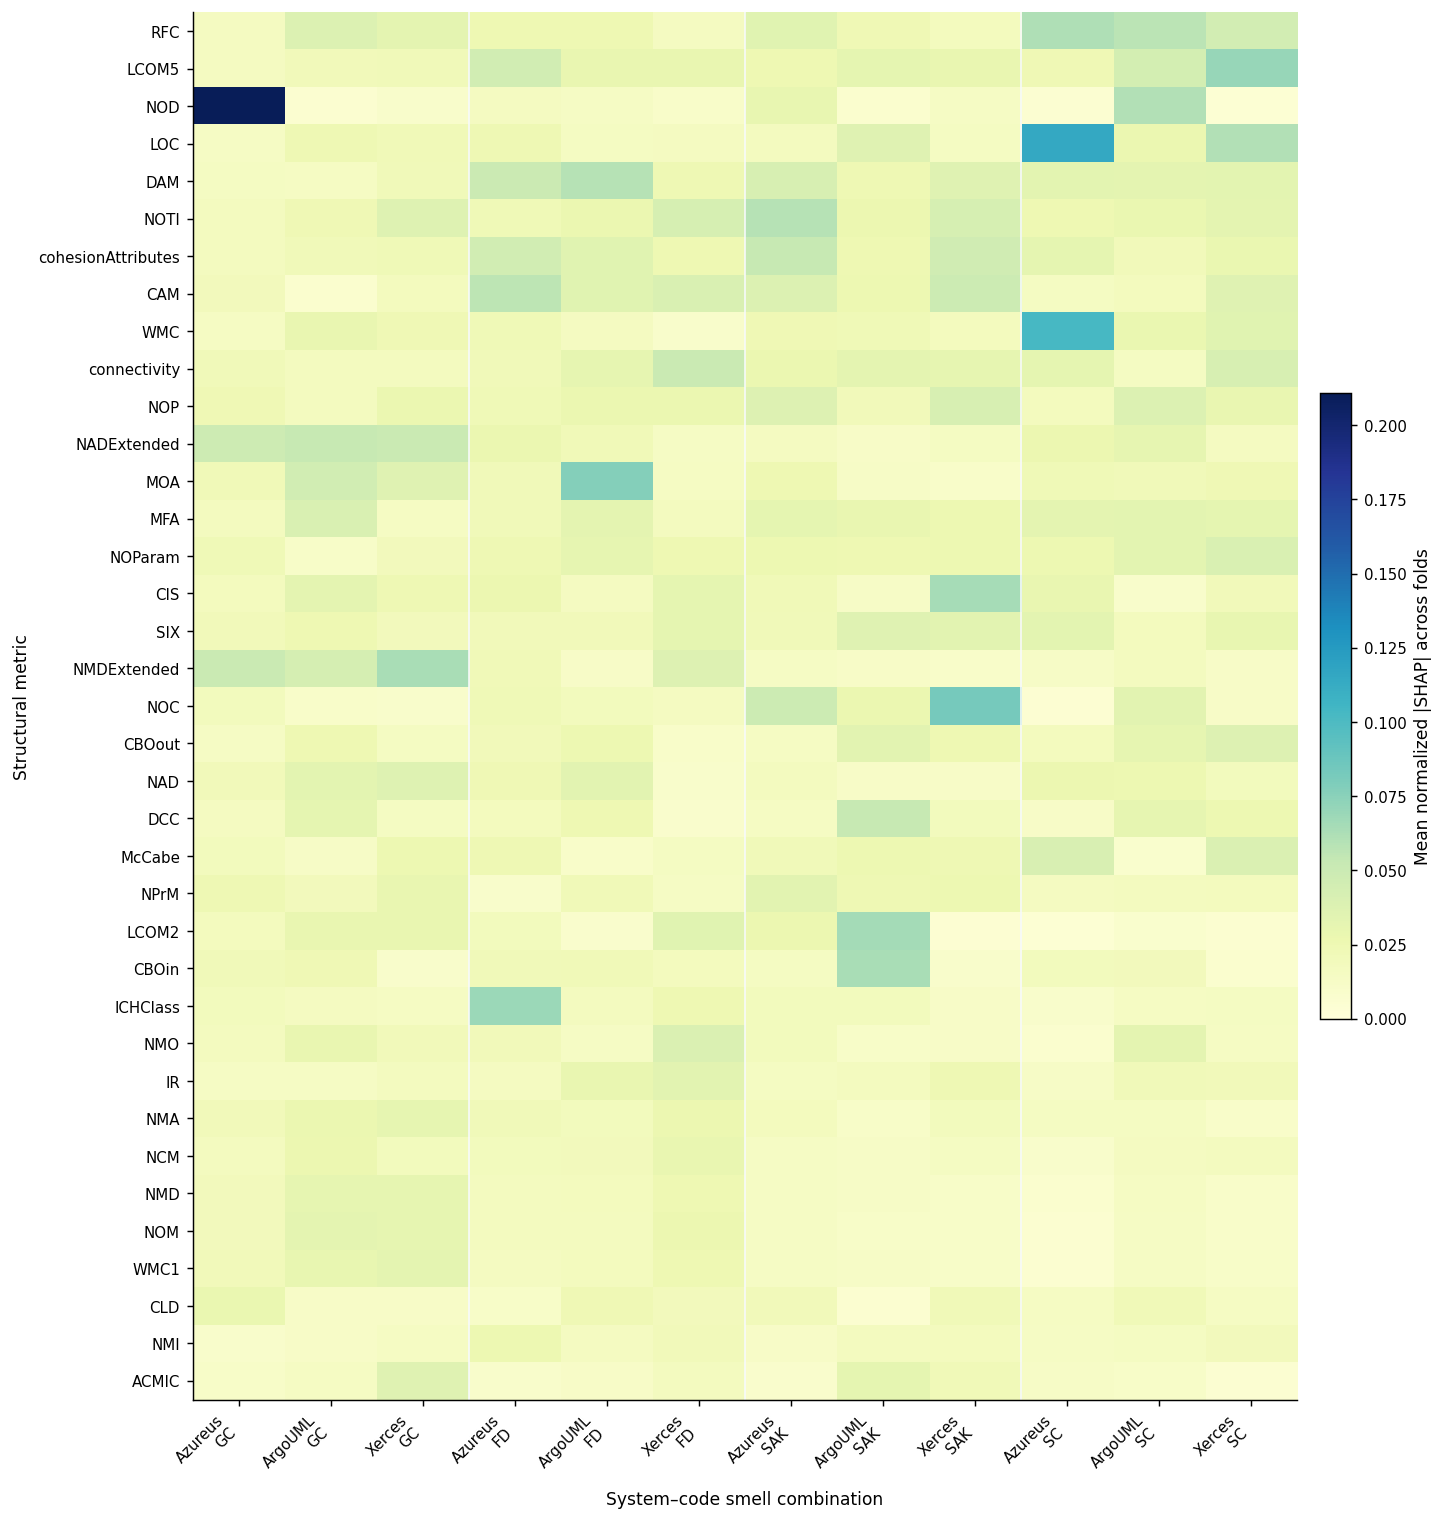

In [33]:
shap_global = load_validated(
    "shap_global.csv",
    [
        "project", "smell", "feature",
        "mean_normalized_importance",
        "rank_global_shap",
        "top_k_global",
        "top_k_frequency",
        "n_folds"
    ],
    label="Figure 2 — shap_global.csv"
)

validate_domain(
    shap_global,
    "shap_global.csv"
)

selected_features = (
    shap_global.loc[
        pd.to_numeric(
            shap_global["rank_global_shap"],
            errors="coerce"
        ) <= 10,
        "feature"
    ]
    .drop_duplicates()
    .tolist()
)

if not selected_features:
    raise ValueError(
        "Figure 2: no global Top-10 metrics were found."
    )

col_order = [
    (p, s)
    for s in SMELLS
    for p in PROJECTS
]

col_labels = [
    f"{p}\n{SMELL_LABEL[s]}"
    for p, s in col_order
]

pivot = (
    shap_global[
        shap_global["feature"].isin(
            selected_features
        )
    ]
    .pivot(
        index="feature",
        columns=["project", "smell"],
        values="mean_normalized_importance"
    )
    .reindex(
        columns=pd.MultiIndex.from_tuples(
            col_order
        )
    )
)

row_order = (
    pivot.mean(axis=1)
    .sort_values(ascending=False)
    .index
)

pivot = pivot.reindex(row_order)
matrix = pivot.to_numpy(dtype=float)

fig_h = max(
    6.3,
    0.27 * len(pivot) + 1.8
)

fig, ax = plt.subplots(
    figsize=(11.2, fig_h)
)

im = ax.imshow(
    matrix,
    aspect="auto",
    cmap="YlGnBu",
    vmin=0
)

ax.set_xticks(
    np.arange(len(col_labels))
)

ax.set_xticklabels(
    col_labels,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    np.arange(len(pivot.index))
)

ax.set_yticklabels(
    pivot.index
)

ax.set_xlabel(
    "System–code smell combination"
)

ax.set_ylabel(
    "Structural metric"
)

for x in [2.5, 5.5, 8.5]:
    ax.axvline(
        x,
        linewidth=0.9,
        color="#F7FAFC"
    )

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.027,
    pad=0.02
)

cbar.set_label(
    "Mean normalized |SHAP| across folds"
)

fig.tight_layout()

save_png(
    fig,
    "MAIN_Figure2_global_SHAP_importance",
    main=True
)

plt.show()


### Figure 3 — Structural metric categories

Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/figures/MAIN_Figure3_structural_metric_categories.png


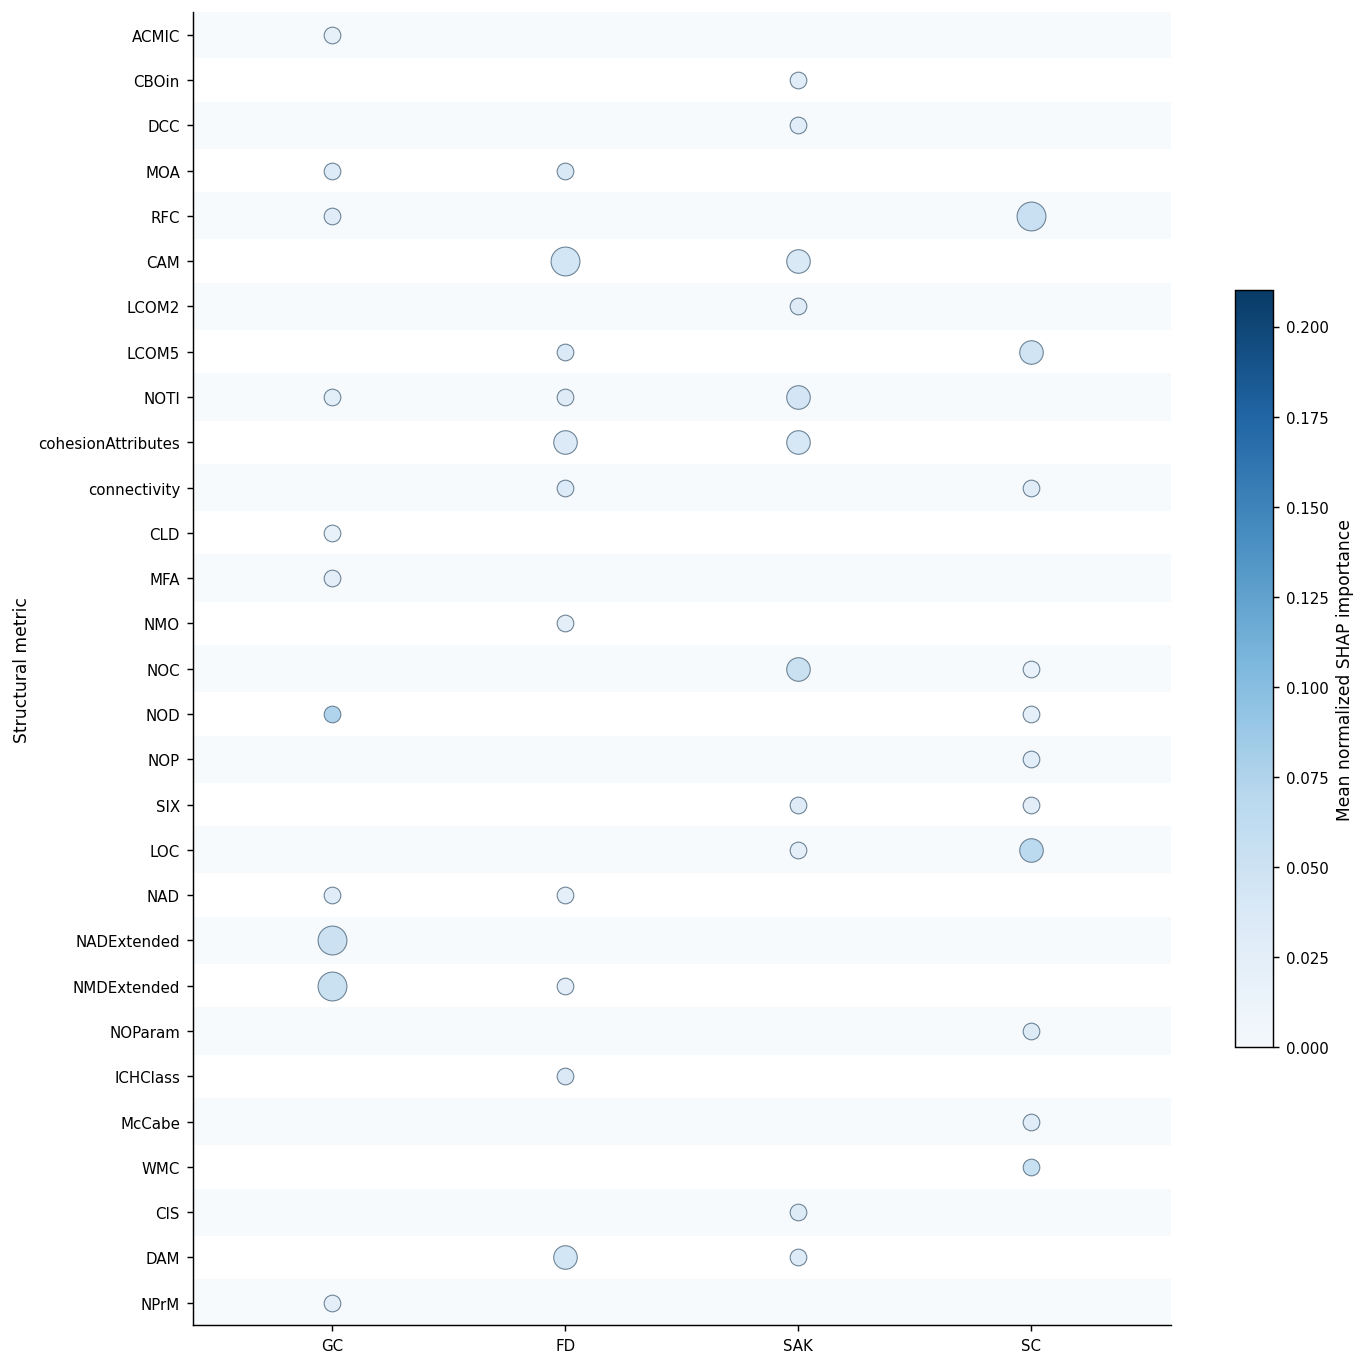

In [34]:
CATEGORY_METRICS = {
    "Coupling and\nDependencies": ["ACMIC", "CBOin", "DCC", "MOA", "RFC"],
    "Cohesion and\nInternal Interaction": ["CAM", "LCOM2", "LCOM5", "NOTI", "cohesionAttributes", "connectivity"],
    "Inheritance,\nPolymorphism, and\nSpecialization": ["CLD", "MFA", "NMO", "NOC", "NOD", "NOP", "SIX"],
    "Size and\nStructure": ["LOC", "NAD", "NADExtended", "NMDExtended", "NOParam"],
    "Complexity": ["ICHClass", "McCabe", "WMC"],
    "Encapsulation and\nInterface": ["CIS", "DAM", "NPrM"]
}
category_order = [(category, metric) for category, features in CATEGORY_METRICS.items() for metric in features]
category_data = shap_global.copy()
category_data["top_k_global"] = category_data["top_k_global"].astype(bool)
category_data = category_data.groupby(["smell", "feature"], as_index=False).agg(
    mean_normalized_importance=("mean_normalized_importance", "mean"),
    n_systems_top5=("top_k_global", "sum")
)
category_data = category_data[category_data["n_systems_top5"] > 0]
known_features = {metric for _, metric in category_order}
missing_features = sorted(set(category_data["feature"]) - known_features)
if missing_features:
    raise ValueError(f"Unclassified metrics in Figure 3: {missing_features}")
rows = []
for category, metric in category_order:
    for smell in SMELLS:
        match = category_data[(category_data["feature"] == metric) & (category_data["smell"] == smell)]
        if not match.empty:
            r = match.iloc[0]
            rows.append((category, metric, smell, float(r["mean_normalized_importance"]), int(r["n_systems_top5"])))
fig, ax = plt.subplots(figsize=(10.6, 10.6))
for idx, (category, metric) in enumerate(category_order):
    if idx % 2 == 0:
        ax.axhspan(idx-0.5, idx+0.5, color="#F7FAFC", zorder=0)
for category, metric, smell, importance, count in rows:
    y = category_order.index((category, metric))
    x = SMELLS.index(smell)
    ax.scatter(x, y, s=85*count, c=[importance], cmap=BLUE_SEQ, vmin=0, vmax=max(0.21, category_data["mean_normalized_importance"].max()), edgecolor="#6B8294", linewidth=0.6, zorder=3)
ax.set_xlim(-0.6, 3.6)
ax.set_ylim(len(category_order)-0.5, -0.5)
ax.set_xticks(range(4), [SMELL_LABEL[s] for s in SMELLS])
ax.set_yticks(range(len(category_order)), [m for _, m in category_order])
ax.set_xlabel("")
ax.set_ylabel("Structural metric")
from matplotlib.cm import ScalarMappable
norm = plt.Normalize(vmin=0, vmax=max(0.21, category_data["mean_normalized_importance"].max()))
cb=fig.colorbar(ScalarMappable(norm=norm,cmap=BLUE_SEQ),ax=ax,fraction=0.035,pad=0.06)
cb.set_label("Mean normalized SHAP importance")
fig.tight_layout()
save_png(fig, "MAIN_Figure3_structural_metric_categories")
plt.show()


### Figure 4 — Fold-level persistence

Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/figures/MAIN_Figure4_fold_level_persistence.png


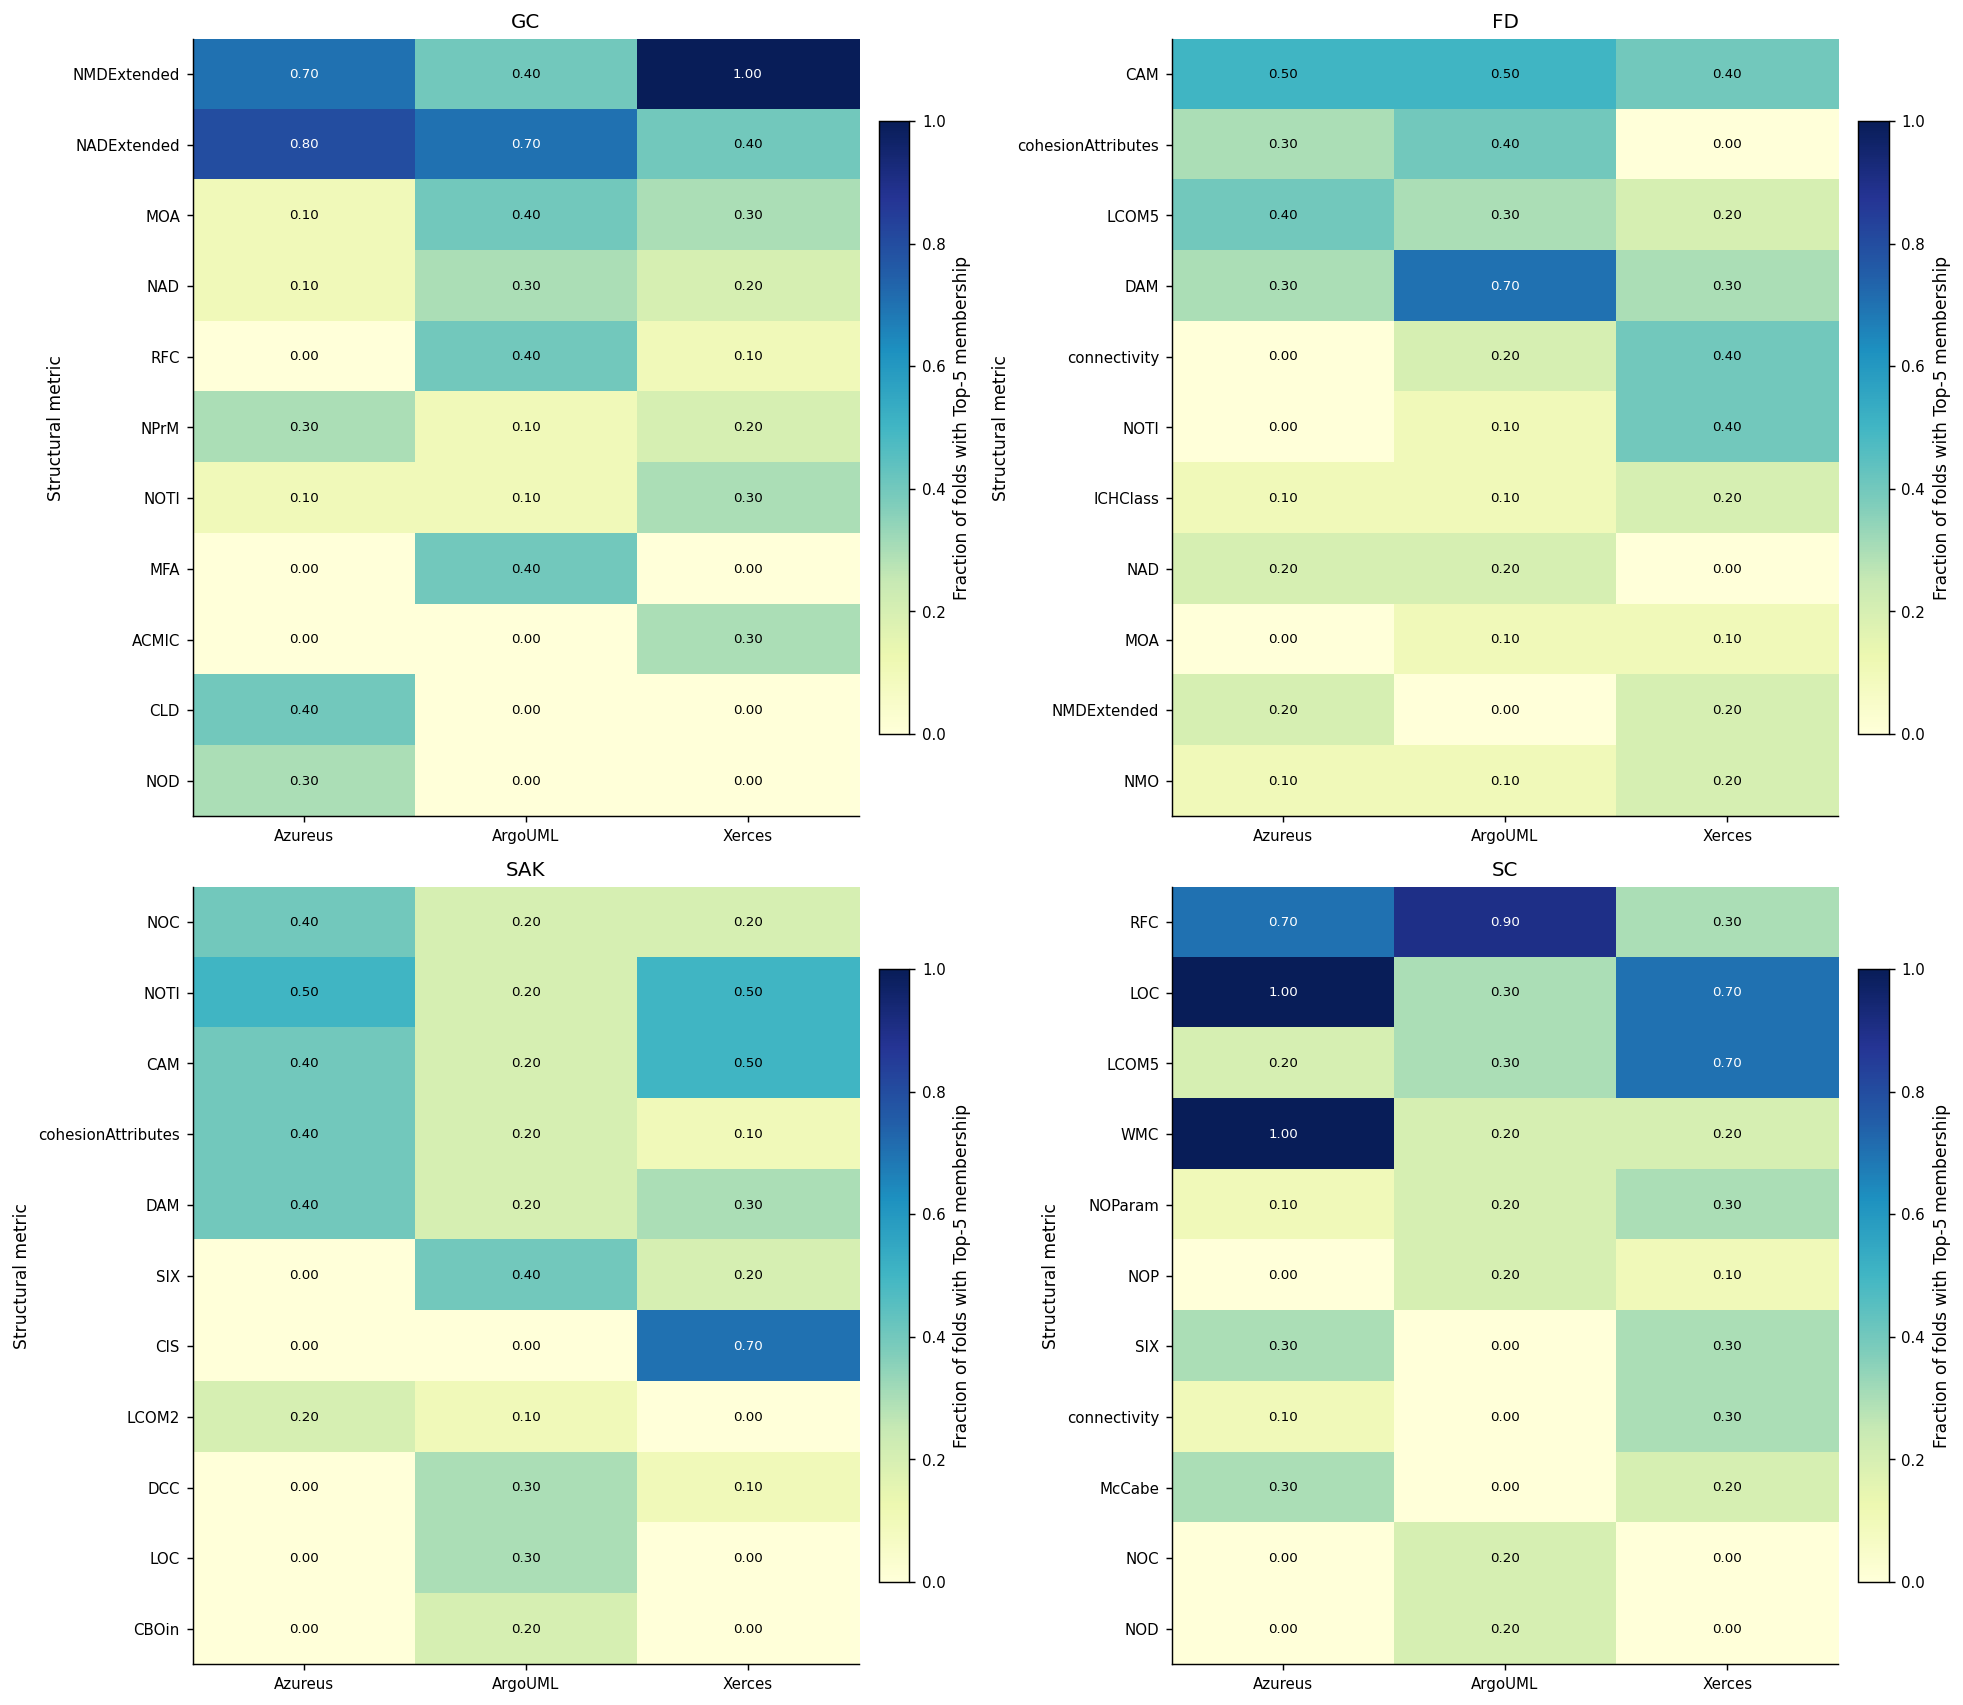

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(15.0, 13.0), constrained_layout=True)

for smell, ax in zip(SMELLS, axes.flat):

    g = shap_global[
        shap_global["smell"] == smell
    ].copy()

    selected = (
        g.groupby("feature")["top_k_global"]
        .any()
    )

    features = selected[
        selected
    ].index.tolist()

    if not features:
        raise ValueError(
            f"Figure S1: no globally Top-5 metrics are available for {SMELL_LABEL[smell]}."
        )

    row_order = (
        g[
            g["feature"].isin(
                features
            )
        ]
        .groupby("feature")[
            "rank_global_shap"
        ]
        .mean()
        .sort_values()
        .index
        .tolist()
    )

    p = (
        g[
            g["feature"].isin(
                row_order
            )
        ]
        .pivot(
            index="feature",
            columns="project",
            values="top_k_frequency"
        )
        .reindex(
            index=row_order,
            columns=PROJECTS
        )
    )

    matrix = p.to_numpy(
        dtype=float
    )

    fig_h = max(
        4.8,
        0.34 * len(row_order) + 1.8
    )


    im = ax.imshow(
        matrix,
        aspect="auto",
        cmap="YlGnBu",
        vmin=0,
        vmax=1
    )

    ax.set_xticks(
        np.arange(len(PROJECTS))
    )

    ax.set_xticklabels(
        PROJECTS
    )

    ax.set_yticks(
        np.arange(len(row_order))
    )

    ax.set_yticklabels(
        row_order
    )

    ax.set_xlabel(
        ""
    )

    ax.set_ylabel("Structural metric")
    ax.set_title(SMELL_LABEL[smell], fontsize=11)

    annotate_heatmap(
        ax,
        matrix,
        fmt=".2f",
        threshold=0.55,
        fontsize=7.4
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.03
    )

    cbar.set_label(
        "Fraction of folds with Top-5 membership"
    )


save_png(
    fig,
    "MAIN_Figure4_fold_level_persistence",
    main=True
)
plt.show()


### Figure 5 — SHAP–correlation concordance


[Figure 5 — concordance by fold]
shape: (120, 11)
columns: ['project', 'smell', 'fold', 'k', 'overlap_at_k', 'jaccard_top_k', 'spearman_rank_rho', 'spearman_rank_p', 'top_shap', 'top_correlation', 'intersection']

[Figure 5 — concordance summary]
shape: (12, 10)
columns: ['project', 'smell', 'overlap_median', 'overlap_q1', 'overlap_q3', 'jaccard_median', 'spearman_median', 'spearman_q1', 'spearman_q3', 'folds']
Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/figures/MAIN_Figure5_SHAP_correlation_concordance.png


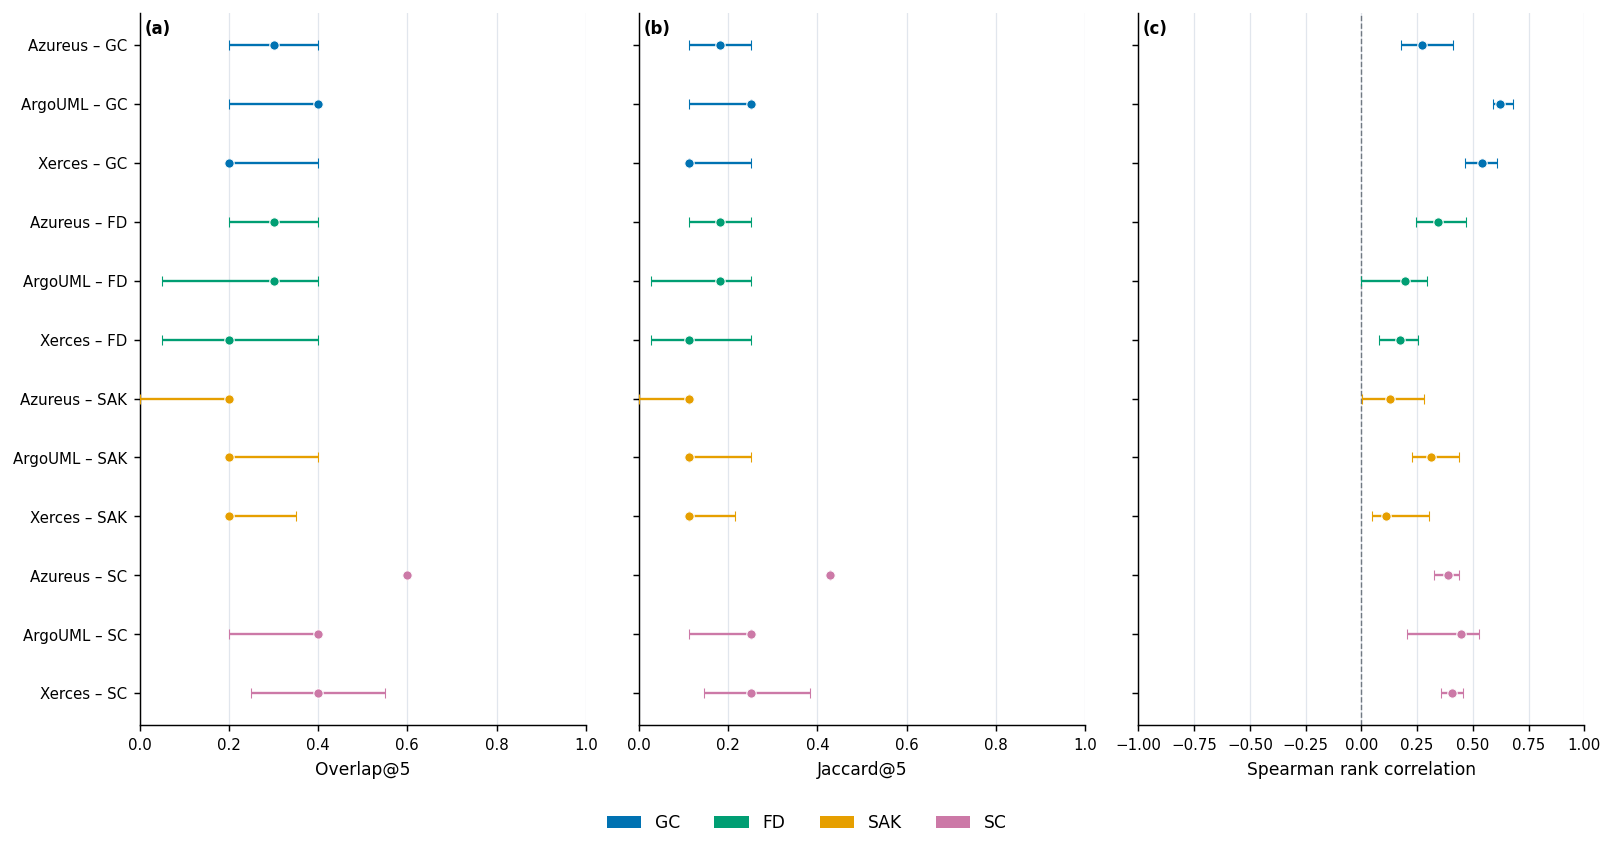

In [36]:
conc_fold = load_validated(
    "shap_correlation_concordance_by_fold.csv",
    [
        "project", "smell", "fold",
        "overlap_at_k",
        "jaccard_top_k",
        "spearman_rank_rho"
    ],
    label="Figure 5 — concordance by fold"
)

conc_summary = load_validated(
    "shap_correlation_concordance_summary.csv",
    [
        "project", "smell",
        "overlap_median",
        "overlap_q1",
        "overlap_q3",
        "jaccard_median",
        "spearman_median",
        "spearman_q1",
        "spearman_q3",
        "folds"
    ],
    label="Figure 5 — concordance summary"
)

for name, df in [
    ("shap_correlation_concordance_by_fold.csv", conc_fold),
    ("shap_correlation_concordance_summary.csv", conc_summary),
]:
    validate_domain(
        df,
        name
    )

jaccard_iqr = (
    conc_fold
    .groupby(
        ["project", "smell"],
        as_index=False
    )
    .agg(
        jaccard_q1=(
            "jaccard_top_k",
            q1
        ),
        jaccard_q3=(
            "jaccard_top_k",
            q3
        ),
    )
)

plot_df = conc_summary.merge(
    jaccard_iqr,
    on=["project", "smell"],
    how="left",
    validate="one_to_one"
)

order = pd.DataFrame(
    [
        (p, s)
        for s in SMELLS
        for p in PROJECTS
    ],
    columns=[
        "project",
        "smell"
    ]
)

plot_df = order.merge(
    plot_df,
    on=["project", "smell"],
    how="left",
    validate="one_to_one"
)

labels = [
    f"{r.project} – {SMELL_LABEL[r.smell]}"
    for r in plot_df.itertuples(
        index=False
    )
]

y = np.arange(
    len(plot_df)
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(12.5, 6.5),
    sharey=True
)

def interval_plot(
    ax,
    median,
    low,
    high,
    xlim,
    panel_text,
    xlabel
):

    med = pd.to_numeric(
        median,
        errors="coerce"
    ).to_numpy(dtype=float)

    lo = pd.to_numeric(
        low,
        errors="coerce"
    ).to_numpy(dtype=float)

    hi = pd.to_numeric(
        high,
        errors="coerce"
    ).to_numpy(dtype=float)

    for i in range(len(plot_df)):

        smell = plot_df.iloc[i]["smell"]
        color = SMELL_COLORS[smell]

        ax.errorbar(
            med[i],
            y[i],
            xerr=np.array([
                [med[i] - lo[i]],
                [hi[i] - med[i]]
            ]),
            fmt="o",
            color=color,
            ecolor=color,
            markersize=5.2,
            capsize=3,
            linewidth=1.3,
            elinewidth=1.3,
            markeredgecolor="white",
            markeredgewidth=0.6,
            zorder=3
        )

    ax.set_xlim(
        *xlim
    )

    ax.set_xlabel(
        xlabel
    )

    ax.grid(
        axis="x",
        color=GRID_COLOR,
        alpha=0.75,
        linewidth=0.7
    )

    panel_label(
        ax,
        panel_text
    )

interval_plot(
    axes[0],
    plot_df["overlap_median"],
    plot_df["overlap_q1"],
    plot_df["overlap_q3"],
    (0, 1),
    "(a)",
    "Overlap@5"
)

interval_plot(
    axes[1],
    plot_df["jaccard_median"],
    plot_df["jaccard_q1"],
    plot_df["jaccard_q3"],
    (0, 1),
    "(b)",
    "Jaccard@5"
)

interval_plot(
    axes[2],
    plot_df["spearman_median"],
    plot_df["spearman_q1"],
    plot_df["spearman_q3"],
    (-1, 1),
    "(c)",
    "Spearman rank correlation"
)

axes[2].axvline(
    0,
    linewidth=0.8,
    linestyle="--",
    color=TEXT_COLOR,
    alpha=0.6
)

axes[0].set_yticks(
    y
)

axes[0].set_yticklabels(
    labels
)

axes[0].invert_yaxis()

legend_handles = [
    Patch(
        facecolor=SMELL_COLORS[s],
        edgecolor="none",
        label=SMELL_LABEL[s]
    )
    for s in SMELLS
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, -0.01)
)

fig.tight_layout(
    rect=[0, 0.05, 1, 1]
)

save_png(
    fig,
    "MAIN_Figure5_SHAP_correlation_concordance",
    main=True
)

plt.show()


### Figures 6 and 7 — Literature-based alignment


[Figure 5 — operationalizations]
shape: (21, 5)
columns: ['dataset_smell', 'smell_label', 'op_id', 'expression', 'source']

[Figure 6 — literature indicator coverage]
shape: (63, 17)
columns: ['project', 'smell', 'smell_label', 'op_id', 'source', 'expression', 'n_indicators_reported', 'n_indicators_direct', 'n_indicators_approximate', 'n_indicators_unavailable', 'n_indicators_not_applicable', 'n_indicators_evaluable', 'n_indicators_top5', 'top5_coverage_evaluable', 'top5_coverage_all_reported', 'matched_top5_features', 'interpretation']

[Figure 7 — directional compatibility]
shape: (144, 19)
columns: ['project', 'smell', 'smell_label', 'source', 'op_id', 'literature_indicator_id', 'indicator', 'condition', 'mapping_status', 'mapping_cardinality', 'expected_direction', 'n_ptidej_mappings', 'ptidej_features', 'n_mappings_evaluable', 'mean_mapping_compatibility_rate', 'min_mapping_compatibility_rate', 'max_mapping_compatibility_rate', 'n_mappings_with_significant_support', 'n_mappings_w

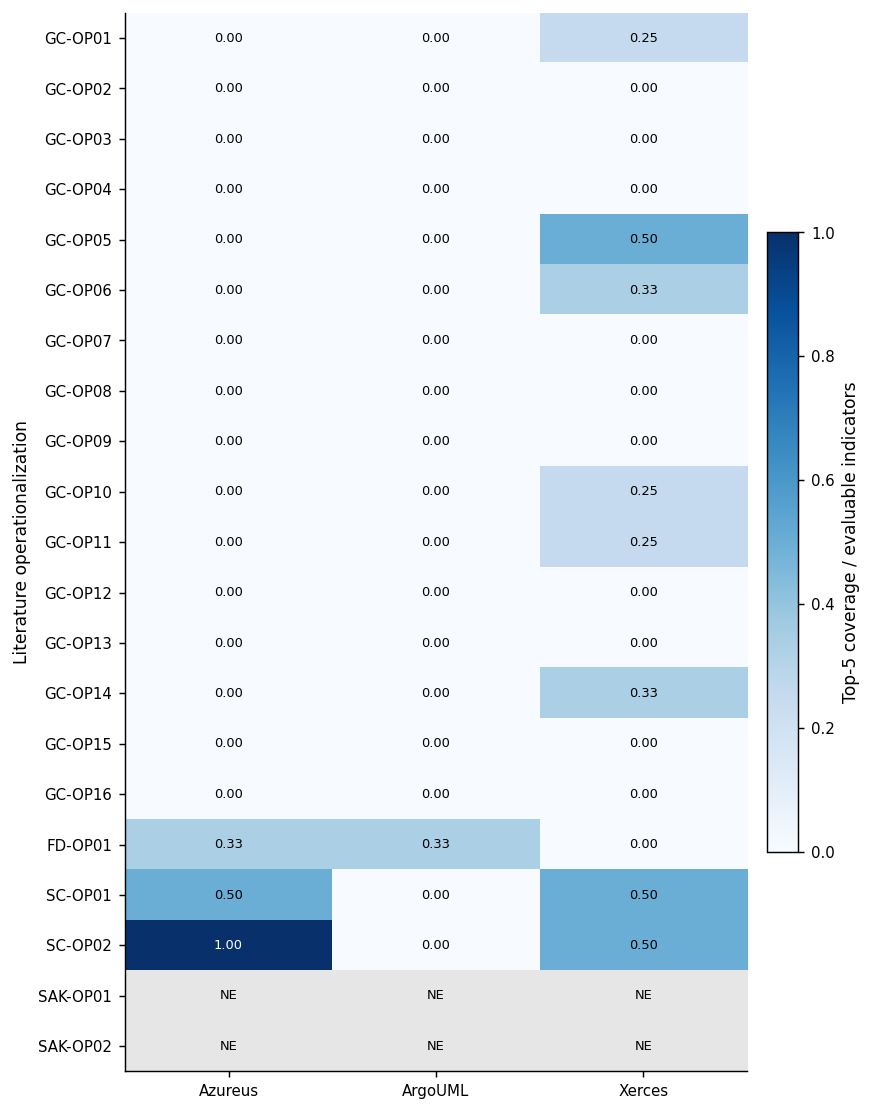

Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/figures/MAIN_Figure7_literature_directional_compatibility.png


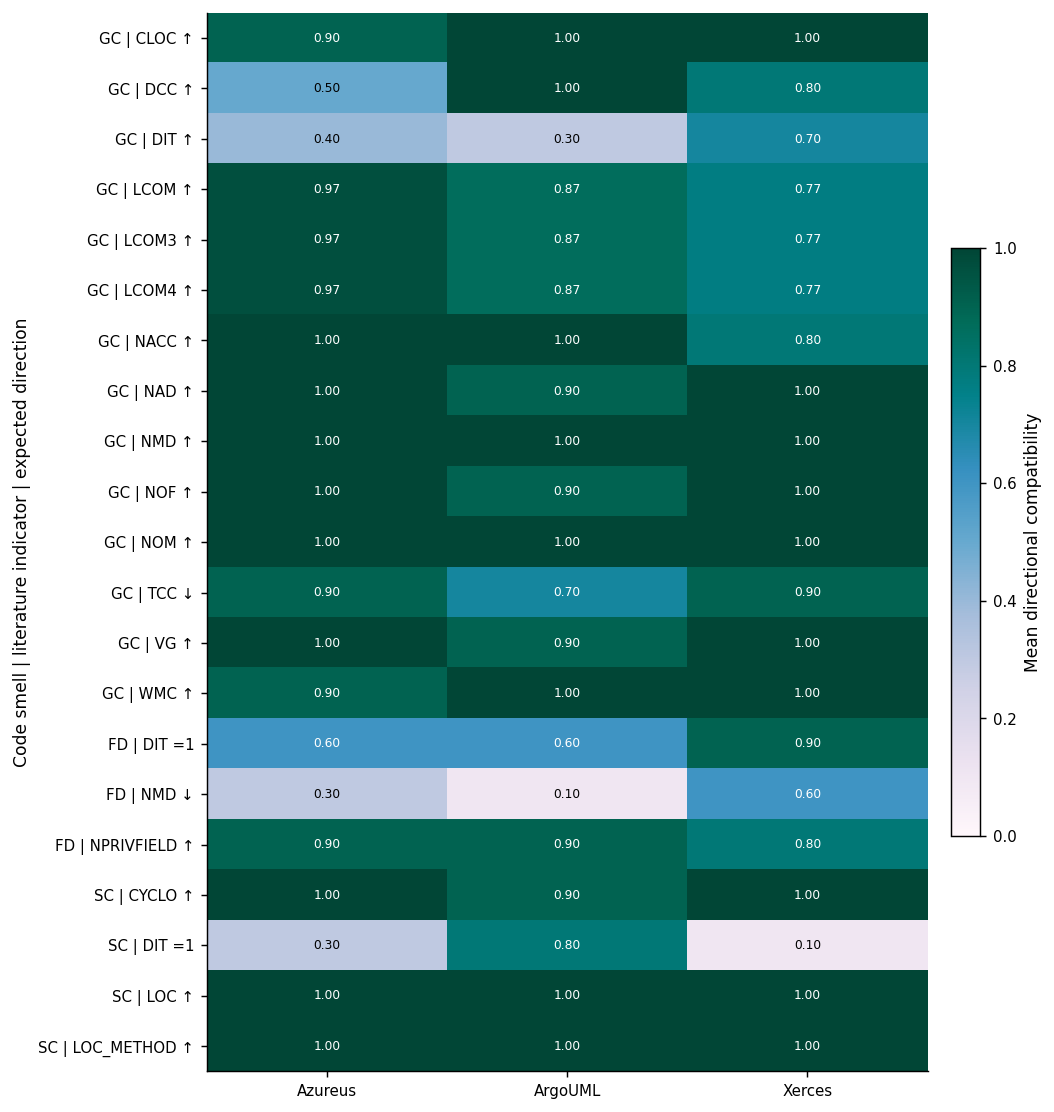

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECTS_F5 = [
    "Azureus",
    "ArgoUML",
    "Xerces"
]

SMELLS_F5 = [
    "BLOB",
    "FD",
    "SAK",
    "SC"
]

SMELL_LABEL_F5 = {
    "BLOB": "GC",
    "GC": "GC",
    "FD": "FD",
    "SAK": "SAK",
    "SC": "SC"
}

ops = load_validated(
    "literature_operationalizations.csv",
    [
        "dataset_smell",
        "smell_label",
        "op_id"
    ],
    label="Figure 5 — operationalizations"
)

cov5 = load_validated(
    "literature_rule_indicator_coverage.csv",
    [
        "project",
        "smell",
        "op_id",
        "top5_coverage_evaluable"
    ],
    label="Figure 6 — literature indicator coverage"
)

dir5 = load_validated(
    "literature_direction_indicator_summary.csv",
    [
        "project",
        "smell",
        "op_id",
        "literature_indicator_id",
        "indicator",
        "expected_direction",
        "n_mappings_evaluable",
        "mean_mapping_compatibility_rate"
    ],
    label="Figure 7 — directional compatibility"
)


validate_domain(
    cov5,
    "literature_rule_indicator_coverage.csv"
)

validate_domain(
    dir5,
    "literature_direction_indicator_summary.csv"
)

op_order = (
    ops[
        ops["dataset_smell"].isin(SMELLS_F5)
    ]["op_id"]
    .drop_duplicates()
    .tolist()
)

cov_pivot = (
    cov5
    .pivot(
        index="op_id",
        columns="project",
        values="top5_coverage_evaluable"
    )
    .reindex(
        index=op_order,
        columns=PROJECTS_F5
    )
)

cov_matrix = cov_pivot.to_numpy(
    dtype=float
)

cov_masked = np.ma.masked_invalid(
    cov_matrix
)

fig_h = max(
    5.0,
    0.34 * len(cov_pivot.index) + 1.5
)

fig, ax = plt.subplots(
    figsize=(6.8, fig_h)
)

cmap_a = plt.get_cmap("Blues").copy()
cmap_a.set_bad("#E6E6E6")

im = ax.imshow(
    cov_masked,
    aspect="auto",
    cmap=cmap_a,
    vmin=0,
    vmax=1
)

ax.set_xticks(
    np.arange(len(PROJECTS_F5))
)

ax.set_xticklabels(
    PROJECTS_F5
)

ax.set_yticks(
    np.arange(len(cov_pivot.index))
)

ax.set_yticklabels(
    cov_pivot.index
)

ax.set_xlabel("")

ax.set_ylabel(
    "Literature operationalization"
)

annotate_heatmap(
    ax,
    cov_matrix,
    fmt=".2f",
    threshold=0.55,
    fontsize=7.2,
    nan_text="NE"
)

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.03
)

cbar.set_label(
    "Top-5 coverage / evaluable indicators"
)

fig.tight_layout()

save_png(
    fig,
    "MAIN_Figure6_literature_indicator_coverage"
)

plt.show()

dir_plot = dir5.copy()

dir_plot["Smell"] = (
    dir_plot["smell"]
    .map(SMELL_LABEL_F5)
    .fillna(
        dir_plot["smell"].astype(str)
    )
)

direction_symbol = {
    "higher": "↑",
    "lower": "↓",
    "equals_1": "=1"
}

dir_plot["Direction"] = (
    dir_plot["expected_direction"]
    .map(direction_symbol)
)

dir_plot = (
    dir_plot[
        dir_plot["Direction"].notna()
    ]
    .copy()
)

dir_plot["row_label"] = (
    dir_plot["Smell"].astype(str)
    + " | "
    + dir_plot["indicator"].astype(str)
    + " "
    + dir_plot["Direction"].astype(str)
)

dir_pivot = (
    dir_plot
    .pivot_table(
        index="row_label",
        columns="project",
        values="mean_mapping_compatibility_rate",
        aggfunc="mean"
    )
    .reindex(
        columns=PROJECTS_F5
    )
)

dir_pivot = (
    dir_pivot
    .dropna(
        axis=0,
        how="all"
    )
)

smell_order = {
    "GC": 0,
    "FD": 1,
    "SAK": 2,
    "SC": 3
}

dir_meta = (
    dir_plot[
        [
            "Smell",
            "indicator",
            "expected_direction",
            "row_label"
        ]
    ]
    .drop_duplicates()
    .assign(
        _smell_order=lambda d:
        d["Smell"].map(smell_order)
    )
)

dir_order = (
    dir_meta[
        dir_meta["row_label"].isin(
            dir_pivot.index
        )
    ]
    .sort_values(
        [
            "_smell_order",
            "indicator",
            "expected_direction"
        ]
    )["row_label"]
    .tolist()
)

dir_pivot = (
    dir_pivot
    .reindex(
        index=dir_order,
        columns=PROJECTS_F5
    )
)

dir_matrix = dir_pivot.to_numpy(
    dtype=float
)

dir_masked = np.ma.masked_invalid(
    dir_matrix
)

fig_h = max(
    5.0,
    0.34 * len(dir_pivot.index) + 1.5
)

fig, ax = plt.subplots(
    figsize=(8.2, fig_h)
)

cmap_b = plt.get_cmap("PuBuGn").copy()
cmap_b.set_bad("#E6E6E6")

im = ax.imshow(
    dir_masked,
    aspect="auto",
    cmap=cmap_b,
    vmin=0,
    vmax=1
)

ax.set_xticks(
    np.arange(len(PROJECTS_F5))
)

ax.set_xticklabels(
    PROJECTS_F5
)

ax.set_yticks(
    np.arange(len(dir_pivot.index))
)

ax.set_yticklabels(
    dir_pivot.index
)

ax.set_xlabel("")

ax.set_ylabel(
    "Code smell | literature indicator | expected direction"
)

annotate_heatmap(
    ax,
    dir_matrix,
    fmt=".2f",
    threshold=0.55,
    fontsize=6.8,
    nan_text="NE"
)

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.038,
    pad=0.03
)

cbar.set_label(
    "Mean directional compatibility"
)

fig.tight_layout()

save_png(
    fig,
    "MAIN_Figure7_literature_directional_compatibility"
)

plt.show()


In [38]:
table_s1 = shap_global[shap_global["top_k_global"].astype(bool)].copy()
table_s1["Code smell"] = display_smell(table_s1["smell"])

table_s1 = table_s1.rename(columns={
    "project": "Project",
    "feature": "Metric",
    "rank_global_shap": "Global SHAP rank",
    "mean_normalized_importance": "Mean normalized SHAP importance",
    "top_k_frequency": "Top-5 frequency across folds",
})

table_s1 = table_s1[
    [
        "Project", "Code smell", "Metric",
        "Global SHAP rank", "Mean normalized SHAP importance",
        "Top-5 frequency across folds"
    ]
].sort_values(
    ["Code smell", "Project", "Global SHAP rank"]
).reset_index(drop=True)

display(table_s1)
save_table(
    table_s1,
    "SUPP_TableS1_global_Top5_SHAP_metrics",
    main=False,
    latex=True,
    longtable=True
)


,Project,Code smell,Metric,Global SHAP rank,Mean normalized SHAP importance,Top-5 frequency across folds
0,ArgoUML,FD,MOA,1,0.076996,0.1
1,ArgoUML,FD,DAM,2,0.058757,0.7
2,ArgoUML,FD,CAM,3,0.034797,0.5
3,ArgoUML,FD,cohesionAttributes,4,0.034587,0.4
4,ArgoUML,FD,NAD,5,0.033842,0.2
5,Azureus,FD,ICHClass,1,0.068497,0.1
6,Azureus,FD,CAM,2,0.056606,0.5
7,Azureus,FD,DAM,3,0.049879,0.3
8,Azureus,FD,cohesionAttributes,4,0.046060,0.3
9,Azureus,FD,LCOM5,5,0.045858,0.4


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/SUPP_TableS1_global_Top5_SHAP_metrics.csv


In [39]:
cross_s = load_validated(
    "cross_project_consistency.csv",
    [
        "smell", "feature",
        "n_projects_top5", "projects_top5",
        "mean_rank", "median_rank",
        "mean_normalized_importance",
        "mean_top_k_frequency"
    ],
    label="Table S1 — cross_project_consistency.csv"
)

cross_s["Code smell"] = display_smell(
    cross_s["smell"]
)

table_s1 = (
    cross_s[
        pd.to_numeric(
            cross_s["n_projects_top5"],
            errors="coerce"
        ) >= 1
    ]
    .rename(columns={
        "feature": "Metric",
        "n_projects_top5": "Projects with global Top-5",
        "projects_top5": "Top-5 projects",
        "mean_rank": "Mean global rank",
        "median_rank": "Median global rank",
        "mean_normalized_importance": "Mean normalized SHAP importance",
        "mean_top_k_frequency": "Mean Top-5 fold frequency",
    })
    [
        [
            "Code smell", "Metric",
            "Projects with global Top-5",
            "Top-5 projects",
            "Mean global rank",
            "Median global rank",
            "Mean normalized SHAP importance",
            "Mean Top-5 fold frequency",
        ]
    ]
    .sort_values(
        [
            "Code smell",
            "Projects with global Top-5",
            "Mean global rank"
        ],
        ascending=[True, False, True]
    )
    .reset_index(drop=True)
)

display(table_s1)

save_table(
    table_s1,
    "SUPP_TableS2_cross_project_SHAP_metrics",
    main=False,
    latex=True,
    longtable=True
)



[Table S1 — cross_project_consistency.csv]
shape: (200, 10)
columns: ['smell', 'feature', 'n_projects', 'n_projects_top5', 'mean_rank', 'median_rank', 'mean_normalized_importance', 'mean_top_k_frequency', 'projects_top5', 'smell_label']


,Code smell,Metric,Projects with global Top-5,Top-5 projects,Mean global rank,Median global rank,Mean normalized SHAP importance,Mean Top-5 fold frequency
0,FD,CAM,3,ArgoUML|Azureus|Xerces,2.666667,3.0,0.043645,0.466667
1,FD,cohesionAttributes,2,ArgoUML|Azureus,8.000000,4.0,0.035203,0.233333
2,FD,DAM,2,ArgoUML|Azureus,8.666667,3.0,0.044278,0.433333
3,FD,LCOM5,1,Azureus,8.666667,10.0,0.034737,0.300000
4,FD,connectivity,1,Xerces,10.000000,8.0,0.034023,0.200000
5,FD,NOTI,1,Xerces,10.333333,12.0,0.030792,0.166667
6,FD,ICHClass,1,Azureus,17.000000,20.0,0.036709,0.133333
7,FD,NAD,1,ArgoUML,19.666667,13.0,0.022420,0.133333
8,FD,MOA,1,ArgoUML,20.000000,23.0,0.037309,0.066667
9,FD,NMDExtended,1,Xerces,20.333333,18.0,0.024033,0.133333


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/SUPP_TableS2_cross_project_SHAP_metrics.csv


In [40]:
conc_s = conc_summary.merge(
    jaccard_iqr,
    on=["project", "smell"],
    how="left",
    validate="one_to_one"
)

conc_s["Code smell"] = display_smell(
    conc_s["smell"]
)

table_s2 = (
    conc_s
    .rename(columns={
        "project": "Project",
        "overlap_median": "Overlap@5 median",
        "overlap_q1": "Overlap@5 Q1",
        "overlap_q3": "Overlap@5 Q3",
        "jaccard_median": "Jaccard@5 median",
        "jaccard_q1": "Jaccard@5 Q1",
        "jaccard_q3": "Jaccard@5 Q3",
        "spearman_median": "Spearman median",
        "spearman_q1": "Spearman Q1",
        "spearman_q3": "Spearman Q3",
        "folds": "Folds",
    })
    [
        [
            "Project", "Code smell",
            "Overlap@5 median", "Overlap@5 Q1", "Overlap@5 Q3",
            "Jaccard@5 median", "Jaccard@5 Q1", "Jaccard@5 Q3",
            "Spearman median", "Spearman Q1", "Spearman Q3",
            "Folds",
        ]
    ]
    .sort_values(
        ["Code smell", "Project"]
    )
    .reset_index(drop=True)
)

display(table_s2)

save_table(
    table_s2,
    "SUPP_TableS3_SHAP_correlation_concordance",
    main=False,
    latex=True
)


,Project,Code smell,Overlap@5 median,Overlap@5 Q1,Overlap@5 Q3,Jaccard@5 median,Jaccard@5 Q1,Jaccard@5 Q3,Spearman median,Spearman Q1,Spearman Q3,Folds
0,ArgoUML,FD,0.3,0.05,0.40,0.180556,0.027778,0.250000,0.194956,-0.001685,0.295492,10
1,Azureus,FD,0.3,0.20,0.40,0.180556,0.111111,0.250000,0.344305,0.244673,0.470894,10
2,Xerces,FD,0.2,0.05,0.40,0.111111,0.027778,0.250000,0.174605,0.078928,0.251877,10
3,ArgoUML,GC,0.4,0.20,0.40,0.250000,0.111111,0.250000,0.620507,0.590368,0.678083,10
4,Azureus,GC,0.3,0.20,0.40,0.180556,0.111111,0.250000,0.274086,0.178420,0.413055,10
5,Xerces,GC,0.2,0.20,0.40,0.111111,0.111111,0.250000,0.540201,0.466338,0.607332,10
6,ArgoUML,SAK,0.2,0.20,0.40,0.111111,0.111111,0.250000,0.311756,0.228907,0.438698,10
7,Azureus,SAK,0.2,0.00,0.20,0.111111,0.000000,0.111111,0.130479,0.003201,0.281931,10
8,Xerces,SAK,0.2,0.20,0.35,0.111111,0.111111,0.215278,0.112193,0.048188,0.303423,10
9,ArgoUML,SC,0.4,0.20,0.40,0.250000,0.111111,0.250000,0.445938,0.205980,0.528466,10


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/SUPP_TableS3_SHAP_correlation_concordance.csv


In [41]:
coverage_full = load_validated(
    "literature_rule_indicator_coverage.csv",
    [
        "project", "smell", "smell_label",
        "op_id", "source", "expression",
        "n_indicators_reported",
        "n_indicators_direct",
        "n_indicators_approximate",
        "n_indicators_unavailable",
        "n_indicators_not_applicable",
        "n_indicators_evaluable",
        "n_indicators_top5",
        "top5_coverage_evaluable",
        "top5_coverage_all_reported",
        "matched_top5_features",
        "interpretation"
    ],
    label="Table S3 — literature_rule_indicator_coverage.csv"
)

table_s3 = (
    coverage_full
    .rename(columns={
        "project": "Project",
        "smell_label": "Code smell",
        "op_id": "Operationalization",
        "source": "Source",
        "expression": "Operationalization expression",
        "n_indicators_reported": "Reported indicators",
        "n_indicators_direct": "Direct mappings",
        "n_indicators_approximate": "Approximate mappings",
        "n_indicators_unavailable": "Unavailable mappings",
        "n_indicators_not_applicable": "Not-applicable mappings",
        "n_indicators_evaluable": "Evaluable indicators",
        "n_indicators_top5": "Indicators in SHAP Top-5",
        "top5_coverage_evaluable": "Top-5 coverage / evaluable",
        "top5_coverage_all_reported": "Top-5 coverage / all reported",
        "matched_top5_features": "Matched Top-5 metrics",
    })
    [
        [
            "Project", "Code smell", "Operationalization",
            "Source", "Operationalization expression",
            "Reported indicators", "Direct mappings",
            "Approximate mappings", "Unavailable mappings",
            "Not-applicable mappings", "Evaluable indicators",
            "Indicators in SHAP Top-5",
            "Top-5 coverage / evaluable",
            "Top-5 coverage / all reported",
            "Matched Top-5 metrics",
        ]
    ]
    .sort_values(
        ["Code smell", "Operationalization", "Project"]
    )
    .reset_index(drop=True)
)

display(table_s3.head(20))

save_table(
    table_s3,
    "SUPP_TableS4_literature_coverage_detail",
    main=False,
    latex=False
)



[Table S3 — literature_rule_indicator_coverage.csv]
shape: (63, 17)
columns: ['project', 'smell', 'smell_label', 'op_id', 'source', 'expression', 'n_indicators_reported', 'n_indicators_direct', 'n_indicators_approximate', 'n_indicators_unavailable', 'n_indicators_not_applicable', 'n_indicators_evaluable', 'n_indicators_top5', 'top5_coverage_evaluable', 'top5_coverage_all_reported', 'matched_top5_features', 'interpretation']


,Project,Code smell,Operationalization,Source,Operationalization expression,Reported indicators,Direct mappings,Approximate mappings,Unavailable mappings,Not-applicable mappings,Evaluable indicators,Indicators in SHAP Top-5,Top-5 coverage / evaluable,Top-5 coverage / all reported,Matched Top-5 metrics
0,ArgoUML,FD,FD-OP01,Moha2010DECOR:Smells,"NPRIVFIELD HIGH, NMD VERY_LOW, LexicClassName,...",5,2,1,2,0,3,1,0.333333,0.200000,DAM
1,Azureus,FD,FD-OP01,Moha2010DECOR:Smells,"NPRIVFIELD HIGH, NMD VERY_LOW, LexicClassName,...",5,2,1,2,0,3,1,0.333333,0.200000,DAM
2,Xerces,FD,FD-OP01,Moha2010DECOR:Smells,"NPRIVFIELD HIGH, NMD VERY_LOW, LexicClassName,...",5,2,1,2,0,3,0,0.000000,0.000000,NaN
3,ArgoUML,GC,GC-OP01,Moha2010DECOR:Smells,"LCOM VERY_HIGH, NMD+NAD VERY_HIGH, NACC VERY_H...",6,2,2,2,0,4,0,0.000000,0.000000,NaN
4,Azureus,GC,GC-OP01,Moha2010DECOR:Smells,"LCOM VERY_HIGH, NMD+NAD VERY_HIGH, NACC VERY_H...",6,2,2,2,0,4,0,0.000000,0.000000,NaN
5,Xerces,GC,GC-OP01,Moha2010DECOR:Smells,"LCOM VERY_HIGH, NMD+NAD VERY_HIGH, NACC VERY_H...",6,2,2,2,0,4,1,0.250000,0.166667,NAD
6,ArgoUML,GC,GC-OP02,Trifu2005DiagnosingSystems,ATFD>2 & WMC>=47 & TCC<0.33,3,1,1,1,0,2,0,0.000000,0.000000,NaN
7,Azureus,GC,GC-OP02,Trifu2005DiagnosingSystems,ATFD>2 & WMC>=47 & TCC<0.33,3,1,1,1,0,2,0,0.000000,0.000000,NaN
8,Xerces,GC,GC-OP02,Trifu2005DiagnosingSystems,ATFD>2 & WMC>=47 & TCC<0.33,3,1,1,1,0,2,0,0.000000,0.000000,NaN
9,ArgoUML,GC,GC-OP03,Schumacher2010BuildingDetection,ATFD>5 & WMC>=47 & TCC<0.33,3,1,1,1,0,2,0,0.000000,0.000000,NaN


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/SUPP_TableS4_literature_coverage_detail.csv


In [42]:
direction_full = load_validated(
    "direction_feature_summary.csv",
    [
        "project", "smell", "feature",
        "expected_direction",
        "n_folds_evaluable",
        "n_folds_compatible",
        "compatibility_rate",
        "median_effect_size",
        "n_folds_significant_support",
        "n_folds_significant_opposition"
    ],
    label="Table S4 — direction_feature_summary.csv"
)

direction_full["Code smell"] = display_smell(
    direction_full["smell"]
)

table_s4 = (
    direction_full
    .rename(columns={
        "project": "Project",
        "feature": "Metric",
        "expected_direction": "Expected direction",
        "n_folds_evaluable": "Evaluable folds",
        "n_folds_compatible": "Compatible folds",
        "compatibility_rate": "Compatibility rate",
        "median_effect_size": "Median effect size",
        "n_folds_significant_support": "Folds with significant support",
        "n_folds_significant_opposition": "Folds with significant opposition",
    })
    [
        [
            "Project", "Code smell", "Metric",
            "Expected direction",
            "Evaluable folds", "Compatible folds",
            "Compatibility rate", "Median effect size",
            "Folds with significant support",
            "Folds with significant opposition",
        ]
    ]
    .sort_values(
        ["Code smell", "Metric", "Project", "Expected direction"]
    )
    .reset_index(drop=True)
)

display(table_s4.head(20))

save_table(
    table_s4,
    "SUPP_TableS5_directional_compatibility_detail",
    main=False,
    latex=False
)



[Table S4 — direction_feature_summary.csv]
shape: (57, 10)
columns: ['project', 'smell', 'feature', 'expected_direction', 'n_folds_evaluable', 'n_folds_compatible', 'compatibility_rate', 'median_effect_size', 'n_folds_significant_support', 'n_folds_significant_opposition']


,Project,Code smell,Metric,Expected direction,Evaluable folds,Compatible folds,Compatibility rate,Median effect size,Folds with significant support,Folds with significant opposition
0,ArgoUML,FD,DAM,higher,10,9,0.9,0.799276,7,0
1,Azureus,FD,DAM,higher,10,9,0.9,0.812438,7,0
2,Xerces,FD,DAM,higher,10,8,0.8,0.145720,4,1
3,ArgoUML,FD,DIT,equals_1,10,6,0.6,0.072727,0,1
4,Azureus,FD,DIT,equals_1,10,6,0.6,0.482993,4,1
5,Xerces,FD,DIT,equals_1,10,9,0.9,0.603376,5,0
6,ArgoUML,FD,NMD,lower,10,1,0.1,0.637112,1,7
7,Azureus,FD,NMD,lower,10,3,0.3,0.354797,1,4
8,Xerces,FD,NMD,lower,10,6,0.6,-0.158310,2,2
9,ArgoUML,GC,CIS,higher,10,10,1.0,0.846674,10,0


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/SUPP_TableS5_directional_compatibility_detail.csv


In [43]:
sens_s = load_validated(
    "shap_sensitivity_pairwise.csv",
    [
        "project", "smell",
        "rank_spearman",
        "overlap5",
        "jaccard5"
    ],
    label="Table S5 — shap_sensitivity_pairwise.csv"
)

table_s5 = (
    sens_s
    .groupby("smell", as_index=False)
    .agg(
        Pairwise_comparisons=("rank_spearman", "count"),
        Spearman_median=("rank_spearman", "median"),
        Spearman_Q1=("rank_spearman", q1),
        Spearman_Q3=("rank_spearman", q3),
        Overlap5_median=("overlap5", "median"),
        Overlap5_Q1=("overlap5", q1),
        Overlap5_Q3=("overlap5", q3),
        Jaccard5_median=("jaccard5", "median"),
        Jaccard5_Q1=("jaccard5", q1),
        Jaccard5_Q3=("jaccard5", q3),
    )
)

table_s5.insert(
    1,
    "Code smell",
    display_smell(table_s5["smell"])
)

table_s5 = table_s5.drop(
    columns=["smell"]
)

display(table_s5)

save_table(
    table_s5,
    "SUPP_TableS6_SHAP_sensitivity",
    main=False,
    latex=True
)



[Table S5 — shap_sensitivity_pairwise.csv]
shape: (36, 10)
columns: ['project', 'smell', 'fold', 'seed_a', 'seed_b', 'rank_spearman', 'rank_spearman_p', 'overlap5_n', 'overlap5', 'jaccard5']


,Code smell,Pairwise_comparisons,Spearman_median,Spearman_Q1,Spearman_Q3,Overlap5_median,Overlap5_Q1,Overlap5_Q3,Jaccard5_median,Jaccard5_Q1,Jaccard5_Q3
0,GC,9,0.992029,0.989916,0.996543,1.0,1.0,1.0,1.000000,1.000000,1.0
1,FD,9,0.988091,0.982329,0.990204,1.0,1.0,1.0,1.000000,1.000000,1.0
2,SAK,9,0.978295,0.886387,0.991453,1.0,0.8,1.0,1.000000,0.666667,1.0
3,SC,9,0.984442,0.952845,0.990108,0.8,0.8,1.0,0.666667,0.666667,1.0


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/SUPP_TableS6_SHAP_sensitivity.csv


In [44]:
support_files = {
    "SUPP_TableS7_baseline_reproduction": "baseline_reproduction.csv",
    "SUPP_TableS8_protocol_integrity": "protocol_integrity_check.csv",
    "SUPP_TableS9_SHAP_runtime": "shap_runtime.csv",
    "SUPP_TableS10_SHAP_sensitivity_runtime": "shap_sensitivity_runtime.csv",
}

for table_name, filename in support_files.items():
    df = pd.read_csv(SOURCE_DIR / filename)
    display(df.head(10))

    save_table(
        df,
        table_name,
        main=False,
        latex=(len(df) <= 50 and len(df.columns) <= 12),
        longtable=(len(df) > 30)
    )


,project,smell,fold,n_train_match,n_test_match,confusion_matrix_match,f1_binary_match,accuracy_match,precision_match,recall_match,reproduction_ok,expected_f1_binary,actual_f1_binary,expected_roc_auc,actual_roc_auc,expected_cm,actual_cm
0,Azureus,BLOB,1,True,True,True,True,True,True,True,True,1.000000,1.000000,1.000000,1.000000,"(15, 0, 0, 15)","(15, 0, 0, 15)"
1,Azureus,BLOB,2,True,True,True,True,True,True,True,True,1.000000,1.000000,1.000000,1.000000,"(15, 0, 0, 15)","(15, 0, 0, 15)"
2,Azureus,BLOB,3,True,True,True,True,True,True,True,True,0.967742,0.967742,1.000000,1.000000,"(14, 1, 0, 15)","(14, 1, 0, 15)"
3,Azureus,BLOB,4,True,True,True,True,True,True,True,True,1.000000,1.000000,1.000000,1.000000,"(15, 0, 0, 15)","(15, 0, 0, 15)"
4,Azureus,BLOB,5,True,True,True,True,True,True,True,True,0.857143,0.857143,0.995556,0.995556,"(10, 5, 0, 15)","(10, 5, 0, 15)"
5,Azureus,BLOB,6,True,True,True,True,True,True,True,True,0.967742,0.967742,1.000000,1.000000,"(14, 1, 0, 15)","(14, 1, 0, 15)"
6,Azureus,BLOB,7,True,True,True,True,True,True,True,True,0.928571,0.928571,0.924444,0.924444,"(15, 0, 2, 13)","(15, 0, 2, 13)"
7,Azureus,BLOB,8,True,True,True,True,True,True,True,True,0.965517,0.965517,1.000000,1.000000,"(15, 0, 1, 14)","(15, 0, 1, 14)"
8,Azureus,BLOB,9,True,True,True,True,True,True,True,True,1.000000,1.000000,1.000000,1.000000,"(15, 0, 0, 15)","(15, 0, 0, 15)"
9,Azureus,BLOB,10,True,True,True,True,True,True,True,True,0.909091,0.909091,0.991111,0.991111,"(12, 3, 0, 15)","(12, 3, 0, 15)"


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/SUPP_TableS7_baseline_reproduction.csv


,project,smell,fold,n_train,n_test,positive_rate_train,positive_rate_test,n_features
0,Azureus,BLOB,1,82,30,0.5,0.5,50
1,Azureus,BLOB,2,82,30,0.5,0.5,50
2,Azureus,BLOB,3,82,30,0.5,0.5,50
3,Azureus,BLOB,4,82,30,0.5,0.5,50
4,Azureus,BLOB,5,82,30,0.5,0.5,50
5,Azureus,BLOB,6,82,30,0.5,0.5,50
6,Azureus,BLOB,7,82,30,0.5,0.5,50
7,Azureus,BLOB,8,82,30,0.5,0.5,50
8,Azureus,BLOB,9,82,30,0.5,0.5,50
9,Azureus,BLOB,10,82,30,0.5,0.5,50


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/SUPP_TableS8_protocol_integrity.csv


,project,smell,fold,n_background,n_explained,n_features,shap_permutation_cycles,shap_max_evals,shap_seconds,max_additivity_error,mean_additivity_error,additivity_ok,shap_output
0,Azureus,BLOB,1,50,30,50,3,303,8.694703,5.329071e-15,1.491400e-15,True,decision_function
1,Azureus,BLOB,2,50,30,50,3,303,0.765209,4.547474e-12,1.532552e-13,True,decision_function
2,Azureus,BLOB,3,50,30,50,3,303,1.512776,1.554312e-15,5.925815e-16,True,decision_function
3,Azureus,BLOB,4,50,30,50,3,303,0.633789,7.105427e-15,1.280457e-15,True,decision_function
4,Azureus,BLOB,5,50,30,50,3,303,2.270510,8.881784e-16,2.703856e-16,True,decision_function
5,Azureus,BLOB,6,50,30,50,3,303,2.212072,1.776357e-15,5.877243e-16,True,decision_function
6,Azureus,BLOB,7,50,30,50,3,303,0.564416,7.958079e-13,2.774066e-14,True,decision_function
7,Azureus,BLOB,8,50,30,50,3,303,0.435926,1.989520e-13,7.815970e-15,True,decision_function
8,Azureus,BLOB,9,50,30,50,3,303,0.480520,2.842171e-14,3.465746e-15,True,decision_function
9,Azureus,BLOB,10,50,30,50,3,303,2.381685,1.110223e-15,4.265107e-16,True,decision_function


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/SUPP_TableS9_SHAP_runtime.csv


,project,smell,fold,seed,n_background,n_explained,shap_seconds,max_additivity_error
0,Azureus,BLOB,1,43,50,30,9.809295,5.329071e-15
1,Azureus,BLOB,1,10043,50,30,0.689888,5.329071e-15
2,Azureus,BLOB,1,20043,50,30,0.701038,5.971224e-12
3,Azureus,FD,1,143,34,14,0.142601,3.552714e-14
4,Azureus,FD,1,10143,34,14,0.140729,2.842171e-14
5,Azureus,FD,1,20143,34,14,0.157914,3.552714e-14
6,Azureus,SAK,1,243,50,28,0.576107,5.329071e-15
7,Azureus,SAK,1,10243,50,28,0.586291,4.879896e-11
8,Azureus,SAK,1,20243,50,28,0.602203,5.329071e-15
9,Azureus,SC,1,343,50,120,12.661925,3.936229e-11


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/SUPP_TableS10_SHAP_sensitivity_runtime.csv


In [45]:
import pandas as pd
import numpy as np
from pathlib import Path

d = shap_global.copy()

d["rank_global_shap"] = pd.to_numeric(
    d["rank_global_shap"],
    errors="raise"
)

if d["top_k_global"].dtype == bool:
    d["is_top5"] = d["top_k_global"]
else:
    d["is_top5"] = (
        d["top_k_global"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False
        })
    )

if d["is_top5"].isna().any():
    raise ValueError(
        "No fue posible interpretar algunos valores de top_k_global."
    )

table_rows = []

for smell in SMELLS:

    ds = d[d["smell"] == smell].copy()

    selected = (
        ds.groupby("feature")["is_top5"]
        .any()
    )

    features = selected[selected].index.tolist()

    order_rows = []

    for feature in features:

        f = ds[
            (ds["feature"] == feature) &
            (ds["is_top5"])
        ]

        order_rows.append({
            "feature": feature,
            "n_systems": f["project"].nunique(),
            "mean_rank": f["rank_global_shap"].mean()
        })

    ordering = (
        pd.DataFrame(order_rows)
        .sort_values(
            ["n_systems", "mean_rank", "feature"],
            ascending=[False, True, True]
        )
    )

    for _, item in ordering.iterrows():

        feature = item["feature"]

        row = {
            "Code smell": SMELL_LABEL[smell],
            "Metric": feature
        }

        for project in PROJECTS:

            r = ds[
                (ds["feature"] == feature) &
                (ds["project"] == project)
            ]

            if (
                not r.empty
                and bool(r.iloc[0]["is_top5"])
            ):
                row[project] = str(
                    int(r.iloc[0]["rank_global_shap"])
                )
            else:
                row[project] = "--"

        table_rows.append(row)

table_cross_system = pd.DataFrame(table_rows)

display(table_cross_system)


save_table(table_cross_system, "MAIN_Table3_cross_system_Top5_consistency")

,Code smell,Metric,Azureus,ArgoUML,Xerces
0,GC,NADExtended,3,1,2
1,GC,NMDExtended,2,3,1
2,GC,NOD,1,--,--
3,GC,MOA,--,2,--
4,GC,NAD,--,--,3
5,GC,CLD,4,--,--
6,GC,MFA,--,4,--
7,GC,NOTI,--,--,4
8,GC,ACMIC,--,--,5
9,GC,NPrM,5,--,--


Guardado: /content/drive/MyDrive/CodeSmells_XAI_Ptidej_v1_5/publication/tables/MAIN_Table3_cross_system_Top5_consistency.csv
